# INF2355M — Développeur 5 : Logistique

Notebook de travail — à construire progressivement ensemble.

In [1]:
from pathlib import Path
import pandas as pd

# Localiser le dossier du projet
cwd = Path.cwd().resolve()
root = next(
    p for p in [cwd, *cwd.parents]
    if (p / "data/logistics").exists()
)

# Charger les commandes brutes
commandes = pd.read_csv(
    root / "data/logistics/purchase_order_lines.csv"
)

print("Dimensions :", commandes.shape)
display(commandes.head())


Dimensions : (651, 16)


,purchase_order_number,purchase_order_line,order_date,ordering_facility_code,supplier_partner_code,item_code,item_description,item_category,ordered_quantity,ordered_unit,unit_price,currency,requested_delivery_date,authorization_class,declared_cost_center,order_status
0,PO-2014-00001,1,2014-06-24,FCL-1007,BP-30078,ITM-MED-001,General clinical consumable case,medical_consumables,73,case,157.85,VLN,2014-07-08,restricted,Clinical Programmes,completed
1,PO-2015-00001,1,2015-01-22,FCL-1010,BP-30068,ITM-TRN-001,Regional refrigerated transport service,transport_service,1,service,3482.27,VLN,2015-02-01,ordinary,Clinical Services,completed
2,PO-2015-00002,1,2015-01-29,FCL-1030,BP-30066,ITM-COM-001,Secure communication service,communication_service,1,service,1292.19,KRN,2015-02-26,ordinary,General Operations,completed
3,PO-2015-00003,1,2015-02-10,FCL-1010,BP-30080,ITM-LAB-002,Sample preparation material pack,laboratory_material,3,pack,458.67,VLN,2015-03-02,expedited,Clinical Services,completed
4,PO-2015-00004,1,2015-02-12,FCL-1022,BP-30021,ITM-GRA-001,Programme grant transfer,grant,1,grant,26933.28,KRN,2015-02-21,ordinary,Facilities,completed


## Étape 2 — Comprendre la structure des commandes

On commence par une **description** du fichier `purchase_order_lines.csv` : types de colonnes, catégories d'articles ou de services, période couverte, et nombre de commandes distinctes. Aucun nettoyage, filtrage ni diagnostic d'anomalie à ce stade.

In [2]:
# Description des colonnes : type détecté, données manquantes et diversité des valeurs.
structure = pd.DataFrame({
    "type_detecte": commandes.dtypes.astype(str),
    "valeurs_manquantes": commandes.isna().sum(),
    "valeurs_distinctes": commandes.nunique(dropna=True),
})
print("1) Structure des variables")
display(structure)

# Répartition des activités et période des commandes (sans changer la table source).
dates_commande = pd.to_datetime(commandes["order_date"], format="mixed", errors="coerce")
repartition_categories = commandes["item_category"].value_counts(dropna=False).rename_axis("categorie").reset_index(name="lignes")
repartition_annees = dates_commande.dt.year.value_counts(dropna=False).sort_index().rename_axis("annee").reset_index(name="lignes")
print("2) Catégories d'articles et de services")
display(repartition_categories)
print("Dates non interprétables :", int(dates_commande.isna().sum()))
display(repartition_annees)

lignes_par_commande = commandes.groupby("purchase_order_number", dropna=False).size()
print("4) Lignes de commandes vs commandes distinctes")


1) Structure des variables


,type_detecte,valeurs_manquantes,valeurs_distinctes
purchase_order_number,object,0,650
purchase_order_line,int64,0,1
order_date,object,0,450
ordering_facility_code,object,0,30
supplier_partner_code,object,0,69
item_code,object,0,27
item_description,object,0,27
item_category,object,0,23
ordered_quantity,object,0,93
ordered_unit,object,0,9


2) Catégories d'articles et de services


,categorie,lignes
0,medical_consumables,78
1,cold_storage_equipment,55
2,monitoring_equipment,55
3,agricultural_product,53
4,protective_equipment,48
5,laboratory_material,43
6,biological_sample,42
7,office_supply,37
8,transport_service,33
9,other,33


Dates non interprétables : 0


,annee,lignes
0,2014,1
1,2015,26
2,2016,28
3,2017,26
4,2018,53
5,2019,61
6,2020,71
7,2021,61
8,2022,92
9,2023,107


4) Lignes de commandes vs commandes distinctes


## Étape 3 — Comprendre la baisse des commandes en 2024

**Question :** les commandes enregistrées diminuent-elles de manière régulière entre 2023 et 2024, ou s'agit-il surtout de pics d'activité concentrés sur certains mois ?

**Contrôle de qualité préalable :** les trois dates signalées comme non interprétables à l'étape précédente utilisaient simplement d'autres formats (`AAAA/MM/JJ` ou `JJ-Mois-AAAA`). Le paramètre `format="mixed"` les lit correctement, sans modifier le CSV. Il faut donc **recalculer** les effectifs annuels.

On compte les **lignes de commandes**, pas les volumes de marchandises ni la valeur des transactions. Les différences observées ne prouvent pas à elles seules une cause économique ou logistique.

Comparaison des lignes de commandes par mois


annee,2023,2024
mois,,
1,6,2
2,3,3
3,3,1
4,43,1
5,0,2
6,1,41
7,0,2
8,4,1
9,40,3


Variation enregistrée : -45 lignes (-42.1 %)
Part des lignes d'avril et septembre 2023 : 77.6%


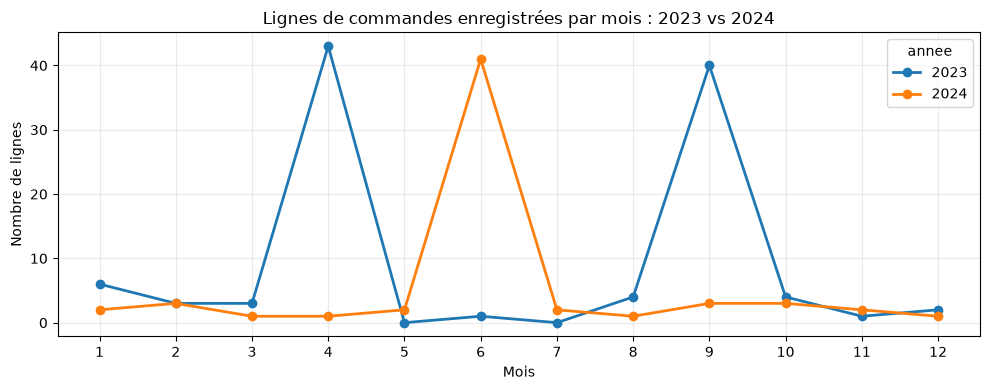

In [3]:
import matplotlib.pyplot as plt

# Toutes les dates brutes peuvent être interprétées en acceptant leurs formats différents.
dates = pd.to_datetime(commandes["order_date"], format="mixed", errors="coerce")
periode = pd.DataFrame({"annee": dates.dt.year, "mois": dates.dt.month})
mensuel = (
    periode[periode["annee"].isin([2023, 2024])]
    .groupby(["mois", "annee"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(1, 13), fill_value=0)
    .rename(columns={2023: "2023", 2024: "2024"})
)
mensuel.index.name = "mois"
print("Comparaison des lignes de commandes par mois")
display(mensuel)

nombre_2023 = int(mensuel["2023"].sum())
nombre_2024 = int(mensuel["2024"].sum())
print(f"Variation enregistrée : {nombre_2024 - nombre_2023:+d} lignes ({(nombre_2024 / nombre_2023 - 1) * 100:.1f} %)")
print(f"Part des lignes d'avril et septembre 2023 : {mensuel.loc[[4, 9], '2023'].sum() / nombre_2023:.1%}")

fig, ax = plt.subplots(figsize=(10, 4))
mensuel.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Lignes de commandes enregistrées par mois : 2023 vs 2024")
ax.set_xlabel("Mois")
ax.set_ylabel("Nombre de lignes")
ax.set_xticks(range(1, 13))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## Étape 4 — Cartographier les autres fichiers logistiques

**But :** comprendre le rôle des six autres tables avant tout nettoyage ou recherche d'anomalies. Nous les chargeons sans modifier les CSV et observons leur taille, leur granularité attendue et leurs références. Les identifiants indiqués sont des **clés candidates**, à vérifier ultérieurement.

In [4]:
# Vue d'ensemble des sept tables, avec les commandes déjà étudiées.
fichiers_logistiques = {
    "commandes": "purchase_order_lines.csv",
    "réceptions": "goods_receipts.csv",
    "expéditions": "shipments.csv",
    "stocks mensuels": "inventory_month_end.csv",
    "ajustements": "inventory_adjustments.csv",
    "partenaires": "erp_business_partners.csv",
    "établissements": "erp_facilities.csv",
}

# Une ligne peut représenter une commande, une réception, un tronçon d'expédition,
# un relevé mensuel de stock, un ajustement, un partenaire ou un établissement.
granularites = {
    "commandes": "ligne de commande",
    "réceptions": "ligne de réception",
    "expéditions": "tronçon d'expédition",
    "stocks mensuels": "site × mois × catégorie",
    "ajustements": "ajustement de stock",
    "partenaires": "partenaire ERP",
    "établissements": "établissement ERP",
}

logistique = {
    nom: pd.read_csv(root / "data/logistics" / fichier)
    for nom, fichier in fichiers_logistiques.items()
}
vue_ensemble = pd.DataFrame([
    {
        "table": nom,
        "lignes": len(df),
        "colonnes": len(df.columns),
        "granularite_presumee": granularites[nom],
        "valeurs_manquantes": int(df.isna().sum().sum()),
        "doublons_exacts": int(df.duplicated().sum()),
    }
    for nom, df in logistique.items()
])
print("Inventaire des sept fichiers CSV (sans nettoyage)")
display(vue_ensemble)



Inventaire des sept fichiers CSV (sans nettoyage)


,table,lignes,colonnes,granularite_presumee,valeurs_manquantes,doublons_exacts
0,commandes,651,16,ligne de commande,3,1
1,réceptions,612,12,ligne de réception,4,2
2,expéditions,452,16,tronçon d'expédition,17,2
3,stocks mensuels,502,11,site × mois × catégorie,0,2
4,ajustements,140,11,ajustement de stock,221,0
5,partenaires,80,11,partenaire ERP,15,0
6,établissements,30,11,établissement ERP,1,0


### Liens entre les tables : premier contrôle des références

On cherche si les identifiants de chaque table **existent** dans la table de référence. Ce n'est pas encore une jointure complète ni une preuve que chaque mouvement physique peut être reconstitué. Les références optionnelles manquantes sont comptées à part. Une commande et une expédition n'ont notamment pas de référence directe commune garantie.

In [5]:
correspondances = [
    ("Réceptions → commandes (numéro + ligne)", "réceptions", ["purchase_order_number", "purchase_order_line"], "commandes", ["purchase_order_number", "purchase_order_line"]),
    ("Commandes → fournisseurs", "commandes", ["supplier_partner_code"], "partenaires", ["partner_code"]),
    ("Commandes → établissements", "commandes", ["ordering_facility_code"], "établissements", ["facility_code"]),
    ("Réceptions → établissements", "réceptions", ["receiving_facility_code"], "établissements", ["facility_code"]),
    ("Expéditions → origines", "expéditions", ["origin_facility_code"], "établissements", ["facility_code"]),
    ("Expéditions → destinations", "expéditions", ["destination_facility_code"], "établissements", ["facility_code"]),
    ("Stocks mensuels → établissements", "stocks mensuels", ["facility_code"], "établissements", ["facility_code"]),
    ("Ajustements → établissements", "ajustements", ["facility_code"], "établissements", ["facility_code"]),
    ("Ajustements → réceptions (référence optionnelle)", "ajustements", ["related_receipt_number"], "réceptions", ["receipt_number"]),
    ("Ajustements → expéditions (référence optionnelle)", "ajustements", ["related_shipment_number"], "expéditions", ["shipment_number"]),
    ("Établissements → partenaire opérateur", "établissements", ["operating_partner_code"], "partenaires", ["partner_code"]),
]

def compter_references(source, colonnes_source, cible, colonnes_cible):
    complet = source[colonnes_source].notna().all(axis=1)
    cles_source = pd.MultiIndex.from_frame(source.loc[complet, colonnes_source])
    cles_cible = pd.MultiIndex.from_frame(cible[colonnes_cible].dropna().drop_duplicates())
    valides = int(cles_source.isin(cles_cible).sum())
    return int(complet.sum()), valides

bilan_liens = []
for titre, nom_source, cols_source, nom_cible, cols_cible in correspondances:
    src = logistique[nom_source]
    completes, trouvees = compter_references(src, cols_source, logistique[nom_cible], cols_cible)
    bilan_liens.append({
        "lien": titre,
        "lignes_source": len(src),
        "references_renseignees": completes,
        "references_trouvees": trouvees,
        "references_non_trouvees": completes - trouvees,
    })
print("Contrôle de présence des identifiants (sans modifier les données)")
display(pd.DataFrame(bilan_liens))


Contrôle de présence des identifiants (sans modifier les données)


,lien,lignes_source,references_renseignees,references_trouvees,references_non_trouvees
0,Réceptions → commandes (numéro + ligne),612,612,612,0
1,Commandes → fournisseurs,651,651,651,0
2,Commandes → établissements,651,651,651,0
3,Réceptions → établissements,612,612,612,0
4,Expéditions → origines,452,452,452,0
5,Expéditions → destinations,452,452,452,0
6,Stocks mensuels → établissements,502,502,502,0
7,Ajustements → établissements,140,140,140,0
8,Ajustements → réceptions (référence optionnelle),140,23,23,0
9,Ajustements → expéditions (référence optionnelle),140,37,37,0


### Contrôle ciblé — Quelles commandes n'ont pas de réception ?

La comparaison des nombres de lignes ne suffit pas : une commande peut comporter plusieurs lignes, et des lignes identiques peuvent être dupliquées. On raisonne donc sur les **clés uniques** `(purchase_order_number, purchase_order_line)` et on compare le **statut des commandes** avec l'existence d'une réception.

L'absence de réception dans le fichier n'est pas forcément un manquement : il faut distinguer les commandes terminées, en attente, retardées ou annulées. Aucun doublon n'est supprimé du fichier original.

In [6]:
cles_commande = ["purchase_order_number", "purchase_order_line"]
po = logistique["commandes"]
rcv = logistique["réceptions"]

commandes_uniques = po.drop_duplicates(subset=cles_commande)
receptions_uniques = rcv.drop_duplicates(subset=cles_commande)
comparaison = commandes_uniques.merge(
    receptions_uniques[cles_commande].assign(reception_presente=True),
    on=cles_commande,
    how="left",
    validate="one_to_one",
)
comparaison["reception_presente"] = comparaison["reception_presente"].eq(True)

print("Commandes sans réception enregistrée :", int((~comparaison["reception_presente"]).sum()))

print("\nStatut des commandes selon la présence d'une réception :")
bilan_statuts = pd.crosstab(
    comparaison["order_status"],
    comparaison["reception_presente"],
).rename(columns={False: "sans_reception", True: "avec_reception"})
display(bilan_statuts)


Commandes sans réception enregistrée : 40

Statut des commandes selon la présence d'une réception :


reception_presente,sans_reception,avec_reception
order_status,,
cancelled,8,0
completed,0,610
delayed,18,0
pending,14,0


## Phase 2 — Qualité des données : diagnostic avant nettoyage

Notre premier contrôle montre que les réceptions sont cohérentes avec les statuts des commandes. Cela **ne prouve pas** que toutes les colonnes sont propres. Avant de modifier quoi que ce soit, comptons les **doublons exacts** et localisons les **valeurs manquantes** dans les sept fichiers.

Une valeur manquante dans un champ facultatif (par exemple une référence d'expédition pour un ajustement sans lien avec une expédition) n'est pas forcément une erreur. Les fichiers source restent inchangés.

In [7]:
# Diagnostic minimal de qualité : une ligne par fichier, puis les colonnes incomplètes.
qualite = pd.DataFrame([
    {
        "fichier": nom,
        "lignes": len(df),
        "doublons_exacts": int(df.duplicated().sum()),
        "colonnes_avec_manquants": int(df.isna().any().sum()),
        "cellules_manquantes": int(df.isna().sum().sum()),
    }
    for nom, df in logistique.items()
])
print("Bilan qualité — aucun nettoyage effectué")
display(qualite)

manquants = pd.DataFrame([
    {"fichier": nom, "colonne": colonne, "manquants": int(nombre),
     "pourcentage_lignes": round(100 * nombre / len(df), 1)}
    for nom, df in logistique.items()
    for colonne, nombre in df.isna().sum().items()
    if nombre > 0
]).sort_values(["manquants", "fichier"], ascending=[False, True])
print("Détail des champs ayant des valeurs manquantes")
display(manquants)

print("Total de doublons exacts (toutes tables) :", int(qualite["doublons_exacts"].sum()))
print("Total de cellules manquantes (toutes tables) :", int(qualite["cellules_manquantes"].sum()))


Bilan qualité — aucun nettoyage effectué


,fichier,lignes,doublons_exacts,colonnes_avec_manquants,cellules_manquantes
0,commandes,651,1,1,3
1,réceptions,612,2,1,4
2,expéditions,452,2,1,17
3,stocks mensuels,502,2,0,0
4,ajustements,140,0,3,221
5,partenaires,80,0,2,15
6,établissements,30,0,1,1


Détail des champs ayant des valeurs manquantes


,fichier,colonne,manquants,pourcentage_lignes
4,ajustements,related_receipt_number,117,83.6
5,ajustements,related_shipment_number,103,73.6
2,expéditions,arrival_time,17,3.8
6,partenaires,external_registration_number,14,17.5
1,réceptions,inspection_status,4,0.7
0,commandes,declared_cost_center,3,0.5
3,ajustements,approved_by_role,1,0.7
7,partenaires,billing_region,1,1.2
8,établissements,storage_capabilities,1,3.3


Total de doublons exacts (toutes tables) : 7
Total de cellules manquantes (toutes tables) : 261


### Vérification ciblée — Dates d’arrivée manquantes dans les expéditions

**Question :** une date d’arrivée absente signifie-t-elle une mauvaise qualité des données, ou correspond-elle au statut de l’expédition ? On compare les statuts et la présence d'une date d'arrivée, **sans ajouter de date ni modifier les CSV**.

Nous vérifions également les dates de départ des expéditions concernées : un statut `in_transit` cohérent avec une date manquante ne démontre pas que le statut est encore à jour.

In [8]:
expeditions = logistique["expéditions"]
statut_normalise = expeditions["shipment_status"].astype("string").str.strip().str.lower()
sans_arrivee = expeditions["arrival_time"].isna()

print("Dates d'arrivée manquantes :", int(sans_arrivee.sum()), "/", len(expeditions))
print("Date d'arrivée manquante selon le statut (majuscules uniformisées pour l'affichage) :")
bilan_arrivees = pd.crosstab(statut_normalise, sans_arrivee).rename(
    columns={False: "date_presente", True: "date_manquante"}
)
display(bilan_arrivees)

expeditions_sans_arrivee = expeditions.loc[sans_arrivee, [
    "shipment_number", "dispatch_time", "shipment_status", "item_category"
]].copy()
departs = pd.to_datetime(expeditions_sans_arrivee["dispatch_time"], errors="coerce")
print("Exemples d'expéditions sans date d'arrivée :")
display(expeditions_sans_arrivee.head(6))


Dates d'arrivée manquantes : 17 / 452
Date d'arrivée manquante selon le statut (majuscules uniformisées pour l'affichage) :


arrival_time,date_presente,date_manquante
shipment_status,,
delayed,34,0
delivered,387,0
in_transit,0,17
returned,14,0


Exemples d'expéditions sans date d'arrivée :


,shipment_number,dispatch_time,shipment_status,item_category
39,SHP-2017-00005,2017-03-31T09:00:00,in_transit,transport_service
70,SHP-2018-00017,2018-04-10T12:00:00,in_transit,protective_equipment
82,SHP-2018-00029,2018-04-23T11:00:00,in_transit,protective_equipment
96,SHP-2018-00043,2018-10-19T15:00:00,in_transit,cold_storage_equipment
104,SHP-2019-00004,2019-04-18T14:00:00,in_transit,office_supply
105,SHP-2019-00005,2019-04-19T09:00:00,in_transit,consulting_service


### Piste conservée pour l’étape 5 — Anomalies temporelles des expéditions

**Observation vérifiée :** 17 expéditions ont une date d’arrivée absente et un statut `in_transit`. Les départs enregistrés vont du **31 mars 2017 au 1er mai 2025**. L’absence de date d’arrivée est cohérente avec le statut, mais des expéditions anciennes toujours indiquées « en transit » méritent une enquête.

**Hypothèses à vérifier ultérieurement :** statuts non mis à jour, événements de livraison/retour non enregistrés, ou particularité de la période de couverture des données. **Aucune cause n’est démontrée** à ce stade ; on ne transforme ni ne corrige ces lignes.

**À faire à l’étape 5 :** établir la date de référence/couverture du jeu de données, calculer l’ancienneté des expéditions encore `in_transit`, rechercher d’éventuelles autres étapes sous le même numéro d’expédition et confronter leurs traces (réceptions, ajustements, mémos, dossiers réglementaires), si des références permettent le rapprochement.

### Étape 2 — Diagnostic des doublons exacts

On vérifie les **7 lignes répétées** identifiées dans les sept fichiers : références concernées, positions dans les CSV et éventuelles différences entre lignes portant une même clé. Un doublon « exact » répète **toutes** les colonnes, à distinguer de plusieurs événements légitimes ayant des identifiants communs.

**Méthode :** diagnostic uniquement. On ne supprime rien des données originales et on attend l'interprétation avant de définir un éventuel traitement sur une copie.

In [9]:
# Clés candidates utilisées seulement pour comparer les doublons par identifiant.
cles_doublons = {
    "commandes": ["purchase_order_number", "purchase_order_line"],
    "réceptions": ["receipt_number"],
    "expéditions": ["shipment_number", "shipment_leg"],
    "stocks mensuels": ["facility_code", "reporting_month", "item_category"],
}

resume_doublons = []
details_doublons = []
for nom, cles in cles_doublons.items():
    df = logistique[nom]
    masque = df.duplicated(keep=False)
    subset = df.loc[masque].copy()
    subset["ligne_csv"] = subset.index + 2  # +1 : index zéro, +1 : en-tête du CSV
    groupes = subset.groupby(list(df.columns), dropna=False, sort=False)
    for _, groupe in groupes:
        infos = {"fichier": nom}
        infos.update({cle: groupe.iloc[0][cle] for cle in cles})
        infos["lignes_csv"] = ", ".join(map(str, sorted(groupe["ligne_csv"].tolist())))
        infos["repetitions_en_trop"] = len(groupe) - 1
        details_doublons.append(infos)
    doublons_cles = int(df.duplicated(subset=cles).sum())
    doublons_exacts = int(df.duplicated().sum())
    resume_doublons.append({
        "fichier": nom,
        "doublons_exacts": doublons_exacts,
        "doublons_de_cle": doublons_cles,
        "meme_cle_donnees_differentes": doublons_cles - doublons_exacts,
    })

print("Bilan des répétitions (une ligne dupliquée comptée une seule fois en trop) :")
display(pd.DataFrame(resume_doublons))
print("Occurrences exactes et leurs positions dans les fichiers CSV :")
display(pd.DataFrame(details_doublons).fillna(""))
print("Nombre total de lignes en trop dans les sept CSV :", sum(df.duplicated().sum() for df in logistique.values()))


Bilan des répétitions (une ligne dupliquée comptée une seule fois en trop) :


,fichier,doublons_exacts,doublons_de_cle,meme_cle_donnees_differentes
0,commandes,1,1,0
1,réceptions,2,2,0
2,expéditions,2,2,0
3,stocks mensuels,2,2,0


Occurrences exactes et leurs positions dans les fichiers CSV :


,fichier,purchase_order_number,purchase_order_line,lignes_csv,repetitions_en_trop,receipt_number,shipment_number,shipment_leg,facility_code,reporting_month,item_category
0,commandes,PO-2022-00022,1.0,"350, 652",1,,,,,,
1,réceptions,,,"37, 613",1,RCV-2016-00036,,,,,
2,réceptions,,,"320, 612",1,RCV-2022-00319,,,,,
3,expéditions,,,"28, 453",1,,SHP-2016-00009,1.0,,,
4,expéditions,,,"253, 452",1,,SHP-2022-00017,1.0,,,
5,stocks mensuels,,,"172, 503",1,,,,FCL-1019,2021-05-01,protective_equipment
6,stocks mensuels,,,"286, 502",1,,,,FCL-1020,2019-08-01,agricultural_product


Nombre total de lignes en trop dans les sept CSV : 7


### Étape 2 — Nettoyage validé : suppression des doublons exacts

**Décision prise après vérification :** les 7 répétitions intégrales n'apportent aucune information supplémentaire. Elles peuvent provoquer des doubles comptages. On les enlève **uniquement des copies de travail** et on conserve toutes les lignes d'origine.

Organisation reprise de RailGuard :

- `data/logistics/` : source officielle du professeur, conservée **inchangée** ;
- `data/raw/logistics/` : copie fidèle des CSV originaux, contrôlée par SHA-256 ;
- `data/interim/logistics/` : CSV sans doublons exacts, aucune autre transformation ;
- `data/processed/logistics/` : réservé aux transformations suivantes, **vide pour l'instant**.

Le script reproductible `investigations/05_logistique/build_data.py` permet de reconstruire les données `interim` sans modifier les originaux. Les colonnes, les formats textuels, les valeurs manquantes et les unités sont préservés pour l'instant.

In [10]:
import json
import subprocess
import sys

# Transformation reproductible, limitée aux doublons exacts.
pipeline = root / "investigations" / "05_logistique" / "build_data.py"
execution = subprocess.run(
    [sys.executable, str(pipeline)],
    capture_output=True,
    text=True,
    check=True,
)

# Manifest des contrôles : permet de vérifier les lignes et les empreintes.
manifest = json.loads((root / "data/interim/logistics/manifest.json").read_text(encoding="utf-8"))
bilan_nettoyage = pd.DataFrame(manifest["fichiers"])[
    ["fichier", "lignes_raw", "doublons_retires", "lignes_interim"]
]
print("Bilan du nettoyage validé")
display(bilan_nettoyage)
# L'étape de déduplication ne modifie pas processed ; cette zone peut désormais
# être remplie par l'étape ultérieure de normalisation (cellules ci-dessous).


Bilan du nettoyage validé


,fichier,lignes_raw,doublons_retires,lignes_interim
0,purchase_order_lines.csv,651,1,650
1,goods_receipts.csv,612,2,610
2,shipments.csv,452,2,450
3,inventory_month_end.csv,502,2,500
4,inventory_adjustments.csv,140,0,140
5,erp_business_partners.csv,80,0,80
6,erp_facilities.csv,30,0,30


### Étape 2 — Diagnostic des formats numériques et des unités

Les doublons exacts ont été retirés dans `interim`. Nous cherchons maintenant quelles **colonnes censées contenir des nombres** ont un format différent : nombres ordinaires avec point, nombres avec virgule décimale, nombres suivis de leur unité, champs vides ou formats inconnus.

**Important :** on travaille sur `data/interim/logistics/`, en lisant les colonnes comme des chaînes, sans corriger, arrondir, convertir ou modifier les fichiers. On vérifie aussi que les unités éventuellement incluses dans le nombre sont identiques à celles de la colonne d'unité dédiée.

In [11]:
import re

colonnes_numeriques = {
    "purchase_order_lines.csv": ("ordered_unit", ["ordered_quantity", "unit_price"]),
    "goods_receipts.csv": ("received_unit", ["received_quantity"]),
    "shipments.csv": ("declared_unit", ["declared_quantity"]),
    "inventory_month_end.csv": ("unit", [
        "opening_stock", "received_quantity", "outgoing_quantity",
        "documented_internal_use", "documented_waste", "closing_stock",
    ]),
    "inventory_adjustments.csv": ("unit", ["adjustment_quantity"]),
}

nombre_standard = re.compile(r"^[+-]?\d+(?:\.\d+)?$")
nombre_virgule = re.compile(r"^[+-]?\d+,\d+$")
nombre_unite = re.compile(r"^([+-]?\d+(?:[.,]\d+)?)\s+([A-Za-z_][\w-]*)$")

def type_format(texte):
    texte = str(texte).strip()
    if not texte:
        return "vide"
    if nombre_standard.fullmatch(texte):
        return "standard"
    if nombre_virgule.fullmatch(texte):
        return "virgule_decimale"
    if nombre_unite.fullmatch(texte):
        return "nombre_avec_unite"
    return "autre_format"

bilan_formats = []
exemples_formats = []
conflits_unites = []
for fichier, (colonne_unite, colonnes) in colonnes_numeriques.items():
    df = pd.read_csv(root / "data/interim/logistics" / fichier, dtype=str, keep_default_na=False)
    for colonne in colonnes:
        types = df[colonne].map(type_format)
        effectifs = types.value_counts()
        bilan_formats.append({
            "fichier": fichier,
            "colonne": colonne,
            "standard": int(effectifs.get("standard", 0)),
            "virgule_decimale": int(effectifs.get("virgule_decimale", 0)),
            "nombre_avec_unite": int(effectifs.get("nombre_avec_unite", 0)),
            "vide": int(effectifs.get("vide", 0)),
            "autre_format": int(effectifs.get("autre_format", 0)),
        })
        atypiques = df.loc[types.ne("standard"), [colonne, colonne_unite]]
        for _, ligne in atypiques.iterrows():
            texte = ligne[colonne].strip()
            match = nombre_unite.fullmatch(texte)
            if match and match.group(2) != ligne[colonne_unite].strip():
                conflits_unites.append((fichier, colonne, texte, ligne[colonne_unite]))
        for typ in ("virgule_decimale", "nombre_avec_unite", "autre_format", "vide"):
            vals = df.loc[types.eq(typ), colonne].drop_duplicates().head(3).tolist()
            if vals:
                exemples_formats.append({"fichier": fichier, "colonne": colonne, "type": typ, "exemples": ", ".join(vals)})

rapport_formats = pd.DataFrame(bilan_formats)
print("Format des valeurs des colonnes numériques potentielles :")
display(rapport_formats)
print("Exemples de formats atypiques :")
display(pd.DataFrame(exemples_formats))
print("Autres formats non reconnus :", int(rapport_formats.autre_format.sum()))
print("Conflits entre unités intégrées et unités des colonnes dédiées :", len(conflits_unites))
print("Diagnostic uniquement : aucun fichier interim/processed n'a été modifié.")


Format des valeurs des colonnes numériques potentielles :


,fichier,colonne,standard,virgule_decimale,nombre_avec_unite,vide,autre_format
0,purchase_order_lines.csv,ordered_quantity,642,0,8,0,0
1,purchase_order_lines.csv,unit_price,644,6,0,0,0
2,goods_receipts.csv,received_quantity,596,6,8,0,0
3,shipments.csv,declared_quantity,450,0,0,0,0
4,inventory_month_end.csv,opening_stock,496,0,4,0,0
5,inventory_month_end.csv,received_quantity,497,3,0,0,0
6,inventory_month_end.csv,outgoing_quantity,497,3,0,0,0
7,inventory_month_end.csv,documented_internal_use,500,0,0,0,0
8,inventory_month_end.csv,documented_waste,498,2,0,0,0
9,inventory_month_end.csv,closing_stock,496,0,4,0,0


Exemples de formats atypiques :


,fichier,colonne,type,exemples
0,purchase_order_lines.csv,ordered_quantity,nombre_avec_unite,"88 case, 1 service, 24 pack"
1,purchase_order_lines.csv,unit_price,virgule_decimale,"2469,48, 2474,89, 563,83"
2,goods_receipts.csv,received_quantity,virgule_decimale,"56,41, 0,88, 69,37"
3,goods_receipts.csv,received_quantity,nombre_avec_unite,"14 kit, 28 case, 36 pack"
4,inventory_month_end.csv,opening_stock,nombre_avec_unite,"14.55 sealed_lot, 22.79 kit, 75.12 kit"
5,inventory_month_end.csv,received_quantity,virgule_decimale,"1,04, 5,42, 5,51"
6,inventory_month_end.csv,outgoing_quantity,virgule_decimale,"17,00, 0,00, 2,97"
7,inventory_month_end.csv,documented_waste,virgule_decimale,"1,45, 1,29"
8,inventory_month_end.csv,closing_stock,nombre_avec_unite,"0.92 sealed_lot, 74.59 case, 45.75 pallet"
9,inventory_adjustments.csv,adjustment_quantity,nombre_avec_unite,-2.9 case


Autres formats non reconnus : 0
Conflits entre unités intégrées et unités des colonnes dédiées : 0
Diagnostic uniquement : aucun fichier interim/processed n'a été modifié.


### Étape 2 — Transformation validée : créer des valeurs numériques propres

**Règles approuvées :** remplacer les virgules décimales par un point et retirer les unités intégrées aux quantités **uniquement lorsque l'unité correspond à la colonne dédiée**. Le signe des nombres négatifs est conservé.

**Traçabilité :** les 7 fichiers de `data/interim/logistics/` ne changent pas ; une étape intermédiaire numérique est produite dans `data/interim/logistics_numeric/`. Toutes les colonnes d'origine sont préservées ; seules des colonnes supplémentaires `*_numeric` sont créées pour les nombres normalisés. Les unités, les catégories et les devises ne sont **pas converties**. Les fichiers sont générés par `normalize_numeric.py` et contrôlés avec un manifeste d'empreintes. Les dates et les catégories seront transformées séparément dans `processed`.

Ce traitement sert à préparer des valeurs calculables ; il ne constitue pas encore une analyse d'anomalies ni une validation de la cohérence des stocks.

In [12]:
# Pipeline reproductible de normalisation : lit interim et écrit interim/logistics_numeric.
normalisation = root / "investigations" / "05_logistique" / "normalize_numeric.py"
resultat = subprocess.run(
    [sys.executable, str(normalisation)],
    text=True, capture_output=True, check=True,
)
print(resultat.stdout)

manifest_numerique = json.loads((root / "data/interim/logistics_numeric/numeric_manifest.json").read_text(encoding="utf-8"))
rapport_normalisation = pd.DataFrame(manifest_numerique["fichiers"])[
    ["fichier", "lignes", "colonnes_numeriques_ajoutees", "virgules_decimales", "nombres_avec_unite"]
]
display(rapport_normalisation)

# Exemples concrets dans le fichier processed, sans perdre les colonnes sources.
commandes_numeriques = pd.read_csv(root / "data/interim/logistics_numeric/purchase_order_lines.csv")
exemples_quantites = commandes_numeriques.loc[
    commandes_numeriques["ordered_quantity"].astype(str).str.contains(" ", regex=False),
    ["ordered_quantity", "ordered_unit", "ordered_quantity_numeric"],
].head(3)
exemples_prix = commandes_numeriques.loc[
    commandes_numeriques["unit_price"].astype(str).str.contains(",", regex=False),
    ["unit_price", "currency", "unit_price_numeric"],
].head(3)
print("Exemples de quantités : original → valeur numérique")
display(exemples_quantites)

# Confirmer qu'une bibliothèque de calcul lit ces nouvelles colonnes comme nombres.


purchase_order_lines.csv: 650 lignes, 2 colonnes numériques ajoutées
goods_receipts.csv: 610 lignes, 1 colonnes numériques ajoutées
shipments.csv: 450 lignes, 1 colonnes numériques ajoutées
inventory_month_end.csv: 500 lignes, 6 colonnes numériques ajoutées
inventory_adjustments.csv: 140 lignes, 1 colonnes numériques ajoutées
erp_business_partners.csv: 80 lignes, 0 colonnes numériques ajoutées
erp_facilities.csv: 30 lignes, 0 colonnes numériques ajoutées
Virgules décimales traitées : 20
Nombres avec unité traités : 25
Aucune colonne d'origine ni aucun fichier raw/interim modifié.



,fichier,lignes,colonnes_numeriques_ajoutees,virgules_decimales,nombres_avec_unite
0,purchase_order_lines.csv,650,2,6,8
1,goods_receipts.csv,610,1,6,8
2,shipments.csv,450,1,0,0
3,inventory_month_end.csv,500,6,8,8
4,inventory_adjustments.csv,140,1,0,1
5,erp_business_partners.csv,80,0,0,0
6,erp_facilities.csv,30,0,0,0


Exemples de quantités : original → valeur numérique


,ordered_quantity,ordered_unit,ordered_quantity_numeric
87,88 case,case,88
100,1 service,service,1
176,24 pack,pack,24


### Étape 2 — Diagnostic des dates et catégories (aucune transformation)

**Objectif :** vérifier les formats de dates dans les sept fichiers dédupliqués, puis identifier les catégories dont seule la casse varie. On distingue le **format** (présentation) de la **valeur réelle** (sens). Nous ne modifions aucune date, catégorie ou statut à ce stade.

Particularité importante : `AAAA/MM/JJ` doit être interprété comme *année/mois/jour* et ne doit pas être soumis à un parseur qui inverse arbitrairement le mois et le jour. Les dates de type `JJ/MM/AAAA` dont le jour et le mois sont tous deux ≤ 12 restent à documenter avant de fixer une convention.

In [13]:
from datetime import datetime

# Reconnaissance explicite des formats : éviter les interprétations implicites.
formats_date = [
    ("ISO date", re.compile(r"^\d{4}-\d{2}-\d{2}$"), "%Y-%m-%d"),
    ("ISO heure", re.compile(r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}$"), "%Y-%m-%dT%H:%M:%S"),
    ("AAAA/MM/JJ", re.compile(r"^\d{4}/\d{2}/\d{2}$"), "%Y/%m/%d"),
    ("AAAA/MM/JJ heure", re.compile(r"^\d{4}/\d{2}/\d{2} \d{2}:\d{2}:\d{2}$"), "%Y/%m/%d %H:%M:%S"),
    ("JJ/MM/AAAA", re.compile(r"^\d{1,2}/\d{1,2}/\d{4}$"), "%d/%m/%Y"),
    ("JJ/MM/AAAA heure", re.compile(r"^\d{1,2}/\d{1,2}/\d{4} \d{2}:\d{2}:\d{2}$"), "%d/%m/%Y %H:%M:%S"),
    ("JJ-Mois-AAAA", re.compile(r"^\d{1,2}-[A-Za-z]{3}-\d{4}$"), "%d-%b-%Y"),
    ("JJ-Mois-AAAA heure", re.compile(r"^\d{1,2}-[A-Za-z]{3}-\d{4} \d{2}:\d{2}:\d{2}$"), "%d-%b-%Y %H:%M:%S"),
]

def decrire_date(valeur):
    if not valeur.strip():
        return "manquante", False, False
    for etiquette, expression, pattern in formats_date:
        if expression.fullmatch(valeur.strip()):
            try:
                datetime.strptime(valeur.strip(), pattern)
                ambigue = etiquette.startswith("JJ/MM/AAAA") and all(
                    1 <= int(x) <= 12 for x in valeur.split(" ")[0].split("/")[:2]
                ) and valeur.split(" ")[0].split("/")[0] != valeur.split(" ")[0].split("/")[1]
                return etiquette, True, ambigue
            except ValueError:
                return "date invalide", False, False
    return "format inconnu", False, False

resume_dates = []
formats_exceptionnels = []
for fichier in fichiers_logistiques.values():
    df = pd.read_csv(root / "data/interim/logistics" / fichier, dtype=str, keep_default_na=False)
    colonnes_dates = [col for col in df if col.endswith(("_date", "_time")) or col == "reporting_month"]
    for col in colonnes_dates:
        classification = df[col].map(decrire_date)
        serie_format = classification.map(lambda x: x[0])
        resume_dates.append({
            "fichier": fichier,
            "colonne": col,
            "formats_differents_standard": int((~serie_format.isin(["ISO date", "ISO heure", "manquante"])).sum()),
            "dates_manquantes": int(serie_format.eq("manquante").sum()),
            "dates_invalides": int((~classification.map(lambda x: x[1]) & ~serie_format.eq("manquante")).sum()),
            "JJ_MM_AAAA_ambigues": int(classification.map(lambda x: x[2]).sum()),
        })
        for i, valeur in df[col].items():
            etiquette, valide, ambigu = classification.iloc[i]
            if etiquette not in ("ISO date", "ISO heure", "manquante"):
                formats_exceptionnels.append({
                    "fichier": fichier, "colonne": col, "ligne_interim": i + 2,
                    "valeur": valeur, "format": etiquette, "jour_mois_ambigu": ambigu,
                })

resume_dates_df = pd.DataFrame(resume_dates)
exceptions_dates_df = pd.DataFrame(formats_exceptionnels)
print("Dates : bilan par colonne")
display(resume_dates_df)
print("Exemples et valeurs des formats atypiques")
display(exceptions_dates_df)

colonnes_categorielles = ("category", "status", "class", "role", "reason")
variantes_categories = []
for fichier in fichiers_logistiques.values():
    df = pd.read_csv(root / "data/interim/logistics" / fichier, dtype=str, keep_default_na=False)
    for col in [c for c in df if any(mot in c for mot in colonnes_categorielles)]:
        valeurs = df[col].astype(str).str.strip()
        uniformisees = valeurs.str.casefold()
        for cle, groupes in pd.DataFrame({"original": valeurs, "cle": uniformisees}).groupby("cle"):
            ecritures = sorted(groupes.original.unique())
            if len(ecritures) > 1:
                variantes_categories.append({
                    "fichier": fichier, "colonne": col,
                    "categorie_commune": cle,
                    "ecritures": " / ".join(ecritures),
                    "lignes_concernees": len(groupes),
                })
print("Groupes de libellés concernés :", len(variantes_categories))


Dates : bilan par colonne


,fichier,colonne,formats_differents_standard,dates_manquantes,dates_invalides,JJ_MM_AAAA_ambigues
0,purchase_order_lines.csv,order_date,3,0,0,0
1,purchase_order_lines.csv,requested_delivery_date,3,0,0,0
2,goods_receipts.csv,receipt_date,5,0,0,1
3,shipments.csv,dispatch_time,3,0,0,0
4,shipments.csv,arrival_time,3,17,0,0
5,inventory_month_end.csv,reporting_month,0,0,0,0
6,inventory_adjustments.csv,adjustment_date,2,0,0,1
7,erp_business_partners.csv,onboarding_date,1,0,0,1
8,erp_facilities.csv,opening_date,0,0,0,0


Exemples et valeurs des formats atypiques


,fichier,colonne,ligne_interim,valeur,format,jour_mois_ambigu
0,purchase_order_lines.csv,order_date,386,2022/10/01,AAAA/MM/JJ,False
1,purchase_order_lines.csv,order_date,448,10-Apr-2023,JJ-Mois-AAAA,False
2,purchase_order_lines.csv,order_date,523,2023/10/23,AAAA/MM/JJ,False
3,purchase_order_lines.csv,requested_delivery_date,103,26/04/2018,JJ/MM/AAAA,False
4,purchase_order_lines.csv,requested_delivery_date,150,29-Jul-2019,JJ-Mois-AAAA,False
5,purchase_order_lines.csv,requested_delivery_date,348,2022/02/17,AAAA/MM/JJ,False
6,goods_receipts.csv,receipt_date,226,2020/05/02,AAAA/MM/JJ,False
7,goods_receipts.csv,receipt_date,444,2023/09/03,AAAA/MM/JJ,False
8,goods_receipts.csv,receipt_date,529,12/07/2024,JJ/MM/AAAA,True
9,goods_receipts.csv,receipt_date,570,2025/06/11,AAAA/MM/JJ,False


Groupes de libellés concernés : 15


### Étape 2 — Transformation validée : dates et catégories

Nous appliquons les règles établies pendant le diagnostic :

- dates standardisées en **ISO** dans de nouvelles colonnes `*_normalized`, avec une colonne `*_parse_status` qui explique leur interprétation ; les dates d'origine restent intactes ;
- **17 dates atypiques non ambiguës** reformatées ; **3 dates `JJ/MM/AAAA` réellement ambiguës laissées sans valeur normalisée** et listées avec leurs deux interprétations possibles dans le manifeste. Les 17 dates d'arrivée absentes restent absentes ;
- libellés harmonisés en minuscules pour **sept colonnes catégorielles**, comprenant **15 groupes d'écritures différentes** ; les valeurs d'origine restent disponibles ;
- conservation des colonnes numériques précédemment calculées, sans conversion d'unités ni de devises.

Les fichiers finaux sont écrits dans `data/processed/logistics/` par `normalize_dates_categories.py`, à partir de l'étape numérique intermédiaire. Il ne s'agit **pas** de corriger les événements logistiques, mais seulement leur représentation.

In [14]:
# Étape finale de la normalisation : lire l'interim numérique et produire processed.
script_dates_categories = root / "investigations/05_logistique/normalize_dates_categories.py"
execution_dates_categories = subprocess.run(
    [sys.executable, str(script_dates_categories)],
    capture_output=True, text=True, check=True,
)

manifest_processed = json.loads(
    (root / "data/processed/logistics/processed_manifest.json").read_text(encoding="utf-8")
)
rapport_dates_categories = pd.DataFrame([
    {
        "fichier": ligne["fichier"],
        "dates_reformatees": ligne["dates"]["reformatted"],
        "dates_ambigues": ligne["dates"]["ambiguous_day_month"],
        "dates_absentes": ligne["dates"]["missing"],
        "groupes_de_variantes": sum(
            categorie["groupes_variants_casse"] for categorie in ligne["categories"]
        ),
    }
    for ligne in manifest_processed["fichiers"]
])
print("Bilan des normalisations :")
display(rapport_dates_categories)
print("Trois dates conservées comme incertaines :")
display(pd.DataFrame(manifest_processed["dates_ambigues"]))

# Deux contrôles illustratifs, sans altérer la donnée source.
expeditions_processed = pd.read_csv(
    root / "data/processed/logistics/shipments.csv", dtype=str, keep_default_na=False
)
print("✓ Dates, catégories et valeurs sources préservées ; ambiguïtés documentées.")


Bilan des normalisations :


,fichier,dates_reformatees,dates_ambigues,dates_absentes,groupes_de_variantes
0,purchase_order_lines.csv,6,0,0,5
1,goods_receipts.csv,4,1,0,1
2,shipments.csv,6,0,17,5
3,inventory_month_end.csv,0,0,0,2
4,inventory_adjustments.csv,1,1,0,1
5,erp_business_partners.csv,0,1,0,1
6,erp_facilities.csv,0,0,0,0


Trois dates conservées comme incertaines :


,fichier,colonne,ligne_interim,valeur_brute,candidat_JJ_MM,candidat_MM_JJ
0,goods_receipts.csv,receipt_date,529,12/07/2024,2024-07-12,2024-12-07
1,inventory_adjustments.csv,adjustment_date,109,12/11/2023,2023-11-12,2023-12-11
2,erp_business_partners.csv,onboarding_date,22,01/10/2003,2003-10-01,2003-01-10


✓ Dates, catégories et valeurs sources préservées ; ambiguïtés documentées.


### Étape 2 — Valeurs manquantes : analyse contextuelle (sans imputation)

**Question :** les champs vides sont-ils attendus pour le type d'enregistrement, ou indiquent-ils une information incomplète ? On ne doit ni assimiler toutes les valeurs vides à des erreurs, ni les compléter arbitrairement.

Le calcul porte **uniquement sur les colonnes brutes d'origine** présentes dans les CSV `processed`. Les colonnes techniques ajoutées (`*_numeric`, `*_normalized`, `*_parse_status`) ne comptent pas comme des données sources ; les trois dates normalisées volontairement vides à cause d'une ambiguïté restent documentées dans le manifeste des dates.

*Lecture provisoire :* les références de réception/expédition dans les ajustements sont des rattachements qui peuvent être absents ; les dates d'arrivée manquantes concordent avec le statut `in_transit` mais les événements anciens sont conservés pour l'étape 5. Les autres manques doivent être appréciés selon leur rôle (inspection, approbation, centre de coûts, etc.). **Aucune valeur n'est imputée dans cette étape.**

In [15]:
# Contrôle des seuls champs sources avec le dictionnaire officiel.
dictionnaire = pd.read_csv(root / "data/data_dictionary.csv", dtype=str, keep_default_na=False)
champs_par_fichier = {
    fichier: groupe["field_name"].tolist()
    for fichier, groupe in dictionnaire.groupby("file_name")
}

rapport_manquants = []
for fichier in fichiers_logistiques.values():
    df = pd.read_csv(root / "data/processed/logistics" / fichier,
                     dtype=str, keep_default_na=False)
    for champ in champs_par_fichier[fichier]:
        nb_vide = int(df[champ].str.strip().eq("").sum())
        if nb_vide:
            rapport_manquants.append({
                "fichier": fichier,
                "champ": champ,
                "valeurs_vides": nb_vide,
                "part_lignes_%": round(100 * nb_vide / len(df), 1),
            })
rapport_manquants_df = pd.DataFrame(rapport_manquants).sort_values(
    "valeurs_vides", ascending=False
).reset_index(drop=True)
print("Valeurs manquantes par champ (colonnes officielles uniquement) :")
display(rapport_manquants_df)

ajustements_propres = pd.read_csv(
    root / "data/processed/logistics/inventory_adjustments.csv",
    dtype=str, keep_default_na=False,
)
ref_reception = ajustements_propres["related_receipt_number"].ne("")
ref_expedition = ajustements_propres["related_shipment_number"].ne("")
liens_ajustements = pd.DataFrame([{
    "aucune_reference": int((~ref_reception & ~ref_expedition).sum()),
    "seulement_reception": int((ref_reception & ~ref_expedition).sum()),
    "seulement_expedition": int((~ref_reception & ref_expedition).sum()),
    "les_deux": int((ref_reception & ref_expedition).sum()),
}])
print("Rattachements de nos 140 ajustements :")
display(liens_ajustements)

partenaires_propres = pd.read_csv(
    root / "data/processed/logistics/erp_business_partners.csv",
    dtype=str, keep_default_na=False,
)
receptions_propres = pd.read_csv(
    root / "data/processed/logistics/goods_receipts.csv",
    dtype=str, keep_default_na=False,
)
commandes_propres = pd.read_csv(
    root / "data/processed/logistics/purchase_order_lines.csv",
    dtype=str, keep_default_na=False,
)
expeditions_propres = pd.read_csv(
    root / "data/processed/logistics/shipments.csv",
    dtype=str, keep_default_na=False,
)

situations_a_verifier = pd.DataFrame([
    {"cas": "Réceptions posted sans statut d'inspection", "effectif": int((receptions_propres.inspection_status.eq("") & receptions_propres.receipt_status_normalized.eq("posted")).sum())},
    {"cas": "Ajustements posted sans rôle d'approbation", "effectif": int((ajustements_propres.approved_by_role.eq("") & ajustements_propres.adjustment_status.eq("posted")).sum())},
    {"cas": "Commandes completed sans centre de coûts", "effectif": int((commandes_propres.declared_cost_center.eq("") & commandes_propres.order_status.eq("completed")).sum())},
    {"cas": "Partenaires customer sans numéro d'enregistrement externe", "effectif": int((partenaires_propres.external_registration_number.eq("") & partenaires_propres.partner_role_normalized.eq("customer")).sum())},
    {"cas": "Partenaires supplier sans région de facturation", "effectif": int((partenaires_propres.billing_region.eq("") & partenaires_propres.partner_role_normalized.eq("supplier")).sum())},
    {"cas": "Expéditions in_transit sans arrivée (piste étape 5)", "effectif": int((expeditions_propres.arrival_time.eq("") & expeditions_propres.shipment_status_normalized.eq("in_transit")).sum())},
])


Valeurs manquantes par champ (colonnes officielles uniquement) :


,fichier,champ,valeurs_vides,part_lignes_%
0,inventory_adjustments.csv,related_receipt_number,117,83.6
1,inventory_adjustments.csv,related_shipment_number,103,73.6
2,shipments.csv,arrival_time,17,3.8
3,erp_business_partners.csv,external_registration_number,14,17.5
4,goods_receipts.csv,inspection_status,4,0.7
5,purchase_order_lines.csv,declared_cost_center,3,0.5
6,inventory_adjustments.csv,approved_by_role,1,0.7
7,erp_business_partners.csv,billing_region,1,1.2
8,erp_facilities.csv,storage_capabilities,1,3.3


Rattachements de nos 140 ajustements :


,aucune_reference,seulement_reception,seulement_expedition,les_deux
0,85,18,32,5


### Étape 2 — Décision sur les valeurs manquantes

**Décision validée : ne rien imputer.** Les références de rattachement absentes dans les ajustements ne sont pas nécessairement des erreurs ; les 17 dates d’arrivée manquantes correspondent toutes au statut `in_transit` (ancienneté à reprendre en étape 5). Quatre réceptions sans statut d’inspection, un ajustement enregistré sans rôle d’approbation et d’autres informations documentaires incomplètes sont **conservés et signalés** ; cela ne démontre ni l’absence d’inspection ni un défaut d’autorisation.

La suite est un **contrôle structurel** des identifiants et unités, pas une analyse des flux ni une correction de stock.

### Étape 2 — Vérification des identifiants et des unités

À partir des **clés officielles** définies dans `data_dictionary.csv`, vérifier l’unicité, les champs de clé manquants et les références existantes dans les autres tables. Pour les unités, comparer chaque réception à sa ligne de commande, puis tester la stabilité des unités par établissement–catégorie dans les inventaires mensuels.

**Limite :** une référence existante ne garantit pas une livraison correcte ; une unité cohérente ne prouve pas la conservation des stocks. Les calculs de traçabilité et de conservation relèvent des étapes 3 et 4.

In [16]:
# Contrôles de qualité sur les fichiers processed, sans modification.
donnees_qualite = {
    fichier: pd.read_csv(root / "data/processed/logistics" / fichier,
                         dtype=str, keep_default_na=False)
    for fichier in fichiers_logistiques.values()
}
cles_officielles = dictionnaire.loc[
    dictionnaire["file_name"].isin(donnees_qualite)
    & dictionnaire["key_role"].eq("primary_or_composite_key"),
    ["file_name", "field_name"],
].groupby("file_name")["field_name"].apply(list)

bilan_cles = []
for fichier, df in donnees_qualite.items():
    champs = cles_officielles[fichier]
    bilan_cles.append({
        "fichier": fichier,
        "cle_officielle": " + ".join(champs),
        "cles_vides": int(df[champs].eq("").any(axis=1).sum()),
        "doublons_cle": int(df.duplicated(subset=champs).sum()),
    })
print("Unicité des clés officielles :")
display(pd.DataFrame(bilan_cles))

partenaires_ref = donnees_qualite["erp_business_partners.csv"]
etablissements_ref = donnees_qualite["erp_facilities.csv"]
commandes_ref = donnees_qualite["purchase_order_lines.csv"]
receptions_ref = donnees_qualite["goods_receipts.csv"]
expeditions_ref = donnees_qualite["shipments.csv"]
stocks_ref = donnees_qualite["inventory_month_end.csv"]
ajustements_ref = donnees_qualite["inventory_adjustments.csv"]

liens_a_controler = [
    ("Commandes : fournisseur", commandes_ref, "supplier_partner_code", partenaires_ref, "partner_code"),
    ("Commandes : établissement", commandes_ref, "ordering_facility_code", etablissements_ref, "facility_code"),
    ("Réceptions : fournisseur", receptions_ref, "supplier_partner_code", partenaires_ref, "partner_code"),
    ("Réceptions : établissement", receptions_ref, "receiving_facility_code", etablissements_ref, "facility_code"),
    ("Expéditions : émetteur", expeditions_ref, "sender_partner_code", partenaires_ref, "partner_code"),
    ("Expéditions : destinataire", expeditions_ref, "receiver_partner_code", partenaires_ref, "partner_code"),
    ("Expéditions : transporteur", expeditions_ref, "carrier_partner_code", partenaires_ref, "partner_code"),
    ("Expéditions : origine", expeditions_ref, "origin_facility_code", etablissements_ref, "facility_code"),
    ("Expéditions : destination", expeditions_ref, "destination_facility_code", etablissements_ref, "facility_code"),
    ("Stocks : établissement", stocks_ref, "facility_code", etablissements_ref, "facility_code"),
    ("Ajustements : établissement", ajustements_ref, "facility_code", etablissements_ref, "facility_code"),
    ("Établissements : opérateur", etablissements_ref, "operating_partner_code", partenaires_ref, "partner_code"),
    ("Ajustements : réception éventuelle", ajustements_ref, "related_receipt_number", receptions_ref, "receipt_number"),
    ("Ajustements : expédition éventuelle", ajustements_ref, "related_shipment_number", expeditions_ref, "shipment_number"),
]

bilan_references = []
for nom, table, champ, table_cible, identifiant in liens_a_controler:
    rempli = table[champ].ne("")
    absentes = int((~rempli).sum())
    introuvables = int((~table.loc[rempli, champ].isin(set(table_cible[identifiant]))).sum())
    bilan_references.append({
        "lien": nom,
        "references_renseignees": int(rempli.sum()),
        "references_vides": absentes,
        "references_introuvables": introuvables,
    })
print("Références externes (champs vides distingués des références introuvables) :")
display(pd.DataFrame(bilan_references))

# Comparaison ciblée : aucune agrégation de quantités ni analyse de flux.
liaison_reception = receptions_ref.merge(
    commandes_ref[[
        "purchase_order_number", "purchase_order_line", "ordered_unit",
        "supplier_partner_code", "ordering_facility_code",
    ]],
    on=["purchase_order_number", "purchase_order_line"],
    how="left", validate="many_to_one", indicator=True,
    suffixes=("_reception", "_commande"),
)
controle_unites = pd.DataFrame([
    {"controle": "Réceptions reliées à une commande", "conformes": int(liaison_reception["_merge"].eq("both").sum()), "ecarts": int(liaison_reception["_merge"].ne("both").sum())},
    {"controle": "Unité réception = unité commande", "conformes": int(liaison_reception["received_unit"].eq(liaison_reception["ordered_unit"]).sum()), "ecarts": int(liaison_reception["received_unit"].ne(liaison_reception["ordered_unit"]).sum())},
    {"controle": "Fournisseur identique", "conformes": int(liaison_reception["supplier_partner_code_reception"].eq(liaison_reception["supplier_partner_code_commande"]).sum()), "ecarts": int(liaison_reception["supplier_partner_code_reception"].ne(liaison_reception["supplier_partner_code_commande"]).sum())},
    {"controle": "Établissement identique", "conformes": int(liaison_reception["receiving_facility_code"].eq(liaison_reception["ordering_facility_code"]).sum()), "ecarts": int(liaison_reception["receiving_facility_code"].ne(liaison_reception["ordering_facility_code"]).sum())},
])
stock_unites = stocks_ref.groupby(["facility_code", "item_category"])["unit"].nunique()
controle_unites.loc[len(controle_unites)] = {
    "controle": "Unité stable par établissement et catégorie de stock",
    "conformes": int(stock_unites.eq(1).sum()), "ecarts": int(stock_unites.gt(1).sum()),
}
print("Contrôles d'unités :")
display(controle_unites)


Unicité des clés officielles :


,fichier,cle_officielle,cles_vides,doublons_cle
0,purchase_order_lines.csv,purchase_order_number + purchase_order_line,0,0
1,goods_receipts.csv,receipt_number,0,0
2,shipments.csv,shipment_number + shipment_leg,0,0
3,inventory_month_end.csv,facility_code + reporting_month + item_category,0,0
4,inventory_adjustments.csv,adjustment_number,0,0
5,erp_business_partners.csv,partner_code,0,0
6,erp_facilities.csv,facility_code,0,0


Références externes (champs vides distingués des références introuvables) :


,lien,references_renseignees,references_vides,references_introuvables
0,Commandes : fournisseur,650,0,0
1,Commandes : établissement,650,0,0
2,Réceptions : fournisseur,610,0,0
3,Réceptions : établissement,610,0,0
4,Expéditions : émetteur,450,0,0
5,Expéditions : destinataire,450,0,0
6,Expéditions : transporteur,450,0,0
7,Expéditions : origine,450,0,0
8,Expéditions : destination,450,0,0
9,Stocks : établissement,500,0,0


Contrôles d'unités :


,controle,conformes,ecarts
0,Réceptions reliées à une commande,610,0
1,Unité réception = unité commande,610,0
2,Fournisseur identique,610,0
3,Établissement identique,610,0
4,Unité stable par établissement et catégorie de...,25,0


## Bilan de l’étape 2 — Préparation des données

On a travaillé sur **7 fichiers logistiques**, sans modifier les CSV d'origine. Dans nos copies de travail, on a retiré **7 doublons exacts** (2 467 → 2 460 lignes), normalisé **20 nombres avec virgule**, **25 nombres contenant leur unité** et **17 dates**. Trois dates sont restées ambiguës : on ne les a pas devinées. Les variantes de casse ont aussi été harmonisées dans des colonnes séparées.

Certaines valeurs manquantes sont normales, notamment les **17 dates d'arrivée absentes** pour des expéditions `in_transit`. Les références facultatives des ajustements ont également été conservées vides.

**Bilan :** on dispose de données plus faciles à analyser, avec une trace des transformations. Les valeurs incertaines restent visibles plutôt que d'être remplacées arbitrairement.

## Étape 3 — Traçabilité : commandes → réceptions

**Première question :** pour chaque ligne de commande, existe-t-il une réception enregistrée et, si oui, les quantités annoncées concordent-elles ?

Nous relions `purchase_order_lines` à `goods_receipts` par la **clé complète** `(purchase_order_number, purchase_order_line)` à partir des fichiers `processed`, en vérifiant l'unicité de chaque côté. Une commande sans réception est conservée dans le tableau joint (`left join`). Une quantité reçue inférieure à la quantité commandée constitue un **écart à comprendre**, pas automatiquement une erreur de qualité ou un détournement. Le statut de la commande et celui de la réception ne décrivent pas nécessairement la même étape métier.

**Précaution indispensable :** nous comparons des quantités de **même unité** et nous n'additionnons jamais `case`, `service`, `grant`, etc. entre elles. Aucun CSV n'est modifié et nous ne cherchons pas encore à relier les expéditions.

In [17]:
import numpy as np

# Tables issues des transformations validées à l'étape 2.
commandes_trace = pd.read_csv(root / "data/processed/logistics/purchase_order_lines.csv")
receptions_trace = pd.read_csv(root / "data/processed/logistics/goods_receipts.csv")
cle_ligne = ["purchase_order_number", "purchase_order_line"]

# Le contrôle de cardinalité empêche de gonfler les quantités artificiellement.
tracabilite_commande = commandes_trace.merge(
    receptions_trace[[
        *cle_ligne, "receipt_number", "received_quantity_numeric", "received_unit",
        "receipt_status_normalized", "inspection_status", "receipt_date_parse_status",
    ]],
    on=cle_ligne,
    how="left",
    validate="one_to_one",
    indicator=True,
)

# Une soustraction de quantités n'a de sens qu'à unité constante.
receptions_liees = tracabilite_commande.loc[tracabilite_commande["_merge"].eq("both")].copy()
receptions_liees["ecart_quantite"] = (
    receptions_liees["received_quantity_numeric"] - receptions_liees["ordered_quantity_numeric"]
)
receptions_liees["ratio_reception"] = (
    receptions_liees["received_quantity_numeric"] / receptions_liees["ordered_quantity_numeric"]
)
receptions_liees["comparaison_quantites"] = np.select(
    [
        np.isclose(receptions_liees["ecart_quantite"], 0, rtol=0, atol=1e-9),
        receptions_liees["ecart_quantite"].lt(0),
        receptions_liees["ecart_quantite"].gt(0),
    ],
    ["identique", "inférieure", "supérieure"],
    default="inconnue",
)

print("Commandes sans / avec réception, selon leur statut :")
display(pd.crosstab(
    tracabilite_commande["order_status"],
    tracabilite_commande["_merge"],
))
print("Pour les 610 commandes réceptionnées :")
resume_quantites = receptions_liees["comparaison_quantites"].value_counts().reindex(
    ["identique", "inférieure", "supérieure"], fill_value=0,
).rename_axis("comparaison").reset_index(name="lignes")
resume_quantites["part_%"] = (100 * resume_quantites["lignes"] / len(receptions_liees)).round(1)
display(resume_quantites)


Commandes sans / avec réception, selon leur statut :


_merge,left_only,both
order_status,,
cancelled,8,0
completed,0,610
delayed,18,0
pending,14,0


Pour les 610 commandes réceptionnées :


,comparaison,lignes,part_%
0,identique,545,89.3
1,inférieure,65,10.7
2,supérieure,0,0.0


### Étape 3 — Comprendre la nature des 65 réceptions inférieures

**Constat initial :** 65 lignes de commandes `completed` possèdent une quantité reçue inférieure à la quantité commandée, bien qu'une réception soit enregistrée. Nous cherchons maintenant **à quantifier la taille relative des écarts** et à confronter ces lignes aux statuts de réception et d'inspection.

**Hypothèses non vérifiées :** clôture administrative d'une commande partiellement livrée, seuil de tolérance métier ou défaut de suivi. Les services et contrats peuvent être mesurés en fractions ; leur signification ne doit pas être assimilée à celle d'articles physiques. **Aucune règle métier documentée dans le dictionnaire ne permet, à ce stade, d'assimiler `completed` à `quantité intégralement réceptionnée`.**

Le calcul utilise des **ratios par ligne** (quantité reçue / quantité commandée), comparables même si les unités sont différentes, mais n'additionne jamais des quantités de natures différentes. Cette section n'infère pas les causes des écarts.

In [18]:
# Audit ciblé des écarts relatifs entre quantités commandées et réceptionnées.
receptions_partielles = receptions_liees.loc[
    receptions_liees["comparaison_quantites"].eq("inférieure")
].copy()
receptions_partielles["part_non_receptionnee_%"] = (
    (1 - receptions_partielles["ratio_reception"]) * 100
)

bilan_ecarts_relatifs = pd.DataFrame([{
    "commandes_receptionnees": len(receptions_liees),
    "quantite_inferieure": len(receptions_partielles),
    "part_des_receptions_%": round(100 * len(receptions_partielles) / len(receptions_liees), 1),
    "ecart_relatif_min_%": round(receptions_partielles["part_non_receptionnee_%"].min(), 2),
    "ecart_relatif_median_%": round(receptions_partielles["part_non_receptionnee_%"].median(), 2),
    "ecart_relatif_max_%": round(receptions_partielles["part_non_receptionnee_%"].max(), 2),
}])
print("Amplitude des quantités non réceptionnées (pour les 65 lignes concernées) :")
display(bilan_ecarts_relatifs)

print("Répartition selon statut de réception ET statut d'inspection :")
bilan_inspections_partielles = pd.crosstab(
    receptions_partielles["receipt_status_normalized"],
    receptions_partielles["inspection_status"].fillna("[non renseigné]").replace("", "[non renseigné]"),
)
display(bilan_inspections_partielles)

bilan_unites_partielles = receptions_partielles["ordered_unit"].value_counts().rename_axis(
    "unite"
).reset_index(name="lignes")


Amplitude des quantités non réceptionnées (pour les 65 lignes concernées) :


,commandes_receptionnees,quantite_inferieure,part_des_receptions_%,ecart_relatif_min_%,ecart_relatif_median_%,ecart_relatif_max_%
0,610,65,10.7,3.0,13.0,22.0


Répartition selon statut de réception ET statut d'inspection :


inspection_status,[non renseigné],accepted,conditional,held
receipt_status_normalized,,,,
posted,1,57,4,0
quality_hold,0,0,0,3


### Visualisation — Importance des écarts de réception

Pour les **65 réceptions partielles**, on regarde le **pourcentage manquant** plutôt que d'additionner des quantités de produits différents. L'histogramme permet de voir si les écarts sont plutôt petits ou s'il existe quelques cas plus marqués.

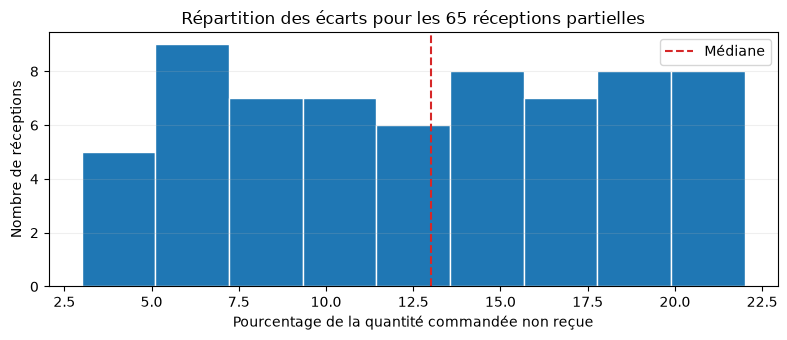

In [19]:
# Écart relatif des 65 réceptions incomplètes (en %).
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(receptions_partielles["part_non_receptionnee_%"], bins=9, edgecolor="white")
ax.axvline(receptions_partielles["part_non_receptionnee_%"].median(),
           color="tab:red", linestyle="--", label="Médiane")
ax.set_xlabel("Pourcentage de la quantité commandée non reçue")
ax.set_ylabel("Nombre de réceptions")
ax.set_title("Répartition des écarts pour les 65 réceptions partielles")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### Étape 3 — Peut-on prolonger la traçabilité vers les expéditions ?

**Limite du schéma :** les expéditions n'ont ni `purchase_order_number`, ni `receipt_number`, et les réceptions n'ont pas de `shipment_number`. Un appariement par date, catégorie, établissement ou quantité **ne constitue pas une preuve** de correspondance entre deux flux.

Les ajustements de stock disposent de deux références facultatives (`related_receipt_number` et `related_shipment_number`) : seules **5 lignes d'ajustement** renseignent les deux à la fois. Nous contrôlons leur compatibilité minimale (dates, catégories, unités) avant d'en faire des ponts de traçabilité. On ne réalise **aucune fusion de tous les flux** sur des attributs non identifiants.

In [20]:
# Audit limité aux ajustements portant explicitement les DEUX références.
ajustements_liaisons = pd.read_csv(
    root / "data/processed/logistics/inventory_adjustments.csv", dtype=str, keep_default_na=False
)
receptions_liaisons = pd.read_csv(
    root / "data/processed/logistics/goods_receipts.csv", dtype=str, keep_default_na=False
)
commandes_liaisons = pd.read_csv(
    root / "data/processed/logistics/purchase_order_lines.csv", dtype=str, keep_default_na=False
)
expeditions_liaisons = pd.read_csv(
    root / "data/processed/logistics/shipments.csv", dtype=str, keep_default_na=False
)

ponts_candidats = ajustements_liaisons.loc[
    ajustements_liaisons["related_receipt_number"].ne("")
    & ajustements_liaisons["related_shipment_number"].ne("")
].copy()

ponts_candidats = ponts_candidats.merge(
    receptions_liaisons[[
        "receipt_number", "purchase_order_number", "purchase_order_line",
        "receipt_date_normalized", "received_unit",
    ]],
    left_on="related_receipt_number", right_on="receipt_number",
    how="left", validate="one_to_one",
)
ponts_candidats = ponts_candidats.merge(
    commandes_liaisons[[
        "purchase_order_number", "purchase_order_line", "item_category_normalized", "ordered_unit",
    ]],
    on=["purchase_order_number", "purchase_order_line"], how="left", validate="many_to_one",
)
# La catégorie d'expédition est déjà homogène : la comparer en casse normalisée,
# sans écrire de nouvelle colonne dans les CSV.
expeditions_liaisons["item_category_normalized"] = (
    expeditions_liaisons["item_category"].str.strip().str.casefold()
)
ponts_candidats = ponts_candidats.merge(
    expeditions_liaisons[[
        "shipment_number", "dispatch_time_normalized", "item_category_normalized", "declared_unit",
    ]],
    left_on="related_shipment_number", right_on="shipment_number", how="left",
    validate="one_to_one", suffixes=("_commande", "_expedition"),
)

date_ajustement = pd.to_datetime(ponts_candidats["adjustment_date_normalized"])
date_reception = pd.to_datetime(ponts_candidats["receipt_date_normalized"])
date_expedition = pd.to_datetime(ponts_candidats["dispatch_time_normalized"])
chrono_avant_reception = date_ajustement.lt(date_reception)
chrono_avant_expedition = date_ajustement.lt(date_expedition)
cat_ajustement_commande = ponts_candidats["item_category"].eq(
    ponts_candidats["item_category_normalized_commande"]
)
cat_ajustement_expedition = ponts_candidats["item_category"].eq(
    ponts_candidats["item_category_normalized_expedition"]
)
cat_commande_expedition = ponts_candidats["item_category_normalized_commande"].eq(
    ponts_candidats["item_category_normalized_expedition"]
)

bilan_ponts = pd.DataFrame([{
    "ajustements_avec_les_deux_references": len(ponts_candidats),
    "date_ajustement_anterieure_reception": int(chrono_avant_reception.sum()),
    "date_ajustement_anterieure_expedition": int(chrono_avant_expedition.sum()),
    "meme_categorie_ajustement_et_commande": int(cat_ajustement_commande.sum()),
    "meme_categorie_ajustement_et_expedition": int(cat_ajustement_expedition.sum()),
    "meme_categorie_commande_et_expedition": int(cat_commande_expedition.sum()),
    "meme_unite_reception_et_expedition": int(ponts_candidats["received_unit"].eq(ponts_candidats["declared_unit"]).sum()),
}])
print("Qualité des 5 ponts candidats (réception + expédition via ajustement) :")
display(bilan_ponts)
print("Références et dates concernées :")
display(ponts_candidats[[
    "adjustment_number", "related_receipt_number", "related_shipment_number",
    "adjustment_date_normalized", "receipt_date_normalized", "dispatch_time_normalized",
]])


Qualité des 5 ponts candidats (réception + expédition via ajustement) :


,ajustements_avec_les_deux_references,date_ajustement_anterieure_reception,date_ajustement_anterieure_expedition,meme_categorie_ajustement_et_commande,meme_categorie_ajustement_et_expedition,meme_categorie_commande_et_expedition,meme_unite_reception_et_expedition
0,5,3,4,0,0,1,2


Références et dates concernées :


,adjustment_number,related_receipt_number,related_shipment_number,adjustment_date_normalized,receipt_date_normalized,dispatch_time_normalized
0,ADJ-2018-00014,RCV-2023-00414,SHP-2023-00029,2018-02-18,2023-04-16,2023-04-22T09:00:00
1,ADJ-2018-00016,RCV-2024-00522,SHP-2025-00012,2018-02-22,2024-07-06,2025-05-05T16:00:00
2,ADJ-2018-00017,RCV-2017-00054,SHP-2024-00012,2018-02-23,2017-02-17,2024-06-01T05:00:00
3,ADJ-2018-00018,RCV-2023-00446,SHP-2023-00037,2018-02-26,2023-09-15,2023-09-01T05:00:00
4,ADJ-2023-00102,RCV-2016-00024,SHP-2022-00027,2023-06-18,2016-01-02,2022-02-24T15:00:00


### Bilan de l’étape 3 — Commandes, réceptions et limites du suivi

Sur **650 lignes de commande**, **610** ont une réception associée par identifiant. Parmi elles, **545 quantités correspondent** et **65 sont inférieures** à la quantité commandée. Sur ces 65 cas, l'écart relatif médian est de **13 %** (entre **3 % et 22 %**). Les **40 autres commandes** n'ont pas de réception dans le fichier.

On a essayé de prolonger ce suivi jusqu'aux expéditions, mais il manque une clé directe entre réception et transport. Seulement **5 ajustements** citent à la fois une réception et une expédition ; leurs dates et leurs catégories ne permettent pas de valider une chaîne complète.

**Ce qu'on retient :** les différences de quantité sont observées dans les données. En revanche, on ne sait pas si elles viennent d'une livraison partielle, d'une règle de gestion ou d'une erreur de saisie.

## Étape 4 — Stocks : première équation de conservation

**Question :** les quantités déclarées dans les 500 états mensuels permettent-elles, à elles seules, de reconstruire le stock final ? On applique **uniquement les cinq composantes présentes** dans `inventory_month_end.csv` :

\[ S_{\mathrm{attendu}} = S_{\mathrm{initial}} + Q_{\mathrm{reçue}} - Q_{\mathrm{sortante}} - U_{\mathrm{interne}} - P_{\mathrm{déchets}} \]

Puis on mesure le **résidu signé** :

\[ R = S_{\mathrm{final\,déclaré}} - S_{\mathrm{attendu}} \]

- **R = 0** : l'équation simple est vérifiée ;
- **R positif** : stock déclaré supérieur au stock théorique ;
- **R négatif** : stock déclaré inférieur au stock théorique.

Il s'agit d'un **diagnostic provisoire** : le dictionnaire n'indique pas si les ajustements comptables sont déjà incorporés à ces colonnes, ni comment l'ERP traite les stocks théoriques négatifs. On **n'ajoute pas encore** le fichier `inventory_adjustments.csv` et on ne qualifie pas les écarts d'anomalies définitives. Les calculs sont **ligne par ligne dans l'unité d'origine** ; aucune somme entre `case`, `kit`, `pallet` et `sealed_lot`. Les valeurs normalisées ne sont pas écrites dans les CSV.

In [21]:
# Vérification reproductible de l'équation SIMPLE, sans appliquer d'ajustements.
stocks_etape4 = pd.read_csv(root / "data/processed/logistics/inventory_month_end.csv")
champs_numeriques_stock = [
    "opening_stock_numeric", "received_quantity_numeric", "outgoing_quantity_numeric",
    "documented_internal_use_numeric", "documented_waste_numeric", "closing_stock_numeric",
]

stocks_etape4["stock_attendu_simple"] = (
    stocks_etape4["opening_stock_numeric"]
    + stocks_etape4["received_quantity_numeric"]
    - stocks_etape4["outgoing_quantity_numeric"]
    - stocks_etape4["documented_internal_use_numeric"]
    - stocks_etape4["documented_waste_numeric"]
).round(2)
stocks_etape4["residu_simple"] = (
    stocks_etape4["closing_stock_numeric"] - stocks_etape4["stock_attendu_simple"]
).round(2)
stocks_etape4["ecart_simple"] = stocks_etape4["residu_simple"].ne(0)

bilan_stock_simple = pd.DataFrame([{
    "etats_mensuels": len(stocks_etape4),
    "equation_exacte": int((~stocks_etape4["ecart_simple"]).sum()),
    "equation_en_ecart": int(stocks_etape4["ecart_simple"].sum()),
    "residus_positifs": int(stocks_etape4["residu_simple"].gt(0).sum()),
    "residus_negatifs": int(stocks_etape4["residu_simple"].lt(0).sum()),
    "ecart_absolu_superieur_a_1_dans_unite_d_origine": int(stocks_etape4["residu_simple"].abs().gt(1).sum()),
    "stock_theorique_negatif": int(stocks_etape4["stock_attendu_simple"].lt(0).sum()),
}])
print("Équation simple : bilan sans ajustements")
display(bilan_stock_simple)

bilan_statuts_stock = stocks_etape4.groupby("inventory_status_normalized").agg(
    etats=("residu_simple", "size"),
    avec_ecart=("ecart_simple", "sum"),
    mediane_ecart_absolu=("residu_simple", lambda s: s.abs().median()),
    maximum_ecart_absolu=("residu_simple", lambda s: s.abs().max()),
).reset_index().round(2)

colonnes_exemples = [
    "facility_code", "reporting_month", "item_category", "unit",
    "closing_stock_numeric", "stock_attendu_simple", "residu_simple",
    "inventory_status_normalized",
]

# Vérifier seulement si les ajustements PEUVENT être rapprochés des états mensuels.
ajustements_etape4 = pd.read_csv(root / "data/processed/logistics/inventory_adjustments.csv", dtype=str, keep_default_na=False)
ajustements_etape4["mois"] = pd.to_datetime(
    ajustements_etape4["adjustment_date_normalized"]
).dt.to_period("M").astype(str)
stocks_etape4["mois"] = pd.to_datetime(
    stocks_etape4["reporting_month_normalized"]
).dt.to_period("M").astype(str)
correspondance_ajustement_stock = ajustements_etape4.merge(
    stocks_etape4[["facility_code", "item_category", "mois", "unit"]],
    on=["facility_code", "item_category", "mois"],
    how="left", validate="many_to_one", indicator=True,
    suffixes=("_ajustement", "_stock"),
)
liens_meme_mois = correspondance_ajustement_stock["_merge"].eq("both")
print("Disponibilité des ajustements dans les mêmes établissement, catégorie et mois :")
display(pd.DataFrame([{
    "ajustements_total": len(ajustements_etape4),
    "meme_groupe_et_mois": int(liens_meme_mois.sum()),
    "sans_etat_mensuel_correspondant": int((~liens_meme_mois).sum()),
}]))


Équation simple : bilan sans ajustements


,etats_mensuels,equation_exacte,equation_en_ecart,residus_positifs,residus_negatifs,ecart_absolu_superieur_a_1_dans_unite_d_origine,stock_theorique_negatif
0,500,3,497,269,228,304,39


Disponibilité des ajustements dans les mêmes établissement, catégorie et mois :


,ajustements_total,meme_groupe_et_mois,sans_etat_mensuel_correspondant
0,140,38,102


### Étape 4 — Test d'hypothèse : les ajustements peuvent-ils expliquer les résidus ?

**Hypothèse à tester, non confirmée par le dictionnaire :** une quantité d'ajustement **positive** augmente le stock comptable et une quantité **négative** le diminue ; cet ajustement ne serait **pas déjà inclus** dans les mouvements du relevé mensuel. Sous cette hypothèse seulement :

\[ R_{\mathrm{après}}=R_{\mathrm{simple}}-A \]

où `A` est la somme **signée** des ajustements du même établissement, de la même catégorie, du même mois et de la **même unité**. On teste séparément :

- **Scénario `posted` :** seuls les ajustements portant explicitement le statut `posted` sont supposés comptabilisés ;
- **Scénario exhaustif (sensibilité) :** tous les ajustements rapprochables sont supposés comptabilisés, y compris `approved` et `pending_review`. **Ce deuxième scénario ne signifie pas qu'ils sont effectivement comptabilisés.**

**Limites :** les 102 ajustements non rapprochables à un état mensuel disponible ne sont pas imputés. Une date d'ajustement volontairement non résolue reste exclue. Une correspondance par établissement–catégorie–mois ne prouve pas qu'un ajustement n'est pas déjà inclus dans les colonnes mensuelles ; une amélioration du résidu ne démontre pas une explication causale. Aucune modification des CSV ni des stocks déclarés.

In [22]:
# Comparaison sur les seules lignes pour lesquelles un ajustement du même mois existe.
stocks_test = pd.read_csv(root / "data/processed/logistics/inventory_month_end.csv")
ajustements_test = pd.read_csv(
    root / "data/processed/logistics/inventory_adjustments.csv", dtype=str, keep_default_na=False
)
stocks_test["mois"] = stocks_test["reporting_month_normalized"].str.slice(0, 7)
ajustements_test["mois"] = ajustements_test["adjustment_date_normalized"].str.slice(0, 7)
ajustements_test["quantite_ajustement"] = pd.to_numeric(
    ajustements_test["adjustment_quantity_numeric"], errors="raise"
)

# Stock attendu et résidu initial : exactement la même formule que dans la cellule précédente.
stocks_test["residu_initial"] = (
    stocks_test["closing_stock_numeric"] - (
        stocks_test["opening_stock_numeric"]
        + stocks_test["received_quantity_numeric"]
        - stocks_test["outgoing_quantity_numeric"]
        - stocks_test["documented_internal_use_numeric"]
        - stocks_test["documented_waste_numeric"]
    )
).round(2)
cles_stock_mois = ["facility_code", "item_category", "mois", "unit"]

ajustements_avec_mois = ajustements_test.loc[
    ajustements_test["mois"].str.fullmatch(r"\d{4}-\d{2}")
].copy()
ajustements_rattaches = ajustements_avec_mois.merge(
    stocks_test[cles_stock_mois], on=cles_stock_mois, how="inner", validate="many_to_one"
)

# Agrégation dimensionnée par la même unité ; ne jamais additionner de catégories ou d'unités différentes.
somme_tous = ajustements_rattaches.groupby(cles_stock_mois)["quantite_ajustement"].sum().rename("ajustement_tous")
somme_postes = ajustements_rattaches.loc[
    ajustements_rattaches["adjustment_status"].eq("posted")
].groupby(cles_stock_mois)["quantite_ajustement"].sum().rename("ajustement_posted")
reconciliation = stocks_test.join(somme_tous, on=cles_stock_mois).join(somme_postes, on=cles_stock_mois)
reconciliation = reconciliation.loc[reconciliation["ajustement_tous"].notna()].copy()
reconciliation["ajustement_posted"] = reconciliation["ajustement_posted"].fillna(0)
reconciliation["residu_si_tous"] = (
    reconciliation["residu_initial"] - reconciliation["ajustement_tous"]
).round(2)
reconciliation["residu_si_posted"] = (
    reconciliation["residu_initial"] - reconciliation["ajustement_posted"]
).round(2)

# Mesures par ligne : une amélioration signifie un résidu absolu plus petit, pas un stock corrigé.
def comparer_scenario(nom, colonne):
    avant = reconciliation["residu_initial"].abs()
    apres = reconciliation[colonne].abs()
    return {
        "scenario": nom,
        "etats_comparables": len(reconciliation),
        "residu_reduit": int(apres.lt(avant - 1e-9).sum()),
        "residu_aggrave": int(apres.gt(avant + 1e-9).sum()),
        "residu_inchange": int(np.isclose(apres, avant, atol=1e-9).sum()),
        "residu_final_abs_au_plus_0_01": int(apres.le(0.01 + 1e-9).sum()),
    }

bilan_scenarios = pd.DataFrame([
    comparer_scenario("posted uniquement", "residu_si_posted"),
    comparer_scenario("tous statuts (hypothèse)", "residu_si_tous"),
])
print("Statuts des 38 ajustements appariés :")
display(ajustements_rattaches["adjustment_status"].value_counts().rename_axis("statut").reset_index(name="n"))
print("Effet des deux scénarios sur les écarts absolus :")
display(bilan_scenarios)

reconciliation["amelioration_tous"] = (
    reconciliation["residu_si_tous"].abs() < reconciliation["residu_initial"].abs() - 1e-9
)
reconciliation["aggravation_tous"] = (
    reconciliation["residu_si_tous"].abs() > reconciliation["residu_initial"].abs() + 1e-9
)

# Deux exemples pour montrer qu'un ajustement peut réduire OU aggraver un écart.
exemples = reconciliation.loc[
    reconciliation[["facility_code", "item_category", "mois"]].apply(
        tuple, axis=1
    ).isin([
        ("FCL-1024", "biological_sample", "2024-03"),
        ("FCL-1024", "biological_sample", "2020-04"),
    ]),
    ["facility_code", "item_category", "mois", "unit", "inventory_status_normalized",
     "residu_initial", "ajustement_tous", "residu_si_tous"],
]


Statuts des 38 ajustements appariés :


,statut,n
0,posted,30
1,approved,7
2,pending_review,1


Effet des deux scénarios sur les écarts absolus :


,scenario,etats_comparables,residu_reduit,residu_aggrave,residu_inchange,residu_final_abs_au_plus_0_01
0,posted uniquement,38,23,7,8,1
1,tous statuts (hypothèse),38,30,8,0,1


### Étape 4 — Continuité des stocks entre relevés mensuels

**Nouvelle question, différente de l'équation de conservation interne :** le stock final déclaré à la date `t` correspond-il au stock initial déclaré au **relevé suivant** du même établissement, de la même catégorie et de la même unité ?

Nous calculons, pour les 25 séries établissement–catégorie–unité, la différence :

\[ D = S_{\mathrm{initial,\ relevé\ suivant}} - S_{\mathrm{final,\ relevé\ précédent}} \]

**Précaution temporelle essentielle :** le fichier ne fournit que certains mois de 2018 à 2025. Nous distinguons strictement les deux situations :

- **Mois réellement consécutifs :** différence de **1 mois** ; c'est le contrôle de continuité mensuelle interprétable.
- **Relevés séparés par plusieurs mois :** la comparaison des soldes reste calculable, mais **ne prouve pas l'absence de mouvements durant les mois non représentés**. Ne jamais assimiler « relevé suivant » à « mois suivant » si l'écart calendaire est supérieur à un mois.

Cette vérification est distincte de la conservation intra-mensuelle : deux soldes peuvent être parfaitement recopiés d'un relevé à l'autre alors que les mouvements déclarés au sein de chaque mois ne permettent pas de reconstituer le stock final. **Aucun remplissage des mois absents ni modification des fichiers.**

In [23]:
# Comparer deux relevés dans la même série, en tenant compte des VRAIES distances calendaires.
continuite = pd.read_csv(
    root / "data/processed/logistics/inventory_month_end.csv", dtype=str, keep_default_na=False
)
cle_serie = ["facility_code", "item_category", "unit"]
continuite["date_releve"] = pd.to_datetime(
    continuite["reporting_month_normalized"], format="%Y-%m-%d", errors="raise"
)
continuite["stock_initial"] = pd.to_numeric(continuite["opening_stock_numeric"], errors="raise")
continuite["stock_final"] = pd.to_numeric(continuite["closing_stock_numeric"], errors="raise")

continuite = continuite.sort_values(cle_serie + ["date_releve"]).copy()
continuite["date_precedente"] = continuite.groupby(cle_serie)["date_releve"].shift(1)
continuite["stock_final_precedent"] = continuite.groupby(cle_serie)["stock_final"].shift(1)
periode_courante = continuite["date_releve"].dt.to_period("M")
periode_precedente = continuite["date_precedente"].dt.to_period("M")
continuite["mois_ecoules"] = (
    periode_courante.astype("int64") - periode_precedente.astype("int64")
).where(continuite["date_precedente"].notna())
continuite["difference_soldes"] = (
    continuite["stock_initial"] - continuite["stock_final_precedent"]
).round(2)

premiers_releves = continuite.loc[continuite["date_precedente"].isna()]
releves_consecutifs = continuite.loc[continuite["mois_ecoules"].eq(1)]
releves_espaces = continuite.loc[continuite["mois_ecoules"].gt(1)]
nb_series = continuite.groupby(cle_serie).ngroups

bilan_continuite = pd.DataFrame([
    {"type": "Premier relevé de série : comparaison impossible", "transitions": len(premiers_releves), "soldes_identiques": None},
    {"type": "Mois consécutifs (test de continuité mensuelle)", "transitions": len(releves_consecutifs), "soldes_identiques": int(releves_consecutifs["difference_soldes"].eq(0).sum())},
    {"type": "Relevés séparés par plusieurs mois (comparaison limitée)", "transitions": len(releves_espaces), "soldes_identiques": int(releves_espaces["difference_soldes"].eq(0).sum())},
])
print("Nombre de séries établissement–catégorie–unité :", nb_series)
display(bilan_continuite)

print("Durée entre deux relevés successifs :")
display(continuite["mois_ecoules"].dropna().astype(int).value_counts().sort_index().rename_axis(
    "mois_ecoules"
).reset_index(name="transitions"))


Nombre de séries établissement–catégorie–unité : 25


,type,transitions,soldes_identiques
0,Premier relevé de série : comparaison impossible,25,NaN
1,Mois consécutifs (test de continuité mensuelle),50,50.0
2,Relevés séparés par plusieurs mois (comparaiso...,425,425.0


Durée entre deux relevés successifs :


,mois_ecoules,transitions
0,1,50
1,2,175
2,3,25
3,4,25
4,5,25
5,7,25
6,8,75
7,9,50
8,11,25


### Étape 4 — Diagnostic des 39 stocks théoriques négatifs

**Question :** pourquoi notre équation de conservation simple peut-elle prédire une quantité négative alors que le stock final déclaré est non négatif ? Nous ne prétendons pas qu'un stock physique négatif a existé. Nous recherchons quels termes suffisent à produire ce résultat et si des ajustements enregistrés expliquent certains cas.

Définitions, **pour une ligne de même établissement, catégorie, mois et unité** :

- **Disponible** = `opening_stock_numeric` + `received_quantity_numeric` ;
- **Déductions** = `outgoing_quantity_numeric` + `documented_internal_use_numeric` + `documented_waste_numeric` ;
- **Stock théorique simple** = disponible − déductions ;
- **Stock théorique négatif** lorsque les déductions **dépassent** le disponible, sans aucune correction automatique ;
- **Résidu** = stock final déclaré − stock théorique simple.

Nous distinguons : (a) les sorties seules dépassent déjà le disponible ; (b) ce sont les déductions combinées qui le dépassent. Ensuite, nous vérifions si un ajustement déjà enregistré existe **pour la même clé complète, y compris le mois et l'unité**, et testons *uniquement à titre hypothétique* si son signe et sa quantité réduisent le résidu. Une correspondance de clé n'établit pas que cet ajustement doit être ajouté : nous ignorons s'il est déjà incorporé aux relevés mensuels.

**Limites :** une clôture à zéro peut résulter de plusieurs mécanismes, notamment une règle de plancher, mais nous ne pouvons pas affirmer que l'ERP applique un écrêtage sans documentation. Aucune imputation, aucun remplissage des mois absents et aucune modification des stocks ou CSV.

In [24]:
# Diagnostic ciblé des stocks théoriques négatifs, sur les données processed.
stocks_negatifs = pd.read_csv(
    root / "data/processed/logistics/inventory_month_end.csv", dtype=str, keep_default_na=False
)
champs_stock = [
    "opening_stock_numeric", "received_quantity_numeric", "outgoing_quantity_numeric",
    "documented_internal_use_numeric", "documented_waste_numeric", "closing_stock_numeric",
]
for champ in champs_stock:
    stocks_negatifs[champ] = pd.to_numeric(stocks_negatifs[champ], errors="raise")
stocks_negatifs["disponible"] = (
    stocks_negatifs["opening_stock_numeric"] + stocks_negatifs["received_quantity_numeric"]
).round(2)
stocks_negatifs["deductions"] = (
    stocks_negatifs["outgoing_quantity_numeric"]
    + stocks_negatifs["documented_internal_use_numeric"]
    + stocks_negatifs["documented_waste_numeric"]
).round(2)
stocks_negatifs["stock_theorique_simple"] = (
    stocks_negatifs["disponible"] - stocks_negatifs["deductions"]
).round(2)
stocks_negatifs["residu_simple"] = (
    stocks_negatifs["closing_stock_numeric"] - stocks_negatifs["stock_theorique_simple"]
).round(2)
cas_negatifs = stocks_negatifs.loc[stocks_negatifs["stock_theorique_simple"].lt(0)].copy()
cas_negatifs["sorties_seules_superieures_disponible"] = (
    cas_negatifs["outgoing_quantity_numeric"].gt(cas_negatifs["disponible"])
)
cas_negatifs["manque_theorique"] = -cas_negatifs["stock_theorique_simple"]

bilan_negatifs = pd.DataFrame([{
    "releves": len(stocks_negatifs),
    "stock_theorique_negatif": len(cas_negatifs),
    "part_%": round(100 * len(cas_negatifs) / len(stocks_negatifs), 1),
    "sorties_seules_depassent_disponible": int(cas_negatifs["sorties_seules_superieures_disponible"].sum()),
    "deductions_combinees_depassent_disponible": int((~cas_negatifs["sorties_seules_superieures_disponible"]).sum()),
    "stock_final_declare_nul": int(cas_negatifs["closing_stock_numeric"].eq(0).sum()),
    "stock_final_declare_positif": int(cas_negatifs["closing_stock_numeric"].gt(0).sum()),
}])
print("Bilan des 39 stocks théoriques négatifs :")
display(bilan_negatifs)
print("Catégories concernées (comparées aux 100 relevés de chaque catégorie) :")
par_categorie = stocks_negatifs.assign(
    theorique_negatif=stocks_negatifs["stock_theorique_simple"].lt(0)
).groupby("item_category").agg(
    releves=("theorique_negatif", "size"),
    negatifs=("theorique_negatif", "sum"),
).reset_index()
par_categorie["part_%"] = (100 * par_categorie["negatifs"] / par_categorie["releves"]).round(1)
display(par_categorie.sort_values("negatifs", ascending=False))

colonnes_negatifs = [
    "facility_code", "reporting_month_normalized", "item_category", "unit",
    "disponible", "outgoing_quantity_numeric", "documented_internal_use_numeric",
    "documented_waste_numeric", "stock_theorique_simple", "closing_stock_numeric",
]

# Rapprocher les seuls ajustements ayant une date ISO connue : pas d'imputation de mois.
ajust_negatifs = pd.read_csv(
    root / "data/processed/logistics/inventory_adjustments.csv", dtype=str, keep_default_na=False
)
ajust_negatifs["mois"] = ajust_negatifs["adjustment_date_normalized"].str.slice(0, 7)
ajust_negatifs["quantite_signee"] = pd.to_numeric(
    ajust_negatifs["adjustment_quantity_numeric"], errors="raise"
)
cas_negatifs["mois"] = cas_negatifs["reporting_month_normalized"].str.slice(0, 7)
cle_mensuelle = ["facility_code", "item_category", "mois", "unit"]
ajust_dates_valides = ajust_negatifs.loc[
    ajust_negatifs["mois"].str.fullmatch(r"\d{4}-\d{2}")
]
# Une même clé peut posséder plusieurs ajustements : agréger AVANT la jointure
# pour garantir une seule ligne par état mensuel et éviter tout double comptage.
ajustements_par_mois = ajust_dates_valides.groupby(cle_mensuelle).agg(
    quantite_signee=("quantite_signee", "sum"),
    adjustment_number=("adjustment_number", lambda v: ", ".join(v)),
    adjustment_status=("adjustment_status", lambda v: ", ".join(v)),
    nombre_ajustements=("adjustment_number", "size"),
).reset_index()
comparaison_negatifs = cas_negatifs.merge(
    ajustements_par_mois,
    on=cle_mensuelle, how="left", validate="one_to_one", indicator=True,
)
avec_ajustement = comparaison_negatifs.loc[comparaison_negatifs["_merge"].eq("both")].copy()
sans_ajustement = comparaison_negatifs.loc[comparaison_negatifs["_merge"].eq("left_only")]
avec_ajustement["stock_theorique_si_ajustement"] = (
    avec_ajustement["stock_theorique_simple"] + avec_ajustement["quantite_signee"]
).round(2)
avec_ajustement["residu_si_ajustement"] = (
    avec_ajustement["closing_stock_numeric"] - avec_ajustement["stock_theorique_si_ajustement"]
).round(2)
avec_ajustement["residu_reduit"] = (
    avec_ajustement["residu_si_ajustement"].abs().lt(avec_ajustement["residu_simple"].abs())
)

print("Couverture des 39 cas par des ajustements du même mois et de la même unité :")
display(pd.DataFrame([{
    "stocks_theoriques_negatifs": len(cas_negatifs),
    "avec_ajustement_rapprochable": len(avec_ajustement),
    "sans_ajustement_rapprochable": len(sans_ajustement),
    "residu_reduit_si_ajustement_applique": int(avec_ajustement["residu_reduit"].sum()),
    "residu_aggrave_si_ajustement_applique": int((~avec_ajustement["residu_reduit"]).sum()),
}]))


Bilan des 39 stocks théoriques négatifs :


,releves,stock_theorique_negatif,part_%,sorties_seules_depassent_disponible,deductions_combinees_depassent_disponible,stock_final_declare_nul,stock_final_declare_positif
0,500,39,7.8,30,9,34,5


Catégories concernées (comparées aux 100 relevés de chaque catégorie) :


,item_category,releves,negatifs,part_%
1,biological_sample,100,24,24.0
0,agricultural_product,100,6,6.0
4,protective_equipment,100,6,6.0
3,monitoring_equipment,100,2,2.0
2,medical_consumables,100,1,1.0


Couverture des 39 cas par des ajustements du même mois et de la même unité :


,stocks_theoriques_negatifs,avec_ajustement_rapprochable,sans_ajustement_rapprochable,residu_reduit_si_ajustement_applique,residu_aggrave_si_ajustement_applique
0,39,3,36,1,2


### Visualisation — Où trouve-t-on les stocks théoriques négatifs ?

On compte les relevés dont **notre formule** donne un résultat négatif, pour chaque couple **établissement × catégorie**. Les nombres représentent des **relevés**, pas des quantités de stock additionnées entre unités différentes.

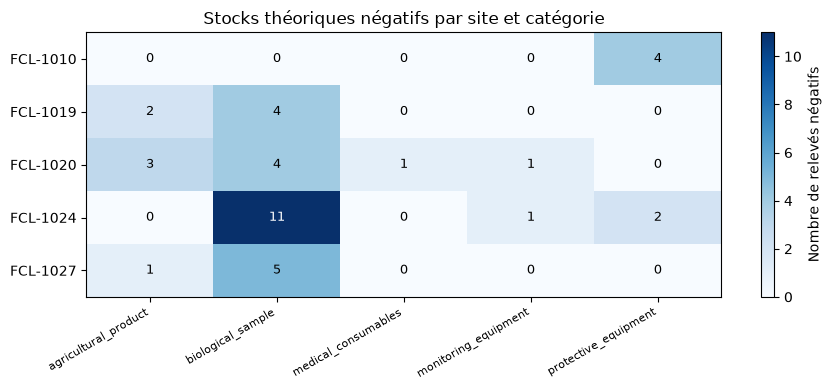

In [25]:
# Nombre de relevés négatifs par établissement et catégorie.
matrice_negatifs = pd.crosstab(
    cas_negatifs["facility_code"], cas_negatifs["item_category"]
)
fig, ax = plt.subplots(figsize=(9, 4))
image = ax.imshow(matrice_negatifs, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(matrice_negatifs.columns)), matrice_negatifs.columns,
              rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(matrice_negatifs.index)), matrice_negatifs.index)
for ligne in range(len(matrice_negatifs.index)):
    for colonne in range(len(matrice_negatifs.columns)):
        valeur = int(matrice_negatifs.iloc[ligne, colonne])
        ax.text(colonne, ligne, str(valeur), ha="center", va="center", fontsize=9,
                color="white" if valeur > matrice_negatifs.to_numpy().max() / 2 else "black")
fig.colorbar(image, ax=ax, label="Nombre de relevés négatifs")
ax.set_title("Stocks théoriques négatifs par site et catégorie")
plt.tight_layout()
plt.show()

### Étape 4 — Ce qu'on retient des stocks théoriques négatifs

Sur **500 relevés**, l'équation simplifiée donne **39 stocks théoriques négatifs**. Dans **30 cas**, les sorties dépassent déjà le stock disponible (stock initial + entrées). Dans les **9 autres**, c'est l'ensemble des déductions qui provoque le résultat négatif.

Le stock final enregistré est pourtant **nul dans 34 de ces 39 cas**, et positif dans 5. Les échantillons biologiques sont particulièrement présents (**24 cas**). Seulement **3 de ces 39 lignes** peuvent être rapprochées d'un ajustement du même mois, du même site, de la même catégorie et de la même unité.

Il y a donc un écart entre notre calcul et les données enregistrées, mais il peut manquer des mouvements ou des règles dans notre formule. **Un stock théorique négatif n'est pas une perte physique prouvée.**

### Étape 4 — Hypothèse d'un plancher à zéro, et concentration des cas

**Hypothèse exploratoire :** si l'ERP empêchait un solde final négatif, le stock final affiché pourrait ressembler à `max(0, stock théorique simple)`. Pour éviter de prendre un mécanisme supposé pour une vérité, nous évaluons cette règle sur **l'ensemble des 500 relevés** et non seulement sur les 39 stocks théoriques négatifs.

On distingue :

1. Le **stock théorique simple**, calculé avec les mouvements du relevé ;
2. Une **prédiction fictive avec plancher** `max(0, stock théorique simple)` ;
3. Le **stock final effectivement déclaré**, qui n'est jamais modifié.

Nous comptons les correspondances exactes et les cas discordants. **Précaution :** dès lors que le stock final observé est non négatif, remplacer une prédiction négative par zéro réduit automatiquement son écart absolu, même si le système n'applique pas réellement un plancher. Ce gain mathématique **n'est pas une validation du mécanisme**. Par ailleurs, un stock final nul avec un théorique positif, ou un stock final positif avec un théorique négatif, montre que la seule règle ne décrit pas tous les relevés.

Enfin, on vérifie la **concentration descriptive** des stocks théoriques négatifs par catégorie et établissement. Le jeu de données étant synthétique, et les relevés appartenant à des séries répétées, on **ne conclut ni à une causalité ni à une significativité statistique indépendante**.

In [26]:
# Test global d'une règle hypothétique : stock final affiché = max(0, stock théorique simple).
test_plancher = pd.read_csv(root / "data/processed/logistics/inventory_month_end.csv")
for nom in [
    "opening_stock_numeric", "received_quantity_numeric", "outgoing_quantity_numeric",
    "documented_internal_use_numeric", "documented_waste_numeric", "closing_stock_numeric",
]:
    test_plancher[nom] = pd.to_numeric(test_plancher[nom], errors="raise")
test_plancher["stock_theorique_simple"] = (
    test_plancher["opening_stock_numeric"] + test_plancher["received_quantity_numeric"]
    - test_plancher["outgoing_quantity_numeric"]
    - test_plancher["documented_internal_use_numeric"]
    - test_plancher["documented_waste_numeric"]
).round(2)
test_plancher["prediction_plancher_0"] = test_plancher["stock_theorique_simple"].clip(lower=0)
test_plancher["stock_final_declare"] = test_plancher["closing_stock_numeric"].round(2)

test_plancher["theorique_negatif"] = test_plancher["stock_theorique_simple"].lt(0)
test_plancher["final_declare_nul"] = test_plancher["stock_final_declare"].eq(0)
test_plancher["residu_simple"] = (
    test_plancher["stock_final_declare"] - test_plancher["stock_theorique_simple"]
).round(2)
test_plancher["residu_plancher"] = (
    test_plancher["stock_final_declare"] - test_plancher["prediction_plancher_0"]
).round(2)

print("Stock théorique (signe) versus stock final réellement déclaré :")
tableau_plancher = pd.crosstab(
    test_plancher["theorique_negatif"].map({True: "Théorique négatif", False: "Théorique positif ou nul"}),
    test_plancher["final_declare_nul"].map({True: "Final nul", False: "Final positif"}),
    margins=True,
)
display(tableau_plancher)

bilan_plancher = pd.DataFrame([{
    "releves": len(test_plancher),
    "theorique_negatif": int(test_plancher["theorique_negatif"].sum()),
    "negatif_et_final_nul": int((test_plancher["theorique_negatif"] & test_plancher["final_declare_nul"]).sum()),
    "negatif_et_final_positif": int((test_plancher["theorique_negatif"] & ~test_plancher["final_declare_nul"]).sum()),
    "positif_et_final_nul": int((~test_plancher["theorique_negatif"] & test_plancher["final_declare_nul"]).sum()),
    "equation_simple_exacte": int(test_plancher["residu_simple"].eq(0).sum()),
    "regle_plancher_exacte": int(test_plancher["residu_plancher"].eq(0).sum()),
    "regle_plancher_en_ecart": int(test_plancher["residu_plancher"].ne(0).sum()),
}])
print("Bilan du test sur les 500 lignes :")
display(bilan_plancher)

# L'amélioration d'erreur pour une prédiction négative est garantie si la cible est >= 0.
# Ce résultat est descriptif, il ne prouve aucun fonctionnement de l'ERP.
erreur_initiale = test_plancher["residu_simple"].abs()
erreur_plancher = test_plancher["residu_plancher"].abs()

# Risque descriptif de stock final nul dans les deux groupes : comparaison, pas causalité.
groupe_negatif = test_plancher["theorique_negatif"]
frequence_zero_neg = test_plancher.loc[groupe_negatif, "final_declare_nul"].mean()
frequence_zero_nonneg = test_plancher.loc[~groupe_negatif, "final_declare_nul"].mean()

par_categorie_plancher = test_plancher.groupby("item_category").agg(
    releves=("theorique_negatif", "size"),
    stock_theorique_negatif=("theorique_negatif", "sum"),
).reset_index()
par_categorie_plancher["taux_negatif_%"] = (
    100 * par_categorie_plancher["stock_theorique_negatif"] / par_categorie_plancher["releves"]
).round(1)


Stock théorique (signe) versus stock final réellement déclaré :


final_declare_nul,Final nul,Final positif,All
theorique_negatif,,,
Théorique négatif,34,5,39
Théorique positif ou nul,22,439,461
All,56,444,500


Bilan du test sur les 500 lignes :


,releves,theorique_negatif,negatif_et_final_nul,negatif_et_final_positif,positif_et_final_nul,equation_simple_exacte,regle_plancher_exacte,regle_plancher_en_ecart
0,500,39,34,5,22,3,37,463


### Étape 4 — Vérification de l'hypothèse du plancher à zéro

On a testé une idée simple : l'ERP pourrait remplacer certains stocks théoriques négatifs par **0**. Cette hypothèse est compatible avec les **34 cas** où le calcul est négatif et le stock final déclaré nul.

Mais la formule `max(0, stock théorique)` n'explique exactement que **37 relevés sur 500**, contre **3** avec la formule sans plancher. Il reste **463 écarts**, et **5 stocks théoriques négatifs** ont même un stock final positif.

**Conclusion :** le plancher à zéro est une piste, pas une règle de fonctionnement démontrée. On conserve les valeurs sources inchangées.

## Bilan de l’étape 4 — Analyse des stocks

La formule utilisée est : **stock initial + entrées − sorties − utilisation interne − pertes documentées**. Elle ne retrouve exactement que **3 stocks finaux sur 500** ; **497** présentent un résidu. Sur ces 500 lignes, **39** donnent un stock théorique négatif, dont **24** concernent des échantillons biologiques.

Les **140 ajustements** ne suffisent pas à expliquer tous ces écarts : seuls **38** peuvent être rapprochés d'un état de stock sur le même site, la même catégorie, le même mois et la même unité. On a testé leur effet **sans les ajouter aux données sources**.

Pour la continuité, les **25 séries** ont peu de mois successifs : seulement **50 transitions consécutives**. Quand des mois manquent, on ne peut pas reconstituer les mouvements intermédiaires.

**Conclusion :** c'est un résultat important pour notre rapport, mais il reste conditionné par notre équation. Il ne démontre ni perte réelle, ni fraude, ni règle particulière de l'ERP.

## Étape 5 — Premier contrôle : expéditions signalées `in_transit`

**Question :** les 17 expéditions sans date d'arrivée et portant le statut `in_transit` sont-elles simplement des dossiers en cours, ou des statuts anciens qui méritent une investigation ?

Le dictionnaire indique une `dispatch_time`, une `arrival_time` et un `shipment_status`, mais **pas de date d'extraction**, **pas de date de mise à jour du statut**, **pas de délai contractuel de livraison**, et **pas d'heure de photographie opérationnelle** du système. Nous ne pouvons donc **pas mesurer la durée réelle du statut `in_transit`**.

**Méthode exploratoire :**

1. Recenser les 17 expéditions `in_transit` et vérifier leurs dates d'arrivée ; comparer aux 433 autres expéditions ayant une date d'arrivée enregistrée.
2. Calculer, pour les dossiers avec départ et arrivée, la **durée réellement observée** entre les deux événements (heures).
3. Pour les 17 dossiers sans arrivée, calculer une **distance chronologique à la dernière date d'événement présente dans le jeu de données**, prise uniquement comme **repère documentaire interne**, et **non comme date réelle d'observation**. Une grande distance signale un statut potentiellement obsolète, **pas une livraison réellement retardée d'autant de jours**.

Ne pas déduire un retard officiel du statut `delayed` en l'absence de date promise. Ne pas inventer des arrivées ni appliquer un seuil réglementaire non fourni. Aucun fichier source n'est modifié.

In [27]:
expeditions_analyse = pd.read_csv(
    root / "data/processed/logistics/shipments.csv", dtype=str, keep_default_na=False
)
expeditions_analyse["depart_dt"] = pd.to_datetime(
    expeditions_analyse["dispatch_time_normalized"], errors="coerce"
)
expeditions_analyse["arrivee_dt"] = pd.to_datetime(
    expeditions_analyse["arrival_time_normalized"], errors="coerce"
)

print("Statut et présence d'une date d'arrivée enregistrée :")
bilan_statuts_arrivees = pd.crosstab(
    expeditions_analyse["shipment_status_normalized"],
    expeditions_analyse["arrivee_dt"].notna().map({True: "date connue", False: "date absente"}),
)
display(bilan_statuts_arrivees)

expeditions_arrivees = expeditions_analyse.loc[
    expeditions_analyse["arrivee_dt"].notna()
].copy()
expeditions_arrivees["duree_entre_evenements_heures"] = (
    expeditions_arrivees["arrivee_dt"] - expeditions_arrivees["depart_dt"]
).dt.total_seconds() / 3600
print("Durées constatées pour les seules expéditions avec arrivée renseignée (en heures) :")
display(expeditions_arrivees.groupby("shipment_status_normalized")[
    "duree_entre_evenements_heures"
].agg(["count", "min", "median", "max"]).round(1))

# Repère interne : maximum des dates de départ et arrivée présentes, sans l'appeler date d'extraction.
date_dernier_evenement = max(
    expeditions_analyse["depart_dt"].max(),
    expeditions_analyse["arrivee_dt"].max(),
)
expeditions_en_transit = expeditions_analyse.loc[
    expeditions_analyse["shipment_status_normalized"].eq("in_transit")
].copy()
expeditions_en_transit["distance_dernier_evenement_jours"] = (
    date_dernier_evenement - expeditions_en_transit["depart_dt"]
).dt.total_seconds() / 86400
expeditions_en_transit = expeditions_en_transit.sort_values("depart_dt")

print("Dossiers 'in_transit' comparés à la dernière date d'événement disponible :", date_dernier_evenement)
print("Dossiers à examiner (distance documentaire, et NON durée de transit vérifiée) :")
display(expeditions_en_transit[[
    "shipment_number", "dispatch_time_normalized", "item_category", "declared_unit",
    "shipment_status_normalized", "distance_dernier_evenement_jours"
]].round({"distance_dernier_evenement_jours": 1}))


Statut et présence d'une date d'arrivée enregistrée :


arrivee_dt,date absente,date connue
shipment_status_normalized,,
delayed,0,34
delivered,0,385
in_transit,17,0
returned,0,14


Durées constatées pour les seules expéditions avec arrivée renseignée (en heures) :


,count,min,median,max
shipment_status_normalized,,,,
delayed,34,12.0,56.5,94.0
delivered,385,6.0,49.0,95.0
returned,14,40.0,62.5,89.0


Dossiers 'in_transit' comparés à la dernière date d'événement disponible : 2025-06-16 03:00:00
Dossiers à examiner (distance documentaire, et NON durée de transit vérifiée) :


,shipment_number,dispatch_time_normalized,item_category,declared_unit,shipment_status_normalized,distance_dernier_evenement_jours
39,SHP-2017-00005,2017-03-31T09:00:00,transport_service,service,in_transit,2998.8
70,SHP-2018-00017,2018-04-10T12:00:00,protective_equipment,case,in_transit,2623.6
82,SHP-2018-00029,2018-04-23T11:00:00,protective_equipment,case,in_transit,2610.7
96,SHP-2018-00043,2018-10-19T15:00:00,cold_storage_equipment,unit,in_transit,2431.5
104,SHP-2019-00004,2019-04-18T14:00:00,office_supply,case,in_transit,2250.5
105,SHP-2019-00005,2019-04-19T09:00:00,consulting_service,service,in_transit,2249.8
136,SHP-2019-00036,2019-09-20T18:00:00,laboratory_material,pack,in_transit,2095.4
150,SHP-2020-00005,2020-02-18T17:00:00,refrigeration_service,service,in_transit,1944.4
176,SHP-2020-00031,2020-04-20T09:00:00,office_supply,case,in_transit,1882.8
182,SHP-2020-00037,2020-05-30T15:00:00,laboratory_material,pack,in_transit,1842.5


### Étape 5 — Expéditions indiquées `in_transit`

On compte **17 expéditions `in_transit`**, toutes sans date d'arrivée enregistrée. Pour **15**, la date de départ précède d'au moins un an le **dernier événement connu dans le fichier** (16 juin 2025).

C'est étonnant et cela mérite de vérifier si les statuts ont été mis à jour. Mais nous ne connaissons **pas la date d'extraction des données**, et ce dernier événement n'est pas la date du jour. On ne peut donc pas dire que ces expéditions sont toujours en route ou réellement perdues.

### Étape 5 — Comparer les expéditions `delayed` et `delivered` sans inventer de date promise

**Question :** les expéditions marquées `delayed` ont-elles réellement des durées départ–arrivée plus longues que celles marquées `delivered` ?

Cette analyse ne concerne que les **419 expéditions ayant l'un de ces deux statuts** et une date d'arrivée exploitable. Les **14 `returned`** et **17 `in_transit`** sont exclus de cette comparaison pour éviter de mélanger retours et trajets non terminés dans le fichier.

Nous comparons les durées **effectivement enregistrées** (en heures) : effectifs, minimum, quartiles, médiane, moyenne et maximum, puis les distributions et leurs chevauchements. **Aucune date de livraison prévue n'est fournie**, donc le statut `delayed` ne peut pas être confirmé à partir de la seule durée.

**Prudence sur le transport :** les 34 expéditions `delayed` sont toutes `ambient`, alors que les `delivered` couvrent plusieurs classes de température. Un **contrôle de robustesse**, limité aux transports `ambient`, évite ce mélange ; il ne supprime pas d'autres effets de composition (trajets, marchandises, transporteurs, période). Un trajet long peut être livré dans les temps et un trajet court peut être en retard sur son échéance. Le calcul ne reclasse **aucune** expédition.

Durées réellement enregistrées (en heures) :


,effectif,minimum,q1,mediane,moyenne,q3,maximum
shipment_status_normalized,,,,,,,
delivered,385,6.0,26.0,49.0,49.4,74.0,95.0
delayed,34,12.0,32.0,56.5,51.2,66.8,94.0


Chevauchement des durées (contre-exemples à un seuil unique) :


,delayed_avec_duree_au_plus_24h,delayed_total,delivered_avec_duree_plus_de_72h,delivered_total,delayed_au_plus_mediane_delivered,ecart_medianes_heures
0,7,34,103,385,16,7.5


Classe de température par statut :
Contrôle de robustesse, transports ambient uniquement :


,effectif,minimum,mediane,moyenne,maximum
shipment_status_normalized,,,,,
delivered,286,6.0,49.0,49.2,94.0
delayed,34,12.0,56.5,51.2,94.0


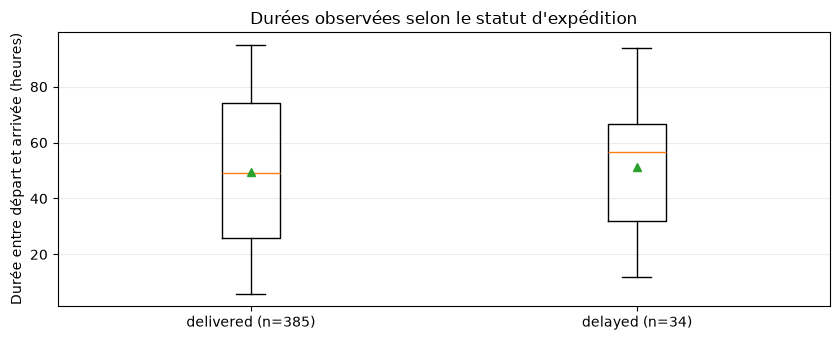

In [28]:
# Diagnostic 2 : distribution des durées observées selon les statuts officiels.
import matplotlib.pyplot as plt

expeditions_durees = pd.read_csv(
    root / "data/processed/logistics/shipments.csv", dtype=str, keep_default_na=False
)
expeditions_durees = expeditions_durees.loc[
    expeditions_durees["shipment_status_normalized"].isin(["delivered", "delayed"])
].copy()
expeditions_durees["depart"] = pd.to_datetime(
    expeditions_durees["dispatch_time_normalized"], errors="raise"
)
expeditions_durees["arrivee"] = pd.to_datetime(
    expeditions_durees["arrival_time_normalized"], errors="raise"
)
expeditions_durees["duree_heures"] = (
    expeditions_durees["arrivee"] - expeditions_durees["depart"]
).dt.total_seconds() / 3600

resume_durees = expeditions_durees.groupby("shipment_status_normalized")["duree_heures"].agg(
    effectif="count", minimum="min", q1=lambda x: x.quantile(.25),
    mediane="median", moyenne="mean", q3=lambda x: x.quantile(.75), maximum="max",
).reindex(["delivered", "delayed"]).round(1)
print("Durées réellement enregistrées (en heures) :")
display(resume_durees)

retardees = expeditions_durees.loc[
    expeditions_durees["shipment_status_normalized"].eq("delayed"), "duree_heures"
]
livrees = expeditions_durees.loc[
    expeditions_durees["shipment_status_normalized"].eq("delivered"), "duree_heures"
]

print("Chevauchement des durées (contre-exemples à un seuil unique) :")
display(pd.DataFrame([{
    "delayed_avec_duree_au_plus_24h": int(retardees.le(24).sum()),
    "delayed_total": len(retardees),
    "delivered_avec_duree_plus_de_72h": int(livrees.gt(72).sum()),
    "delivered_total": len(livrees),
    "delayed_au_plus_mediane_delivered": int(retardees.le(livrees.median()).sum()),
    "ecart_medianes_heures": round(retardees.median() - livrees.median(), 1),
}]))

print("Classe de température par statut :")

# Même comparaison en limitant les deux groupes à la classe de température 'ambient'.
comparaison_ambient = expeditions_durees.loc[
    expeditions_durees["temperature_control_class_normalized"].eq("ambient")
]
resume_ambient = comparaison_ambient.groupby("shipment_status_normalized")["duree_heures"].agg(
    effectif="count", minimum="min", mediane="median", moyenne="mean", maximum="max",
).reindex(["delivered", "delayed"]).round(1)
print("Contrôle de robustesse, transports ambient uniquement :")
display(resume_ambient)

# Figure descriptive : le chevauchement des distributions se voit sans définir de seuil arbitraire.
fig, ax = plt.subplots(figsize=(8.5, 3.5))
ax.boxplot(
    [livrees.to_numpy(), retardees.to_numpy()],
    tick_labels=[f"delivered (n={len(livrees)})", f"delayed (n={len(retardees)})"],
    showmeans=True,
)
ax.set_ylabel("Durée entre départ et arrivée (heures)")
ax.set_title("Durées observées selon le statut d'expédition")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### Étape 5 — Comparaison des statuts `delayed` et `delivered`

Parmi les expéditions avec une arrivée, les **385 `delivered`** ont une durée médiane de **49 h**, contre **56,5 h** pour les **34 `delayed`**. Les durées se recouvrent beaucoup : **7 `delayed` durent au plus 24 h**, tandis que **103 `delivered` dépassent 72 h**.

On ne trouve pas de date limite contractuelle permettant de décider qu'un transport est réellement en retard. Le statut `delayed` ne peut donc pas être reconstitué simplement à partir du temps écoulé.

### Étape 5 — Vérification des autorisations et des quantités déclarées

**Objectif :** identifier d'abord des erreurs vérifiables (`authorization_class` absent, quantité manquante, nulle, négative ou non numérique), puis rechercher des valeurs de quantité **statistiquement atypiques**, sans les déclarer illégales ou fausses.

- Dans `shipments.csv`, `authorization_class` décrit une **classe** (`ordinary`, `expedited`, `restricted`, `emergency`). Le fichier ne comporte **ni identifiant de permis**, ni liste de classes autorisées par type d'article, ni date d'expiration d'une autorisation. Le même champ apparaît dans les commandes, mais il **n'existe pas de clé de rattachement direct commande–expédition**. Une autorisation administrative effective **n'est donc pas vérifiable** avec ces seuls champs.
- La quantité est testée à l'aide de `declared_quantity_numeric` issu du nettoyage : la valeur d'origine `declared_quantity` reste intacte. Une valeur entière n'est pas universellement obligatoire pour tous les flux ; nous la constatons ici **sans en faire une règle métier**.
- Pour les valeurs atypiques, nous utilisons une **règle exploratoire de Tukey** sur chaque groupe *catégorie + unité* (18 groupes), de façon à ne pas mélanger `case`, `sealed_lot`, `service`, etc. : `Q1 − 1,5 × IQR` et `Q3 + 1,5 × IQR`, où `IQR = Q3 − Q1`. Une valeur hors des bornes est une **observation statistiquement atypique**, pas une faute documentaire établie. On utilise la méthode uniquement pour décrire des candidats à examiner ; aucun seuil réglementaire ou contractuel n'est inféré.

Les catégories `service`, `contract` et `grant` comportent des valeurs constantes égales à 1 : cette approche ne peut pas y détecter de variation. Nous n'inventons pas de prix ou de correspondance physique commande–expédition à partir de ces chiffres.

In [29]:
# Diagnostic ciblé : classes d'autorisation et quantités par catégorie + unité.
import pandas as pd
import numpy as np

audit_expeditions = pd.read_csv(
    root / "data/processed/logistics/shipments.csv", dtype=str, keep_default_na=False
)
audit_expeditions["quantite_declaree"] = pd.to_numeric(
    audit_expeditions["declared_quantity_numeric"], errors="raise"
)

classes_presentes = audit_expeditions["authorization_class"].str.strip()
classes_observees = set(classes_presentes.unique())
print("Classes d'autorisation (enregistrements, PAS permis vérifiés) :")
display(classes_presentes.value_counts().rename_axis("classe").reset_index(name="expeditions"))

bilan_quantites = pd.DataFrame([{
    "expeditions": len(audit_expeditions),
    "classe_autorisation_vide": int(classes_presentes.eq("").sum()),
    "quantite_manquante": int(audit_expeditions["quantite_declaree"].isna().sum()),
    "quantite_non_positive": int(audit_expeditions["quantite_declaree"].le(0).sum()),
    "quantite_non_entiere": int(audit_expeditions["quantite_declaree"].mod(1).ne(0).sum()),
    "valeurs_min": float(audit_expeditions["quantite_declaree"].min()),
    "valeurs_max": float(audit_expeditions["quantite_declaree"].max()),
}])
print("Qualité structurelle des quantités déclarées :")
display(bilan_quantites)

# Tukey : n'effectuer les comparaisons qu'au sein d'une même catégorie ET unité.
cle_quantites = ["item_category", "declared_unit"]
statistiques_groupes = audit_expeditions.groupby(cle_quantites)["quantite_declaree"].agg(
    effectif="size", q1=lambda v: v.quantile(.25),
    mediane="median", q3=lambda v: v.quantile(.75),
).reset_index()
statistiques_groupes["iqr"] = statistiques_groupes["q3"] - statistiques_groupes["q1"]
statistiques_groupes["borne_basse"] = statistiques_groupes["q1"] - 1.5 * statistiques_groupes["iqr"]
statistiques_groupes["borne_haute"] = statistiques_groupes["q3"] + 1.5 * statistiques_groupes["iqr"]
audit_expeditions = audit_expeditions.merge(
    statistiques_groupes, on=cle_quantites, how="left", validate="many_to_one"
)
audit_expeditions["atypique_iqr"] = (
    audit_expeditions["quantite_declaree"].lt(audit_expeditions["borne_basse"])
    | audit_expeditions["quantite_declaree"].gt(audit_expeditions["borne_haute"])
)
exemples_iqr = audit_expeditions.loc[
    audit_expeditions["atypique_iqr"],
    ["shipment_number", "item_category", "declared_unit", "quantite_declaree",
     "effectif", "borne_basse", "borne_haute", "authorization_class", "shipment_status_normalized"],
].sort_values(["item_category", "quantite_declaree"])

print("Candidats atypiques IQR (simples observations, pas erreurs ni violations) :")
display(exemples_iqr.round(2))

# Assert le diagnostic uniquement, pas des obligations de politique inconnues.
print("Aucune règle d'autorisation ou valeur obligatoire de quantité n'a été inventée.")


Classes d'autorisation (enregistrements, PAS permis vérifiés) :


,classe,expeditions
0,ordinary,285
1,expedited,76
2,restricted,60
3,emergency,29


Qualité structurelle des quantités déclarées :


,expeditions,classe_autorisation_vide,quantite_manquante,quantite_non_positive,quantite_non_entiere,valeurs_min,valeurs_max
0,450,0,0,0,0,1.0,90.0


Candidats atypiques IQR (simples observations, pas erreurs ni violations) :


,shipment_number,item_category,declared_unit,quantite_declaree,effectif,borne_basse,borne_haute,authorization_class,shipment_status_normalized
316,SHP-2023-00021,biological_sample,sealed_lot,16,52,-4.50,15.50,ordinary,delivered
34,SHP-2016-00017,biological_sample,sealed_lot,17,52,-4.50,15.50,emergency,delivered
144,SHP-2019-00044,biological_sample,sealed_lot,18,52,-4.50,15.50,ordinary,delivered
294,SHP-2022-00060,biological_sample,sealed_lot,18,52,-4.50,15.50,restricted,delivered
259,SHP-2022-00025,office_supply,case,2,27,3.25,101.25,ordinary,delivered


Aucune règle d'autorisation ou valeur obligatoire de quantité n'a été inventée.


### Étape 5 — Autorisations et quantités déclarées

Les **450 expéditions** ont une classe d'autorisation renseignée : **285 `ordinary`**, **76 `expedited`**, **60 `restricted`** et **29 `emergency`**. Les quantités numériques sont positives.

Pour rechercher des valeurs inhabituelles, on compare seulement des quantités de **même catégorie et même unité**. La règle des quartiles (IQR) signale **5 quantités atypiques** : quatre dans `biological_sample` et une dans `office_supply`.

Une classe d'autorisation n'est pas un permis vérifiable, et une quantité atypique n'est pas une erreur prouvée. Il faudrait les règles applicables et les documents d'autorisation pour aller plus loin.

### Étape 5 — Diagnostic des prix unitaires de commande (même article, unité et devise)

**Objectif :** contrôler la validité numérique des `unit_price` de `purchase_order_lines.csv`, puis repérer des prix inhabituels **entre commandes comparables**, sans les confondre avec une surfacturation ou une infraction.

**Comparabilité obligatoire :** un groupe est défini par la clé `(item_code, ordered_unit, currency)`. Un même `item_code` possède une catégorie, une description et une unité cohérentes dans ce dataset. En revanche, il peut être tarifé dans **plusieurs devises** : comparer ou additionner directement des prix `VLN`, `AVL`, `KRN`, `NDH` et `TMB` sans taux de change serait incorrect. Nous ne supposons pas que ces codes correspondent à des devises réelles ni n'inventons de conversion.

Nous calculons des bornes descriptives `Q1 − 1,5 × IQR` et `Q3 + 1,5 × IQR` (`IQR=Q3−Q1`) seulement dans les groupes ayant **au moins 5 commandes**. Les groupes plus petits sont conservés dans les données mais **ne sont pas soumis à ce test**, car leurs quartiles sont trop instables pour constituer un point de comparaison utile. Le choix du seuil de 5 est **exploratoire**, pas une norme de marché ; un second contrôle examine la sensibilité au choix de tailles minimales plus grandes.

**Limites d'interprétation :** les prix unitaires couvrent plusieurs années (2014–2025), fournisseurs et conditions commerciales non entièrement documentées. Un même article n'implique pas que le fournisseur, la quantité, les spécifications contractuelles ou l'année soient comparables. Sans barème officiel, offres concurrentes, facture ou règle tarifaire applicable, aucun prix atypique ne prouve une surfacturation, une manipulation ou une sous-facturation. Aucun prix, devise ni fichier source n'est modifié.

In [30]:
# Étape 5 / prix : contrôles déterministes puis recherche DESCRIPTIVE d'atypiques IQR.
commandes_prix = pd.read_csv(
    root / "data/processed/logistics/purchase_order_lines.csv", dtype=str, keep_default_na=False
)
commandes_prix["prix_unitaire"] = pd.to_numeric(
    commandes_prix["unit_price_numeric"], errors="raise"
)

print("Qualité numérique des prix unitaires :")
display(pd.DataFrame([{
    "lignes_commande": len(commandes_prix),
    "articles_distincts": commandes_prix["item_code"].nunique(),
    "devises_distinctes": commandes_prix["currency"].nunique(),
    "prix_manquants": int(commandes_prix["prix_unitaire"].isna().sum()),
    "prix_non_positifs": int(commandes_prix["prix_unitaire"].le(0).sum()),
    "unite_manquante": int(commandes_prix["ordered_unit"].str.strip().eq("").sum()),
    "devise_manquante": int(commandes_prix["currency"].str.strip().eq("").sum()),
}]))

# Vérifier qu'un même article se rapporte à une seule unité/catégorie dans ce fichier.
cles_prix = ["item_code", "ordered_unit", "currency"]
statistiques_prix = commandes_prix.groupby(cles_prix)["prix_unitaire"].agg(
    effectif="size", q1=lambda s: s.quantile(.25),
    mediane="median", q3=lambda s: s.quantile(.75),
).reset_index()
statistiques_prix["iqr"] = statistiques_prix["q3"] - statistiques_prix["q1"]
statistiques_prix["borne_basse"] = statistiques_prix["q1"] - 1.5 * statistiques_prix["iqr"]
statistiques_prix["borne_haute"] = statistiques_prix["q3"] + 1.5 * statistiques_prix["iqr"]
commandes_prix = commandes_prix.merge(
    statistiques_prix, on=cles_prix, how="left", validate="many_to_one"
)
commandes_prix["groupe_comparable_5"] = commandes_prix["effectif"].ge(5)
commandes_prix["prix_atypique_iqr"] = (
    commandes_prix["groupe_comparable_5"]
    & (commandes_prix["prix_unitaire"].lt(commandes_prix["borne_basse"])
       | commandes_prix["prix_unitaire"].gt(commandes_prix["borne_haute"]))
)
commandes_prix["sens_atypie"] = np.select(
    [commandes_prix["prix_atypique_iqr"] & commandes_prix["prix_unitaire"].lt(commandes_prix["borne_basse"]),
     commandes_prix["prix_atypique_iqr"] & commandes_prix["prix_unitaire"].gt(commandes_prix["borne_haute"])],
    ["bas", "haut"], default="non signalé"
)
commandes_prix["ratio_mediane_groupe"] = (
    commandes_prix["prix_unitaire"] / commandes_prix["mediane"]
)

print("Couverture du test statistique :")
display(pd.DataFrame([{
    "groupes_article_unite_devise": len(statistiques_prix),
    "groupes_avec_au_moins_5": int(statistiques_prix["effectif"].ge(5).sum()),
    "lignes_dans_groupes_eligibles": int(commandes_prix["groupe_comparable_5"].sum()),
    "lignes_non_evaluees_statistiquement": int((~commandes_prix["groupe_comparable_5"]).sum()),
    "prix_atypiques_iqr": int(commandes_prix["prix_atypique_iqr"].sum()),
    "prix_atypiques_hauts": int(commandes_prix["sens_atypie"].eq("haut").sum()),
    "prix_atypiques_bas": int(commandes_prix["sens_atypie"].eq("bas").sum()),
}]))

prix_a_examiner = commandes_prix.loc[
    commandes_prix["prix_atypique_iqr"],
    ["purchase_order_number", "order_date_normalized", "item_code",
     "item_description", "ordered_unit", "currency", "supplier_partner_code",
     "prix_unitaire", "effectif", "mediane", "borne_basse", "borne_haute",
     "ratio_mediane_groupe", "sens_atypie"],
].sort_values(["item_code", "currency", "prix_unitaire"])
print("Neuf valeurs à examiner — prix dans la devise et l'unité de leur groupe :")
display(prix_a_examiner.round(2))

# Contrôle de sensibilité : n>=5 est un choix pragmatique, pas un seuil obligatoire.
print("Sensibilité au nombre minimal de commandes par groupe :")
display(pd.DataFrame([{
    "taille_minimale": taille_min,
    "groupes": int(statistiques_prix["effectif"].ge(taille_min).sum()),
    "lignes_comparables": int(commandes_prix["effectif"].ge(taille_min).sum()),
    "atypiques_iqr": int((commandes_prix["effectif"].ge(taille_min)
                         & commandes_prix["prix_atypique_iqr"]).sum()),
} for taille_min in [5, 6, 8, 10]]))


Qualité numérique des prix unitaires :


,lignes_commande,articles_distincts,devises_distinctes,prix_manquants,prix_non_positifs,unite_manquante,devise_manquante
0,650,27,5,0,0,0,0


Couverture du test statistique :


,groupes_article_unite_devise,groupes_avec_au_moins_5,lignes_dans_groupes_eligibles,lignes_non_evaluees_statistiquement,prix_atypiques_iqr,prix_atypiques_hauts,prix_atypiques_bas
0,126,45,441,209,9,4,5


Neuf valeurs à examiner — prix dans la devise et l'unité de leur groupe :


,purchase_order_number,order_date_normalized,item_code,item_description,ordered_unit,currency,supplier_partner_code,prix_unitaire,effectif,mediane,borne_basse,borne_haute,ratio_mediane_groupe,sens_atypie
22,PO-2015-00022,2015-12-01,ITM-AGR-001,Durian produce pallet,pallet,VLN,BP-30078,1960.10,7,1765.34,1605.30,1950.32,1.11,haut
334,PO-2022-00008,2022-02-03,ITM-COM-001,Secure communication service,service,VLN,BP-30041,1310.07,7,1609.86,1512.81,1705.79,0.81,bas
490,PO-2023-00073,2023-09-08,ITM-MED-002,Sterile administration supplies,case,TMB,BP-30041,242.42,6,289.59,265.61,315.56,0.84,bas
414,PO-2022-00088,2022-12-06,ITM-MON-002,Field camera and sensor kit,kit,VLN,BP-30035,1994.86,7,2385.53,2145.42,2619.04,0.84,bas
451,PO-2023-00034,2023-04-13,ITM-OFF-001,Office supply case,case,AVL,BP-30007,87.78,5,98.36,88.90,111.75,0.89,bas
55,PO-2017-00001,2017-01-13,ITM-PRO-001,Field protective equipment case,case,AVL,BP-30078,498.42,7,422.83,348.72,483.38,1.18,haut
133,PO-2018-00053,2018-12-19,ITM-PRO-002,Cold-handling protective supplies,case,VLN,BP-30058,555.09,5,619.04,581.90,646.18,0.90,bas
248,PO-2020-00054,2020-06-04,ITM-PRO-002,Cold-handling protective supplies,case,VLN,BP-30044,685.76,5,619.04,581.90,646.18,1.11,haut
513,PO-2023-00096,2023-09-22,ITM-REF-001,Refrigeration maintenance service,service,AVL,BP-30046,3133.14,8,2794.44,2516.06,3124.30,1.12,haut


Sensibilité au nombre minimal de commandes par groupe :


,taille_minimale,groupes,lignes_comparables,atypiques_iqr
0,5,45,441,9
1,6,39,411,6
2,8,25,320,1
3,10,18,263,0


### Étape 5 — Prix unitaires : résultats

Les **650 lignes de commande** ont un prix unitaire positif. On trouve **27 références d'articles** et **5 devises**. Pour éviter de mélanger des montants incomparables, on a regroupé les prix par **article, unité et devise**.

Sur **45 groupes d'au moins cinq lignes** (soit **441 commandes**), la règle IQR repère **9 prix atypiques** : **4 plus hauts** et **5 plus bas**. Le résultat dépend de la taille minimale des groupes : plus on l'augmente, moins on peut tester de lignes.

Les fournisseurs, dates et contrats peuvent expliquer une partie des différences. **Ce contrôle ne prouve pas une surfacturation**, et aucune conversion de devise n'a été inventée.

## Bilan de l’étape 5 — Contrôles d'anomalies

On a étudié les statuts de transport, les durées, les quantités, les classes d'autorisation et les prix.

- **17 expéditions `in_transit`** n'ont pas de date d'arrivée ; les statuts sont à vérifier.
- Les **34 `delayed`** ont une durée médiane plus longue que les **385 `delivered`**, mais sans échéance promise, on ne peut pas vérifier le retard.
- **5 quantités** sont atypiques quand on compare des marchandises de même catégorie et unité.
- **9 prix unitaires** sont atypiques sur les **441 commandes comparables** retenues.

Ces résultats servent à **repérer des lignes à examiner**. Les règles statistiques choisies ne sont ni des règles légales ni des preuves d'irrégularité.

## Étape 6 — Premier graphe : établissements commanditaires et partenaires désignés fournisseurs

**Question initiale :** comment les établissements sont-ils reliés aux partenaires désignés dans le champ `supplier_partner_code` des commandes ? Nous construisons un **graphe biparti non orienté** : un type de sommet `facility` pour les établissements de `ordering_facility_code`, un autre `partner` pour les codes de `supplier_partner_code`. Une arête signifie **au moins une ligne de commande enregistrée** entre les deux ; son poids est le **nombre de lignes de commande** correspondantes (pas une valeur financière ni une quantité de marchandises).

**Ce graphe ne prouve pas une livraison, un paiement ou une relation de propriété.** Les références `erp_facilities.csv` et `erp_business_partners.csv` servent à valider les codes et enrichir les métadonnées, pas à inventer des liens. Nous gardons **les rôles déclarés** (`partner_role_normalized`) distincts du **rôle observé en pratique** (présence dans `supplier_partner_code`), car le référentiel peut être non exclusif, ancien ou plus général que l'usage transactionnel. On ne fusionne **pas encore** avec le graphe des expéditions : une ligne de commande n'est pas directement rattachable à `shipment_number`.

**Étape exploratoire :** vérification des identifiants, comptage des sommets et arêtes, composantes connexes, degrés (nombre de relations distinctes), degrés pondérés (nombre de lignes) et exemple d'un partenaire central. **Centralité ou rôle inhabituel ne signifie ni fraude ni collusion.** Les structures de communautés et les graphes multicouches restent pour des contrôles ultérieurs.

Structure du graphe biparti de commandes :


,lignes_commande,etablissements_actifs,partenaires_observes_comme_fournisseurs,sommets_actifs,aretes_distinctes,sommets_isoles_du_referentiel,composantes_connexes_actives
0,650,30,69,99,405,11,1


Partenaires les plus présents dans les commandes (nombre de lignes, sans valeur monétaire) :


,partner_code,etablissements_distincts,lignes_commande,partner_role_normalized
66,BP-30078,8,111,carrier
49,BP-30056,5,27,customer
68,BP-30080,12,16,supplier
52,BP-30059,9,14,customer
6,BP-30009,9,13,service_partner
18,BP-30022,8,13,customer
28,BP-30033,10,12,supplier
0,BP-30001,8,12,supplier_customer
57,BP-30066,8,12,supplier_customer
67,BP-30079,8,12,supplier_customer


Rôles déclarés des partenaires présents dans les lignes de commande :


,role_declare,lignes_commande
0,customer,182
1,carrier,161
2,service_partner,135
3,supplier,112
4,supplier_customer,60


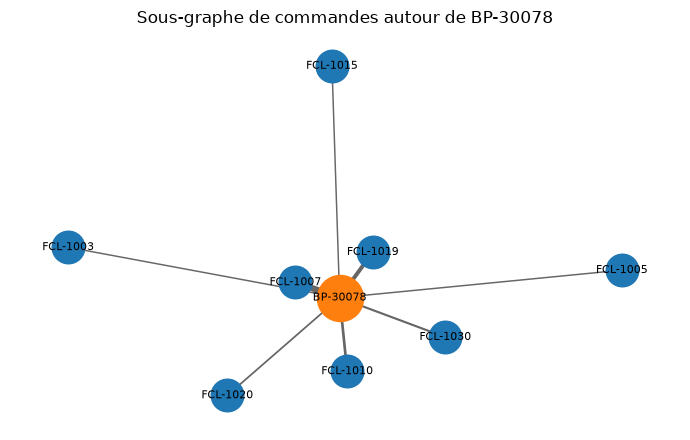

In [31]:
# Étape 6 / graphe 1 — commandes établissements -> partenaires du champ fournisseur.
import networkx as nx
import matplotlib.pyplot as plt

commandes_graphe = pd.read_csv(
    root / "data/processed/logistics/purchase_order_lines.csv", dtype=str, keep_default_na=False
)
partenaires_graphe = pd.read_csv(
    root / "data/processed/logistics/erp_business_partners.csv", dtype=str, keep_default_na=False
)
etablissements_graphe = pd.read_csv(
    root / "data/processed/logistics/erp_facilities.csv", dtype=str, keep_default_na=False
)

# Un poids = nombre de lignes de commande. Aucune somme de prix, devises ou quantités.
cles_liens = ["ordering_facility_code", "supplier_partner_code"]
liens_commandes = commandes_graphe.groupby(cles_liens, as_index=False).agg(
    nombre_lignes=("purchase_order_number", "size")
)
reseau_commandes = nx.Graph()
for code in etablissements_graphe["facility_code"]:
    reseau_commandes.add_node("facility:" + code, type_sommet="facility")
for code in partenaires_graphe["partner_code"]:
    reseau_commandes.add_node("partner:" + code, type_sommet="partner")
for lien in liens_commandes.itertuples(index=False):
    reseau_commandes.add_edge(
        "facility:" + lien.ordering_facility_code,
        "partner:" + lien.supplier_partner_code,
        weight=int(lien.nombre_lignes),
    )
sommets_actifs = [n for n, deg in reseau_commandes.degree() if deg > 0]
reseau_actif = reseau_commandes.subgraph(sommets_actifs).copy()

print("Structure du graphe biparti de commandes :")
display(pd.DataFrame([{
    "lignes_commande": len(commandes_graphe),
    "etablissements_actifs": commandes_graphe["ordering_facility_code"].nunique(),
    "partenaires_observes_comme_fournisseurs": commandes_graphe["supplier_partner_code"].nunique(),
    "sommets_actifs": reseau_actif.number_of_nodes(),
    "aretes_distinctes": reseau_actif.number_of_edges(),
    "sommets_isoles_du_referentiel": reseau_commandes.number_of_nodes() - reseau_actif.number_of_nodes(),
    "composantes_connexes_actives": nx.number_connected_components(reseau_actif),
}]))

stat_partenaire = pd.DataFrame([{
    "partner_code": node.split(":", 1)[1],
    "etablissements_distincts": reseau_actif.degree(node),
    "lignes_commande": int(reseau_actif.degree(node, weight="weight")),
} for node, attributs in reseau_actif.nodes(data=True) if attributs["type_sommet"] == "partner"])
stat_partenaire = stat_partenaire.merge(
    partenaires_graphe[["partner_code", "partner_role_normalized"]],
    on="partner_code", how="left", validate="one_to_one"
)
print("Partenaires les plus présents dans les commandes (nombre de lignes, sans valeur monétaire) :")
display(stat_partenaire.sort_values(
    ["lignes_commande", "etablissements_distincts"], ascending=False
).head(10))

stat_etablissement = pd.DataFrame([{
    "facility_code": node.split(":", 1)[1],
    "partenaires_distincts": reseau_actif.degree(node),
    "lignes_commande": int(reseau_actif.degree(node, weight="weight")),
} for node, attributs in reseau_actif.nodes(data=True) if attributs["type_sommet"] == "facility"])

# Le rôle référentiel ne doit PAS être confondu avec l'utilisation du champ fournisseur.
lignes_roles = commandes_graphe.merge(
    partenaires_graphe[["partner_code", "partner_role_normalized"]],
    left_on="supplier_partner_code", right_on="partner_code", how="left",
    validate="many_to_one"
)
print("Rôles déclarés des partenaires présents dans les lignes de commande :")
display(lignes_roles["partner_role_normalized"].value_counts().rename_axis(
    "role_declare"
).reset_index(name="lignes_commande"))

# Illustration circonscrite au voisinage du partenaire le plus présent, sans mettre les 99 sommets dans une figure illisible.
partenaire_exemple = stat_partenaire.sort_values("lignes_commande", ascending=False).iloc[0]["partner_code"]
voisinage = reseau_actif.subgraph(
    ["partner:" + partenaire_exemple] + list(reseau_actif.neighbors("partner:" + partenaire_exemple))
).copy()
pos = nx.spring_layout(voisinage, seed=17)
fig, ax = plt.subplots(figsize=(7, 4.5))
nx.draw_networkx_nodes(
    voisinage, pos, nodelist=["partner:" + partenaire_exemple],
    node_size=1100, node_color="tab:orange", ax=ax,
)
nx.draw_networkx_nodes(
    voisinage, pos, nodelist=list(voisinage.neighbors("partner:" + partenaire_exemple)),
    node_size=550, node_color="tab:blue", ax=ax,
)
nx.draw_networkx_edges(
    voisinage, pos,
    width=[1 + voisinage[u][v]["weight"] / 15 for u, v in voisinage.edges()],
    alpha=0.6, ax=ax,
)
nx.draw_networkx_labels(
    voisinage, pos,
    labels={node: node.split(":", 1)[1] for node in voisinage.nodes()},
    font_size=8, ax=ax,
)
ax.set_title("Sous-graphe de commandes autour de " + partenaire_exemple)
ax.axis("off")
plt.tight_layout()
plt.show()


### Étape 6 — Premier réseau : commandes et partenaires

Le graphe des commandes relie **30 établissements** à **69 partenaires** : **99 sommets actifs** et **405 relations distinctes**, pour **650 lignes de commande**.

Le partenaire `BP-30078` apparaît sur **111 lignes**, mais auprès de seulement **8 établissements**. Dans le registre, son rôle principal est `carrier`, alors que les commandes l'utilisent comme fournisseur. Cela mérite une vérification des rôles, qui peuvent être multiples.

Ici, une arête signifie **au moins une commande enregistrée**. Elle ne prouve pas une livraison ou un paiement.

### Étape 6 — Graphes dirigés des expéditions et rôle distinct des transporteurs

**Source :** `shipments.csv`, exactement **450 expéditions** identifiées par `(shipment_number, shipment_leg)`. Nous construisons deux **graphes dirigés distincts**, avec une arête pondérée par le **nombre d'expéditions enregistrées** :

- **Réseau partenaires :** `sender_partner_code` **→** `receiver_partner_code` ; le sens exprime uniquement le rôle déclaré d'expéditeur/destinataire dans la même ligne.
- **Réseau d'établissements :** `origin_facility_code` **→** `destination_facility_code` ; le sens exprime départ/destination déclarés. Des **boucles** (même code d'origine et de destination) sont conservées et signalées comme telles.

**Transporteurs :** `carrier_partner_code` décrit un **troisième rôle associé à la même expédition**. Nous le comptons séparément, **sans dessiner une fausse liaison expéditeur → transporteur ni supposer que le transporteur est un arrêt ou le propriétaire de la marchandise**. Un acteur peut cumuler plusieurs rôles dans une même ligne.

**Contrôles :** vérifier les clés uniques, l'existence des références dans les deux registres ERP, les composantes connexes **faiblement** (sans prendre le sens des flèches en compte), les degrés et **volumes d'expéditions**, puis visualiser seulement les flux les plus fréquents. Une liaison prouve une co-déclaration de rôles **dans un enregistrement**, pas une livraison physique vérifiée ni un lien de propriété.

Il est permis de croiser les codes partenaires et établissements **d'une même ligne `shipments`** : cette relation est écrite dans la source. En revanche, **aucune clé de référence directe vers `purchase_order_lines.csv` n'existe** ; on ne fusionne donc pas les 450 expéditions avec les 650 commandes pour reconstruire un flux commande → livraison. Les deux couches peuvent être décrites séparément, mais non jointes transactionnellement par déduction.

Structure des deux graphes dirigés (composantes connexes faibles) :

,couche,sommets,aretes_orientees,expeditions,composantes_faibles,boucles_distinctes
0,expéditeur → destinataire (partenaires),72,334,450,1,0
1,départ → arrivée (établissements),30,234,450,1,7


Flux dirigés les plus fréquents, sans fusion avec les commandes :


,sender_partner_code,receiver_partner_code,nombre_expeditions
309,BP-30078,BP-30021,56
227,BP-30056,BP-30078,33
319,BP-30078,BP-30056,15
146,BP-30035,BP-30042,2
188,BP-30046,BP-30078,2


,origin_facility_code,destination_facility_code,nombre_expeditions
75,FCL-1011,FCL-1007,44
77,FCL-1011,FCL-1010,19
83,FCL-1011,FCL-1019,17
150,FCL-1019,FCL-1011,17
229,FCL-1030,FCL-1024,8


Croisement des deux couches au niveau d'une même ligne (sans référence PO) :


,BP_30078_vers_BP_30021,FCL_1011_vers_FCL_1007,les_deux_sur_la_meme_expedition
0,56,44,42


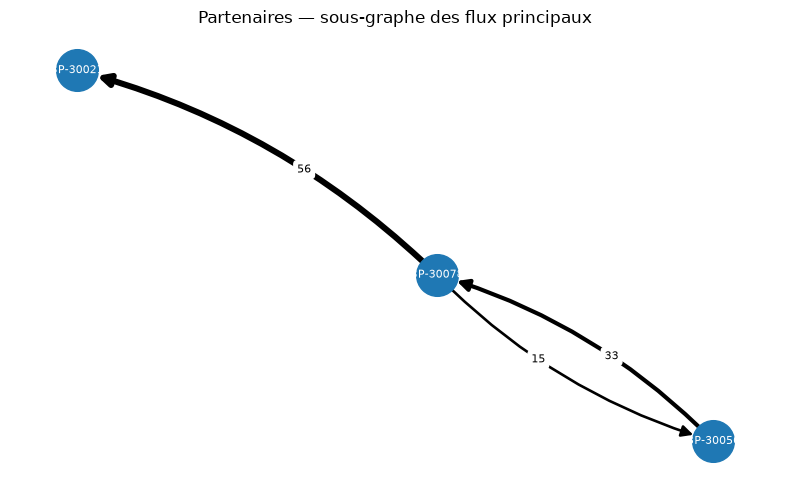

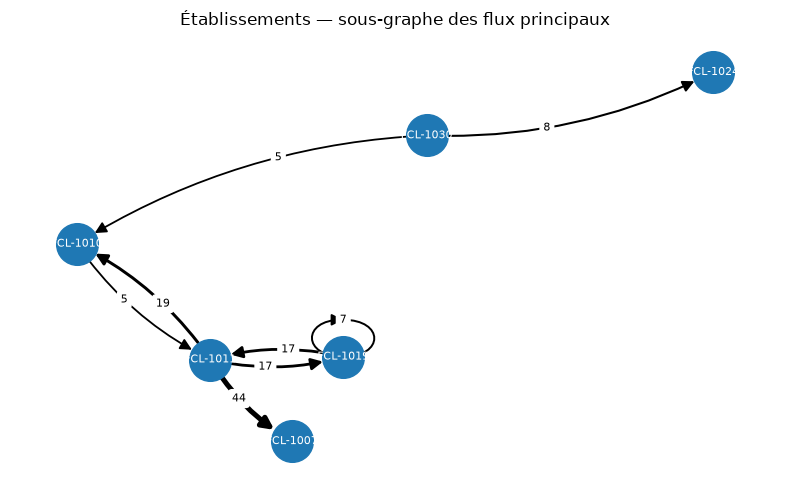

In [32]:
# Étape 6 / graphe 2 — Deux réseaux dirigés et une table de transporteurs.
expeditions_graphe = pd.read_csv(
    root / "data/processed/logistics/shipments.csv", dtype=str, keep_default_na=False
)

references_partenaires = set(partenaires_graphe["partner_code"])
references_etablissements = set(etablissements_graphe["facility_code"])
# Chaque arête A -> B signifie que l'enregistrement nomme A comme origine et B comme destination.
def graphe_dirige_expeditions(donnees, colonne_depart, colonne_arrivee):
    liens = donnees.groupby([colonne_depart, colonne_arrivee], as_index=False).agg(
        nombre_expeditions=("shipment_number", "size")
    )
    graphe = nx.DiGraph()
    graphe.add_nodes_from(set(donnees[colonne_depart]) | set(donnees[colonne_arrivee]))
    for lien in liens.itertuples(index=False):
        graphe.add_edge(
            getattr(lien, colonne_depart), getattr(lien, colonne_arrivee),
            weight=int(lien.nombre_expeditions),
        )
    return graphe, liens

graphe_partenaires_expeditions, flux_partenaires = graphe_dirige_expeditions(
    expeditions_graphe, "sender_partner_code", "receiver_partner_code"
)
graphe_etablissements_expeditions, flux_etablissements = graphe_dirige_expeditions(
    expeditions_graphe, "origin_facility_code", "destination_facility_code"
)

print("Structure des deux graphes dirigés (composantes connexes faibles) :")
display(pd.DataFrame([{
    "couche": "expéditeur → destinataire (partenaires)",
    "sommets": graphe_partenaires_expeditions.number_of_nodes(),
    "aretes_orientees": graphe_partenaires_expeditions.number_of_edges(),
    "expeditions": len(expeditions_graphe),
    "composantes_faibles": nx.number_weakly_connected_components(graphe_partenaires_expeditions),
    "boucles_distinctes": nx.number_of_selfloops(graphe_partenaires_expeditions),
}, {
    "couche": "départ → arrivée (établissements)",
    "sommets": graphe_etablissements_expeditions.number_of_nodes(),
    "aretes_orientees": graphe_etablissements_expeditions.number_of_edges(),
    "expeditions": len(expeditions_graphe),
    "composantes_faibles": nx.number_weakly_connected_components(graphe_etablissements_expeditions),
    "boucles_distinctes": nx.number_of_selfloops(graphe_etablissements_expeditions),
}]))

# Le degré compte des partenaires/établissements distincts ; le degré pondéré compte des expéditions.
def sommets_les_plus_actifs(graphe, sommet_nom, direction):
    lignes = []
    for sommet in graphe.nodes():
        if direction == "sortant":
            degre = graphe.out_degree(sommet)
            poids = graphe.out_degree(sommet, weight="weight")
        else:
            degre = graphe.in_degree(sommet)
            poids = graphe.in_degree(sommet, weight="weight")
        lignes.append({sommet_nom: sommet, "relations_distinctes": degre, "expeditions": int(poids)})
    return pd.DataFrame(lignes).sort_values(
        ["expeditions", "relations_distinctes"], ascending=False
    ).head(5)

print("Flux dirigés les plus fréquents, sans fusion avec les commandes :")
display(flux_partenaires.nlargest(5, "nombre_expeditions"))
display(flux_etablissements.nlargest(5, "nombre_expeditions"))

transporteurs_expeditions = expeditions_graphe["carrier_partner_code"].value_counts().rename_axis(
    "carrier_partner_code"
).reset_index(name="nombre_expeditions")
transporteurs_expeditions = transporteurs_expeditions.merge(
    partenaires_graphe[["partner_code", "partner_role_normalized"]],
    left_on="carrier_partner_code", right_on="partner_code", validate="one_to_one",
).drop(columns="partner_code")

# Croisement VALIDE : les deux relations apparaissent dans la MEME ligne d'expédition.
paire_partenaires = (
    expeditions_graphe["sender_partner_code"].eq("BP-30078")
    & expeditions_graphe["receiver_partner_code"].eq("BP-30021")
)
paire_etablissements = (
    expeditions_graphe["origin_facility_code"].eq("FCL-1011")
    & expeditions_graphe["destination_facility_code"].eq("FCL-1007")
)
print("Croisement des deux couches au niveau d'une même ligne (sans référence PO) :")
display(pd.DataFrame([{
    "BP_30078_vers_BP_30021": int(paire_partenaires.sum()),
    "FCL_1011_vers_FCL_1007": int(paire_etablissements.sum()),
    "les_deux_sur_la_meme_expedition": int((paire_partenaires & paire_etablissements).sum()),
}]))

def afficher_sous_graphe_flux(graphe, liens, col_depart, col_arrivee, titre, n_liens, seed):
    principaux = liens.nlargest(n_liens, "nombre_expeditions")
    petit_graphe = nx.DiGraph()
    for ligne in principaux.itertuples(index=False):
        petit_graphe.add_edge(
            getattr(ligne, col_depart), getattr(ligne, col_arrivee),
            weight=int(ligne.nombre_expeditions),
        )
    positions = nx.spring_layout(petit_graphe, seed=seed, k=1.6)
    fig, ax = plt.subplots(figsize=(8, 5))
    nx.draw_networkx_nodes(petit_graphe, positions, node_size=900, ax=ax)
    nx.draw_networkx_labels(petit_graphe, positions, font_size=8, font_color="white", ax=ax)
    nx.draw_networkx_edges(
        petit_graphe, positions, arrows=True, arrowsize=17,
        arrowstyle="-|>", node_size=900,
        connectionstyle="arc3,rad=0.13",
        width=[1 + 0.06 * data["weight"] for _, _, data in petit_graphe.edges(data=True)],
        ax=ax,
    )
    nx.draw_networkx_edge_labels(
        petit_graphe, positions,
        edge_labels={(u, v): data["weight"] for u, v, data in petit_graphe.edges(data=True)},
        label_pos=0.4, font_size=8, rotate=False,
        connectionstyle="arc3,rad=0.13", ax=ax,
    )
    ax.set_title(titre + " — sous-graphe des flux principaux")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

afficher_sous_graphe_flux(
    graphe_partenaires_expeditions, flux_partenaires,
    "sender_partner_code", "receiver_partner_code", "Partenaires", 3, 10,
)
afficher_sous_graphe_flux(
    graphe_etablissements_expeditions, flux_etablissements,
    "origin_facility_code", "destination_facility_code", "Établissements", 8, 12,
)


### Visualisation — Les trajets entre partenaires les plus fréquents

Les graphes de réseau sont utiles pour voir les liens, mais les étiquettes peuvent vite devenir difficiles à lire. Ce graphique classe simplement les **relations expéditeur → destinataire** par nombre d'expéditions, sans mélanger les quantités transportées.

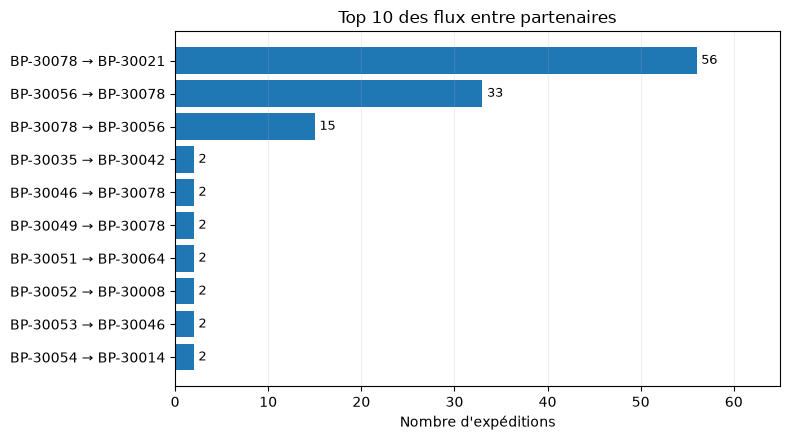

In [33]:
# Les dix arcs dirigés les plus fréquents.
top_flux_partenaires = flux_partenaires.nlargest(10, "nombre_expeditions").copy()
top_flux_partenaires["lien"] = (
    top_flux_partenaires["sender_partner_code"] + " → "
    + top_flux_partenaires["receiver_partner_code"]
)
fig, ax = plt.subplots(figsize=(8, 4.5))
ordre = top_flux_partenaires.iloc[::-1]
ax.barh(ordre["lien"], ordre["nombre_expeditions"])
for j, valeur in enumerate(ordre["nombre_expeditions"]):
    ax.text(valeur + 0.5, j, str(valeur), va="center", fontsize=9)
ax.set_xlim(0, top_flux_partenaires["nombre_expeditions"].max() * 1.16)
ax.set_xlabel("Nombre d'expéditions")
ax.set_title("Top 10 des flux entre partenaires")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### Étape 6 — Réseaux des expéditions

On a construit deux graphes **dirigés** à partir de 450 expéditions :

- **Expéditeur → destinataire** : **72 partenaires** et **334 relations orientées**.
- **Établissement de départ → d'arrivée** : **30 établissements** et **234 relations orientées**.

Les flux les plus fréquents sont `BP-30078 → BP-30021` (**56 expéditions**) et `FCL-1011 → FCL-1007` (**44**). Dans **42 lignes**, ces deux relations apparaissent ensemble sur **la même expédition** : ce rapprochement est donc justifié.

On trouve aussi **22 expéditions** dont les établissements d'origine et de destination sont identiques. Cela peut correspondre à des mouvements internes ou à une convention de saisie. Le transporteur est compté comme **un rôle**, pas comme une étape de trajet inventée.

### Étape 6 — Concentration des flux et détection exploratoire de communautés

**Deux questions distinctes :** (1) les **relations dirigées** entre certains acteurs concentrent-elles une grande proportion des expéditions ? (2) en ignorant provisoirement le sens des flèches, existe-t-il des **groupes de sommets plus connectés entre eux que vers le reste du réseau**, au sens de la *modularité* ? Une communauté de graphe n'est **pas** une organisation, une relation de propriété ni une preuve de coordination.

**Concentration :** pour les réseaux *partenaire expéditeur → partenaire destinataire* et *établissement de départ → établissement d'arrivée*, on trie les arêtes par **nombre d'expéditions**, puis on calcule les parts des 1, 3 et 5 relations les plus fréquentes. Une relation est **orientée** et sa répétition ne renseigne ni le tonnage ni la valeur marchande.

**Communautés :** l'algorithme de maximisation gloutonne de la modularité (`networkx.community.greedy_modularity_communities`) travaille sur une **projection non dirigée** : les flux `A → B` et `B → A` deviennent un lien `A — B` pondéré par la **somme des deux fréquences** ; on ne perd pas les données orientées, conservées pour le diagnostic des flux. Les **boucles** d'un établissement vers lui-même sont **retirées seulement pour la détection des communautés** afin qu'elles ne façonnent pas artificiellement la segmentation ; elles restent recensées dans le jeu de données. Les chiffres de flux internes des communautés excluent également ces boucles lorsqu'on parle de liens entre acteurs distincts.

**Modularité Q :** score mesurant la séparation de la partition **sur le graphe choisi**, selon un modèle de référence interne à la métrique. Il ne s'agit **ni d'une probabilité d'irrégularité**, ni d'un test de significativité de la coopération. On compare avec l'algorithme **sans pondération**, puis on atténue le poids de l'arête dirigée la plus fréquente **dans une copie temporaire du graphe** pour contrôler la sensibilité : les données originales ne sont jamais modifiées. Le nombre et la composition des groupes peuvent changer lorsque les poids changent.

Concentration des flux et communautés :


,couche,acteurs,relations_dirigees,flux_top_1,flux_top_3,part_top_3_%,groupes_ponderes,Q_ponderee,groupes_non_ponderes,Q_non_ponderee,groupes_si_poids_dominant_1,expeditions_boucles_exclues,expeditions_internes_hors_boucles,expeditions_hors_boucles
0,partenaires,72,334,56,104,23.1,5,0.38,4,0.278,6,0,268,450
1,établissements,30,234,44,80,17.8,3,0.19,3,0.150,4,22,240,428


Communautés partenaires — effectifs et flux internes, hors boucles :


,communaute,nombre_sommets,expeditions_entre_acteurs_distincts
0,G1,21,53
1,G2,18,43
2,G3,17,42
3,G4,13,26
4,G5,3,104


Communautés établissements — effectifs et flux internes, hors boucles :


,communaute,nombre_sommets,expeditions_entre_acteurs_distincts
0,G1,14,67
1,G2,9,37
2,G3,7,136


Lignes d'expédition internes au trio : 104


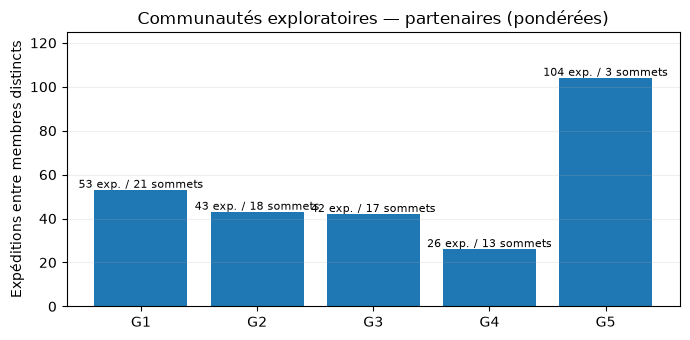

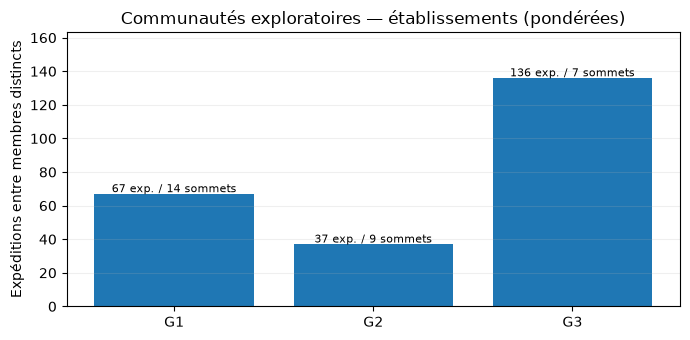

Résultat descriptif : les partitions dépendent du choix des poids et des règles de projection.


In [34]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

expeditions_communautes = pd.read_csv(
    root / "data/processed/logistics/shipments.csv", dtype=str, keep_default_na=False
)

def obtenir_graphe_sans_sens(graphe_dirige):
    """Conserver les poids totaux A->B et B->A, retirer les boucles pour les communautés."""
    g_non_dirige = nx.Graph()
    g_non_dirige.add_nodes_from(graphe_dirige.nodes())
    for depart, arrivee, attributs in graphe_dirige.edges(data=True):
        precedent = g_non_dirige.get_edge_data(depart, arrivee, {}).get("weight", 0)
        g_non_dirige.add_edge(depart, arrivee, weight=precedent + attributs["weight"])
    g_non_dirige.remove_edges_from(list(nx.selfloop_edges(g_non_dirige)))
    return g_non_dirige

def analyser_concentration_communautes(donnees, depart_col, arrivee_col, couche):
    liens = donnees.groupby([depart_col, arrivee_col], as_index=False).agg(
        nombre_expeditions=("shipment_number", "size")
    )
    reseau = nx.from_pandas_edgelist(
        liens, source=depart_col, target=arrivee_col,
        edge_attr="nombre_expeditions", create_using=nx.DiGraph(),
    )
    # Le poids est le nombre de lignes, pas une somme de produits physiques.
    for _, _, d in reseau.edges(data=True):
        d["weight"] = int(d["nombre_expeditions"])
    graphe_communaute = obtenir_graphe_sans_sens(reseau)
    communautes_ponderees = list(nx.community.greedy_modularity_communities(
        graphe_communaute, weight="weight"
    ))
    communautes_sans_poids = list(nx.community.greedy_modularity_communities(
        graphe_communaute, weight=None
    ))
    groupes = {sommet: identifiant for identifiant, membres in enumerate(communautes_ponderees)
              for sommet in membres}
    volumes_internes = []
    for i, membres in enumerate(communautes_ponderees):
        n_interne = sum(
            d["weight"] for u, v, d in reseau.edges(data=True)
            if u != v and u in membres and v in membres
        )
        volumes_internes.append({
            "communaute": f"G{i+1}", "nombre_sommets": len(membres),
            "expeditions_entre_acteurs_distincts": int(n_interne),
        })
    n_boucles = sum(
        d["weight"] for u, v, d in reseau.edges(data=True) if u == v
    )
    n_internes = sum(ligne["expeditions_entre_acteurs_distincts"] for ligne in volumes_internes)
    # Sensibilité au poids dominant, sur copie issue d'une nouvelle table d'arêtes.
    liens_avec_poids_reduit = liens.copy()
    liens_avec_poids_reduit.loc[
        liens_avec_poids_reduit["nombre_expeditions"].idxmax(), "nombre_expeditions"
    ] = 1
    reseau_reduit = nx.from_pandas_edgelist(
        liens_avec_poids_reduit, depart_col, arrivee_col,
        edge_attr="nombre_expeditions", create_using=nx.DiGraph(),
    )
    for _, _, d in reseau_reduit.edges(data=True):
        d["weight"] = int(d["nombre_expeditions"])
    projection_reduite = obtenir_graphe_sans_sens(reseau_reduit)
    communautes_reduites = list(nx.community.greedy_modularity_communities(
        projection_reduite, weight="weight"
    ))

    liens_tries = liens.sort_values("nombre_expeditions", ascending=False)
    bilan = {
        "couche": couche,
        "acteurs": reseau.number_of_nodes(),
        "relations_dirigees": reseau.number_of_edges(),
        "flux_top_1": int(liens_tries["nombre_expeditions"].head(1).sum()),
        "flux_top_3": int(liens_tries["nombre_expeditions"].head(3).sum()),
        "part_top_3_%": round(100 * liens_tries["nombre_expeditions"].head(3).sum() / len(donnees), 1),
        "groupes_ponderes": len(communautes_ponderees),
        "Q_ponderee": round(nx.community.modularity(
            graphe_communaute, communautes_ponderees, weight="weight"
        ), 3),
        "groupes_non_ponderes": len(communautes_sans_poids),
        "Q_non_ponderee": round(nx.community.modularity(
            graphe_communaute, communautes_sans_poids, weight=None
        ), 3),
        "groupes_si_poids_dominant_1": len(communautes_reduites),
        "expeditions_boucles_exclues": int(n_boucles),
        "expeditions_internes_hors_boucles": int(n_internes),
        "expeditions_hors_boucles": len(donnees) - int(n_boucles),
    }
    return bilan, pd.DataFrame(volumes_internes), liens_tries, groupes

resultat_partenaires, communautes_partenaires, liens_ordonnes_partenaires, groupe_partenaires = (
    analyser_concentration_communautes(
        expeditions_communautes, "sender_partner_code", "receiver_partner_code", "partenaires"
    )
)
resultat_etablissements, communautes_etablissements, liens_ordonnes_etablissements, groupe_etablissements = (
    analyser_concentration_communautes(
        expeditions_communautes, "origin_facility_code", "destination_facility_code", "établissements"
    )
)

print("Concentration des flux et communautés :")
display(pd.DataFrame([resultat_partenaires, resultat_etablissements]))
print("Communautés partenaires — effectifs et flux internes, hors boucles :")
display(communautes_partenaires)
print("Communautés établissements — effectifs et flux internes, hors boucles :")
display(communautes_etablissements)

# Contrôle méthodologique visible : l'algorithme sans poids ne garde pas nécessairement
groupe_trio = {groupe_partenaires[p] for p in ["BP-30078", "BP-30021", "BP-30056"]}
print("Lignes d'expédition internes au trio :", int(
    expeditions_communautes[
        expeditions_communautes["sender_partner_code"].isin(
            ["BP-30078", "BP-30021", "BP-30056"]
        ) & expeditions_communautes["receiver_partner_code"].isin(
            ["BP-30078", "BP-30021", "BP-30056"]
        )
    ].shape[0]
))

# Deux figures autonomes, chacune illustrant les volumes INTERNES de la partition retenue.
for couche, table in [
    ("partenaires", communautes_partenaires),
    ("établissements", communautes_etablissements),
]:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(
        table["communaute"], table["expeditions_entre_acteurs_distincts"]
    )
    for i, (y, taille) in enumerate(zip(
        table["expeditions_entre_acteurs_distincts"], table["nombre_sommets"]
    )):
        ax.text(i, y + 1, f"{y} exp. / {taille} sommets", ha="center", fontsize=8)
    ax.set_ylim(0, max(table["expeditions_entre_acteurs_distincts"]) * 1.2)
    ax.set_ylabel("Expéditions entre membres distincts")
    ax.set_title(f"Communautés exploratoires — {couche} (pondérées)")
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()

print("Résultat descriptif : les partitions dépendent du choix des poids et des règles de projection.")


### Étape 6 — Concentration et communautés

Les **trois principales relations entre partenaires** représentent **104/450 expéditions (23,1 %)**. Côté établissements, les trois principales relations représentent **80/450 (17,8 %)**.

En regroupant les liens réciproques et en utilisant leur fréquence comme poids, l'algorithme trouve **5 communautés de partenaires** (`Q ≈ 0,380`) et **3 communautés d'établissements** (`Q ≈ 0,190`). Un groupe de trois partenaires (`BP-30078`, `BP-30021`, `BP-30056`) concentre **104 expéditions entre ses membres**.

Quand on ignore les poids ou qu'on modifie la relation dominante, les groupes changent. **Une communauté de graphe n'est pas une preuve de coordination** : c'est surtout une façon de décrire la structure des échanges.

## Bilan de l’étape 6 — Graph Mining

Les graphes montrent des **relations fréquentes** entre certains établissements et partenaires. On a distingué les liens des commandes, ceux des expéditions et les rôles des transporteurs.

La relation entre les deux graphes d'une **même expédition** est vérifiable, mais il n'existe **pas de clé directe entre commande et expédition**. On ne peut donc pas reconstruire une chaîne complète en rapprochant seulement des acteurs ou des dates.

Les mesures de centralité et les communautés sont utiles pour choisir des pistes à examiner. **Elles ne démontrent pas de collusion ni d'irrégularité.**

## Étape 7 — Premier contrôle : chaîne du froid déclarée et capacités de stockage ERP

**Question :** les expéditions portant la classe de température `2-8C` ou `frozen` sont-elles cohérentes **documentairement** avec les capacités de stockage listées pour leurs établissements d'origine et de destination ? Nous ne vérifions **pas** le respect réel de la température : le jeu de données ne fournit **aucun relevé de sonde, aucune courbe de température**, aucune preuve de qualification du véhicule et aucun protocole d'entreposage.

**Sources précises :** `shipments.csv` (`temperature_control_class_normalized`, `item_category`, statuts et codes d'établissements) et `erp_facilities.csv` (`storage_capabilities`). Les listes `storage_capabilities` sont séparées par `;`, avec des valeurs telles que `ambient`, `2-8C`, `frozen`, `secure_cage`, `controlled_access`. Nous normalisons la casse **en mémoire** pour comparer exactement `2-8c` ou `frozen` aux éléments de la liste, sans confondre les classes ou créer une hiérarchie implicite (`frozen` n'est pas interchangeable avec `2-8C`).

Pour **chaque extrémité du transport**, trois observations distinctes :

- **`listée` :** la classe du transport figure explicitement dans les capacités de **stockage** de l'établissement ;
- **`non listée` :** un champ de capacités est rempli, mais n'inclut pas explicitement cette classe ;
- **`non documentée` :** le champ `storage_capabilities` est vide, ce qui ne permet **aucune conclusion de compatibilité**.

**Attention à la portée de la comparaison :** un site d'origine peut simplement servir de lieu de transit sans stocker le produit ; une classe absente du champ **ne prouve pas l'absence effective d'une installation adaptée**, et une classe présente **ne prouve pas** une température maîtrisée durant le trajet. L'observation relève d'une **cohérence du référentiel**, pas d'une non-conformité avérée. On distinguera aussi les cas `in_transit`, déjà étudiés à l'étape 5, sans leur inventer une date d'arrivée.

Classes de température déclarées pour les 450 expéditions :


,classe_temperature,expeditions
0,ambient,343
1,2-8c,103
2,frozen,4


Catégories de marchandises sensibles (classe déclarée) :
Confrontation classe transport / capacités de STOCKAGE listées, par extrémité :


,origine,destination
état_documentaire,,
listée,36,78
non listée,69,25
non documentée,2,4


Combinaisons origine × destination, sur les 107 expéditions à température contrôlée :


destination_documentation,listée,non listée,non documentée
origine_documentation,,,
listée,22,12,2
non listée,56,11,2
non documentée,0,2,0


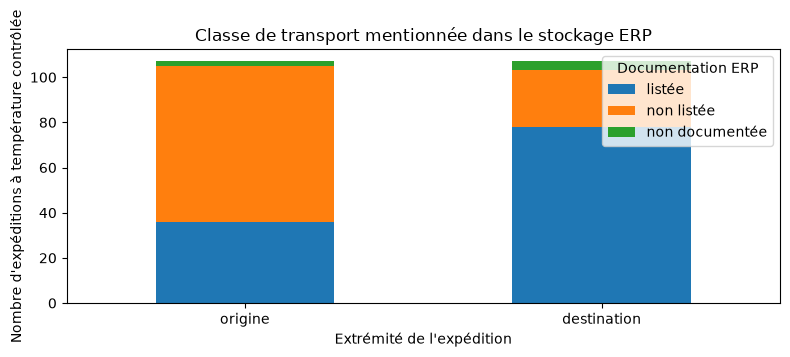

Expéditions sensibles toujours en statut in_transit (sans preuve de température réelle) :


,shipment_number,dispatch_time_normalized,item_category,temperature_control_class_normalized,origin_facility_code,destination_facility_code,origine_documentation,destination_documentation
295,SHP-2022-00061,2022-12-11T18:00:00,medical_consumables,2-8c,FCL-1011,FCL-1007,non listée,listée
342,SHP-2023-00047,2023-09-06T13:00:00,biological_sample,2-8c,FCL-1003,FCL-1011,listée,non listée
419,SHP-2025-00004,2025-04-03T11:00:00,medical_consumables,2-8c,FCL-1011,FCL-1007,non listée,listée


In [35]:
# Étape 7 / contrôle documentaire : classes de transport VS stockage déclaré des établissements.
import pandas as pd
import matplotlib.pyplot as plt

expeditions_froid = pd.read_csv(
    root / "data/processed/logistics/shipments.csv", dtype=str, keep_default_na=False
)
etablissements_froid = pd.read_csv(
    root / "data/processed/logistics/erp_facilities.csv", dtype=str, keep_default_na=False
)

def classe_documentee(classe_transport, capacites_stockage):
    if not isinstance(capacites_stockage, str) or not capacites_stockage.strip():
        return "non documentée"
    elements = {v.strip().lower() for v in capacites_stockage.split(";") if v.strip()}
    return "listée" if classe_transport in elements else "non listée"

for cote, colonne_code in [
    ("origine", "origin_facility_code"),
    ("destination", "destination_facility_code"),
]:
    infos = etablissements_froid[["facility_code", "facility_category", "storage_capabilities"]].rename(
        columns={"facility_code": colonne_code,
                 "facility_category": cote + "_categorie_etablissement",
                 "storage_capabilities": cote + "_capacites_stockage"}
    )
    expeditions_froid = expeditions_froid.merge(
        infos, on=colonne_code, how="left", validate="many_to_one", indicator=True
    )
    expeditions_froid = expeditions_froid.drop(columns="_merge")
    expeditions_froid[cote + "_documentation"] = expeditions_froid.apply(
        lambda ligne: classe_documentee(
            ligne["temperature_control_class_normalized"],
            ligne[cote + "_capacites_stockage"],
        ),
        axis=1,
    )

froid = expeditions_froid.loc[
    expeditions_froid["temperature_control_class_normalized"].isin(["2-8c", "frozen"])
].copy()
print("Classes de température déclarées pour les 450 expéditions :")
display(expeditions_froid["temperature_control_class_normalized"].value_counts().rename_axis(
    "classe_temperature"
).reset_index(name="expeditions"))

print("Catégories de marchandises sensibles (classe déclarée) :")

ordre_etats = ["listée", "non listée", "non documentée"]
bilan_capacites = pd.DataFrame({
    "origine": froid["origine_documentation"].value_counts().reindex(ordre_etats, fill_value=0),
    "destination": froid["destination_documentation"].value_counts().reindex(ordre_etats, fill_value=0),
}).rename_axis("état_documentaire")
print("Confrontation classe transport / capacités de STOCKAGE listées, par extrémité :")
display(bilan_capacites)

print("Combinaisons origine × destination, sur les 107 expéditions à température contrôlée :")
display(pd.crosstab(
    froid["origine_documentation"], froid["destination_documentation"]
).reindex(index=ordre_etats, columns=ordre_etats, fill_value=0))

les_deux_listees = (
    froid["origine_documentation"].eq("listée")
    & froid["destination_documentation"].eq("listée")
)

# Illustration catégorielle : effectifs, pas degrés de conformité.
fig, ax = plt.subplots(figsize=(8, 3.5))
bilan_capacites.T[ordre_etats].plot(kind="bar", stacked=True, ax=ax)
ax.set_ylabel("Nombre d'expéditions à température contrôlée")
ax.set_xlabel("Extrémité de l'expédition")
ax.set_title("Classe de transport mentionnée dans le stockage ERP")
ax.legend(title="Documentation ERP", loc="upper right")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("Expéditions sensibles toujours en statut in_transit (sans preuve de température réelle) :")
display(froid.loc[
    froid["shipment_status_normalized"].eq("in_transit"),
    ["shipment_number", "dispatch_time_normalized", "item_category",
     "temperature_control_class_normalized", "origin_facility_code",
     "destination_facility_code", "origine_documentation", "destination_documentation"],
])


### Étape 7 — Premier bilan sur la chaîne du froid

Sur **450 expéditions**, **107** déclarent une classe de température contrôlée : **103 `2-8c`** et **4 `frozen`**. Cela concerne **52 échantillons biologiques**, **51 consommables médicaux** et **4 produits agricoles**.

La classe de transport figure dans les capacités de **stockage déclarées** de l'établissement de départ pour **36 expéditions**, et dans celles du lieu d'arrivée pour **78**. Elle est listée **aux deux extrémités pour 22 expéditions seulement**.

`FCL-1011`, classé `office` avec une capacité `ambient`, apparaît comme origine de **43 expéditions sensibles**. Il peut s'agir d'un simple point de transit : **le référentiel de stockage ne permet pas de connaître la température réelle pendant le transport**.

Enfin, **3 expéditions sensibles** sont marquées `in_transit` ; elles font déjà partie des 17 cas étudiés plus haut.

### Étape 7 — Itinéraires sensibles et recherche de références documentaires explicites

**Question :** sur les **107 expéditions** dont la classe déclarée est `2-8c` ou `frozen`, quels **itinéraires sont récurrents** et quels autres fichiers **renvoient explicitement au même `shipment_number`** ? Cette analyse est documentaire, **pas une preuve de température maintenue**.

**Relations justifiées :**

- **Itinéraires :** les champs `origin_facility_code` et `destination_facility_code`, et séparément `sender_partner_code` → `receiver_partner_code`, proviennent d'une **même ligne d'expédition**. Leur fréquence compte des **expéditions**, pas des tonnes, des prix ou des marchandises mélangées.
- **Références directes :** `institutional_memos.csv`, `regulatory_case_events.csv` et `inventory_adjustments.csv` possèdent chacun une colonne **`related_shipment_number`**. On ne relie un enregistrement à une expédition que si l'identifiant **correspond exactement**. Un dossier réglementaire contient souvent **plusieurs événements** : le nombre d'événements ne mesure pas le nombre d'expéditions ni de preuves indépendantes.
- **Revue chronologique :** le **jour** du document/événement/ajustement est comparé au **jour** du départ de l'expédition, afin de ne pas considérer à tort un document daté du jour du départ comme antérieur au départ parce que son heure est inconnue. Un renvoi antérieur au départ est **à examiner**, mais certains documents peuvent exister avant le transport (programmation, inspection préalable) : il ne prouve donc pas automatiquement une erreur.
- **Contrôle de l'ajustement :** en présence d'une référence à une expédition, on vérifie séparément si sa **catégorie**, son **unité** et son **établissement** correspondent respectivement à ceux de l'expédition ou à une de ses extrémités. Une référence documentaire ne signifie pas automatiquement que la quantité de l'ajustement peut être ajoutée à la quantité expédiée.

**Limites :** les mémos sont des textes administratifs ; les événements réglementaires décrivent des procédures ou des plaintes diverses ; les ajustements sont des écritures de stock. Aucun de ces champs **ne contient de relevés de température**, de qualification du véhicule, ni de preuve physique d'une excursion ou d'une absence d'excursion. Les 40 documents de `public_and_investigative_documents.csv` ne possèdent **aucun champ de clé `related_shipment_number`** : un éventuel rapprochement fondé sur une ressemblance de thèmes ou de dates serait insuffisant. Aucune pièce n'est modifiée.

Principaux trajets entre établissements (107 expéditions contrôlées en température) :


,origin_facility_code,destination_facility_code,expeditions,part_du_total_%
14,FCL-1011,FCL-1007,19,17.8
15,FCL-1011,FCL-1010,16,15.0
30,FCL-1019,FCL-1019,7,6.5
48,FCL-1030,FCL-1024,7,6.5
17,FCL-1011,FCL-1019,5,4.7
35,FCL-1020,FCL-1020,4,3.7
16,FCL-1011,FCL-1011,2,1.9
29,FCL-1019,FCL-1011,2,1.9
36,FCL-1020,FCL-1023,2,1.9
46,FCL-1030,FCL-1010,2,1.9


Couverture documentaire — événements et expéditions ne sont pas interchangeables :


,source,lignes_avec_reference_directe,expeditions_distinctes,lignes_datees_avant_depart,expeditions_avec_reference_anterieure,dates_non_interpretables
0,mémos,1,1,1,1,0
1,événements réglementaires,74,10,31,6,0
2,ajustements de stock,21,21,2,2,0


Couverture des trois types de documents, après dédoublonnage par expédition :


,expeditions_sensibles,avec_au_moins_une_reference_directe,sans_reference_directe_dans_ces_trois_sources
0,107,22,85


... (2 outputs left out)

Rapprochements à examiner si la catégorie, l'unité ou l'établissement ne concordent pas :


,adjustment_number,adjustment_date,related_shipment_number,item_category,categorie_expedition,unit,declared_unit,facility_code,origin_facility_code,destination_facility_code
0,ADJ-2018-00014,2018-02-18,SHP-2023-00029,agricultural_product,medical_consumables,pallet,case,FCL-1027,FCL-1018,FCL-1011
15,ADJ-2024-00116,21-Mar-2024,SHP-2016-00013,medical_consumables,medical_consumables,case,case,FCL-1025,FCL-1011,FCL-1007


Les trois expéditions sensibles sans arrivée — état des références directes :


,shipment_number,dispatch_time_normalized,item_category,reference_memo,reference_reglementaire,reference_ajustement
295,SHP-2022-00061,2022-12-11T18:00:00,medical_consumables,False,False,False
342,SHP-2023-00047,2023-09-06T13:00:00,biological_sample,False,False,True
419,SHP-2025-00004,2025-04-03T11:00:00,medical_consumables,False,False,False


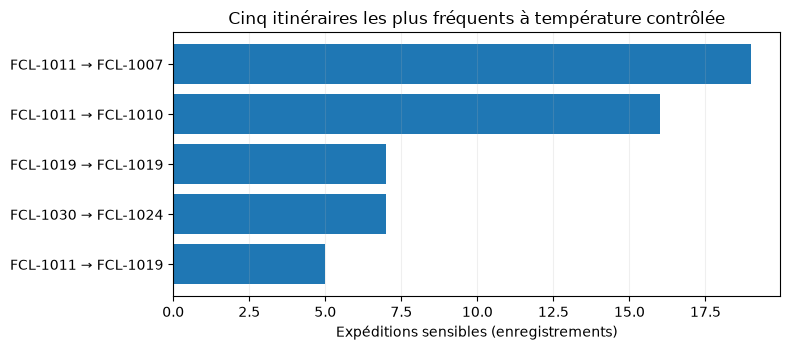

In [36]:
# Étape 7 / itinéraires sensibles et traçabilité documentaire explicite.
import pandas as pd
import matplotlib.pyplot as plt

expeditions_documents = pd.read_csv(
    root / "data/processed/logistics/shipments.csv", dtype=str, keep_default_na=False
)
sensibles_docs = expeditions_documents.loc[
    expeditions_documents["temperature_control_class_normalized"].isin(["2-8c", "frozen"])
].copy()
sensibles_docs["jour_depart"] = pd.to_datetime(
    sensibles_docs["dispatch_time_normalized"], errors="raise"
).dt.normalize()

# Compter uniquement les lignes de transport : jamais les quantités dans des unités différentes.
itineraires_sensibles = sensibles_docs.groupby([
    "origin_facility_code", "destination_facility_code"
], as_index=False).agg(expeditions=("shipment_number", "size"))
itineraires_sensibles["part_du_total_%"] = (
    100 * itineraires_sensibles["expeditions"] / len(sensibles_docs)
).round(1)
itineraires_sensibles = itineraires_sensibles.sort_values(
    ["expeditions", "origin_facility_code", "destination_facility_code"],
    ascending=[False, True, True]
)
flux_partenaire_sensibles = sensibles_docs.groupby([
    "sender_partner_code", "receiver_partner_code"
], as_index=False).agg(expeditions=("shipment_number", "size"))
flux_partenaire_sensibles = flux_partenaire_sensibles.sort_values(
    ["expeditions", "sender_partner_code", "receiver_partner_code"],
    ascending=[False, True, True]
)
print("Principaux trajets entre établissements (107 expéditions contrôlées en température) :")
display(itineraires_sensibles.head(10))

# Lecture des clés documentaires, uniquement les correspondances exactes de shipment_number.
base_docs = root / "data"
# 'root' pointe vers la racine du projet ; les fichiers des registres sont sous data/.
memos_documents = pd.read_csv(
    root / "data/public_records/institutional_memos.csv", dtype=str, keep_default_na=False
)
evenements_documents = pd.read_csv(
    root / "data/public_records/regulatory_case_events.csv", dtype=str, keep_default_na=False
)
ajustements_documents = pd.read_csv(
    root / "data/logistics/inventory_adjustments.csv", dtype=str, keep_default_na=False
)

specification_sources = [
    ("mémos", memos_documents, "document_date", "document_id"),
    ("événements réglementaires", evenements_documents, "event_time", "regulatory_event_id"),
    ("ajustements de stock", ajustements_documents, "adjustment_date", "adjustment_number"),
]
liens_explicitement_documentes = {}
resume_documents = []
for source, table, champ_date, champ_id in specification_sources:
    lignes = table.loc[
        table["related_shipment_number"].isin(sensibles_docs["shipment_number"])
    ].copy()
    lignes = lignes.merge(
        sensibles_docs[["shipment_number", "jour_depart", "item_category",
                         "declared_unit", "origin_facility_code",
                         "destination_facility_code", "shipment_status_normalized"]].rename(
            columns={"item_category": "categorie_expedition"}
        ),
        left_on="related_shipment_number", right_on="shipment_number",
        how="inner", validate="many_to_one",
    )
    lignes["jour_document"] = pd.to_datetime(
        lignes[champ_date], format="mixed", errors="coerce"
    ).dt.normalize()
    lignes["date_anterieure_depart"] = lignes["jour_document"].lt(lignes["jour_depart"])
    liens_explicitement_documentes[source] = lignes
    resume_documents.append({
        "source": source,
        "lignes_avec_reference_directe": len(lignes),
        "expeditions_distinctes": lignes["shipment_number"].nunique(),
        "lignes_datees_avant_depart": int(lignes["date_anterieure_depart"].sum()),
        "expeditions_avec_reference_anterieure": lignes.loc[
            lignes["date_anterieure_depart"], "shipment_number"
        ].nunique(),
        "dates_non_interpretables": int(lignes["jour_document"].isna().sum()),
    })

print("Couverture documentaire — événements et expéditions ne sont pas interchangeables :")
display(pd.DataFrame(resume_documents))
identifiants_documentes = set().union(*[
    set(t["shipment_number"]) for t in liens_explicitement_documentes.values()
])
print("Couverture des trois types de documents, après dédoublonnage par expédition :")
display(pd.DataFrame([{
    "expeditions_sensibles": len(sensibles_docs),
    "avec_au_moins_une_reference_directe": len(identifiants_documentes),
    "sans_reference_directe_dans_ces_trois_sources":
        len(sensibles_docs) - len(identifiants_documentes),
}]))

liens_ajustements = liens_explicitement_documentes["ajustements de stock"].copy()
liens_ajustements["categorie_compatible"] = liens_ajustements["item_category"].eq(
    liens_ajustements["categorie_expedition"]
)
liens_ajustements["unite_compatible"] = liens_ajustements["unit"].eq(
    liens_ajustements["declared_unit"]
)
liens_ajustements["etablissement_dans_trajet"] = (
    liens_ajustements["facility_code"].eq(liens_ajustements["origin_facility_code"])
    | liens_ajustements["facility_code"].eq(liens_ajustements["destination_facility_code"])
)
print("Qualité des liens explicites des ajustements vers les expéditions sensibles :")
display(pd.DataFrame([{
    "ajustements_cites": len(liens_ajustements),
    "categorie_egale": int(liens_ajustements["categorie_compatible"].sum()),
    "unite_egale": int(liens_ajustements["unite_compatible"].sum()),
    "etablissement_correspond_a_une_extremite": int(liens_ajustements["etablissement_dans_trajet"].sum()),
    "references_anterieures_au_jour_du_depart": int(liens_ajustements["date_anterieure_depart"].sum()),
}]))
print("Rapprochements à examiner si la catégorie, l'unité ou l'établissement ne concordent pas :")
display(liens_ajustements.loc[
    ~liens_ajustements["categorie_compatible"]
    | ~liens_ajustements["unite_compatible"]
    | ~liens_ajustements["etablissement_dans_trajet"],
    ["adjustment_number", "adjustment_date", "related_shipment_number",
     "item_category", "categorie_expedition", "unit", "declared_unit",
     "facility_code", "origin_facility_code", "destination_facility_code"],
])

liens_reglementaires = liens_explicitement_documentes["événements réglementaires"]

print("Les trois expéditions sensibles sans arrivée — état des références directes :")
transit_sensible = sensibles_docs.loc[
    sensibles_docs["shipment_status_normalized"].eq("in_transit"),
    ["shipment_number", "dispatch_time_normalized", "item_category"]
].copy()
for source, table in liens_explicitement_documentes.items():
    transit_sensible["reference_" + {
        "mémos": "memo", "événements réglementaires": "reglementaire",
        "ajustements de stock": "ajustement",
    }[source]] = transit_sensible["shipment_number"].isin(set(table["shipment_number"]))
display(transit_sensible)

principaux_trajets = itineraires_sensibles.head(5).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(
    principaux_trajets["origin_facility_code"] + " → " + principaux_trajets["destination_facility_code"],
    principaux_trajets["expeditions"],
)
ax.set_xlabel("Expéditions sensibles (enregistrements)")
ax.set_title("Cinq itinéraires les plus fréquents à température contrôlée")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


### Étape 7 — Itinéraires sensibles et documents liés

Les deux trajets sensibles les plus fréquents sont `FCL-1011 → FCL-1007` (**19 expéditions**) et `FCL-1011 → FCL-1010` (**16**), soit **35 sur 107**.

En suivant uniquement les identifiants explicites, on retrouve **22 expéditions sensibles distinctes** citées dans au moins une des trois sources étudiées : mémos, événements réglementaires ou ajustements. Les **74 événements réglementaires** associés ne concernent que **10 expéditions** : plusieurs événements appartiennent à un même dossier.

Sur les **21 ajustements** rapprochés, **20** correspondent à la catégorie et à l'unité de l'expédition, et **19** mentionnent un des deux établissements du trajet. `ADJ-2018-00014`, lié à `SHP-2023-00029`, présente des désaccords de date, de catégorie, d'unité et d'établissement. Le mémo `MEM-510128` (2018) cite lui aussi un transport plus tardif (2020).

**Un lien documentaire existe dans ces cas, mais sa fiabilité et son sens restent à vérifier.**

## Bilan de l’étape 7 — Expéditions sensibles

On retrouve **107 expéditions à température contrôlée**. Pour **22**, la classe de transport figure dans les capacités de stockage déclarées **des deux établissements** ; pour **85**, au moins un côté n'a pas de correspondance explicite.

On a aussi identifié des **itinéraires récurrents** et des **références documentaires à vérifier**, notamment les ajustements dont les informations ne correspondent pas à l'expédition citée. Trois expéditions sensibles n'ont pas de date d'arrivée enregistrée.

**Conclusion :** ces résultats montrent des limites de documentation. Ils ne prouvent **aucune rupture de la chaîne du froid** : on n'a ni relevés de température, ni preuves sur les conditions réelles de stockage et de transport.

## Étape 8 — Premier croisement entre ERP, registre d'entités et déclarations de dirigeants

**Question :** les `external_registration_number` des **80 partenaires ERP** figurent-ils dans `registered_entities.csv` et les informations déclarées sont-elles cohérentes au niveau des **identifiants exacts** ? Peut-on ensuite constater des lignes de commande impliquant des acteurs dont le **statut actuel** dans ce registre est `dissolved` ?

**Sources :** `data/processed/logistics/erp_business_partners.csv`, `data/public_records/registered_entities.csv`, `data/public_records/officer_filings.csv`, `data/processed/logistics/purchase_order_lines.csv`, `data/processed/logistics/shipments.csv`.

**Règles de preuve :**

- **Jointure exacte** `external_registration_number = registration_number`. Les valeurs **vides** sont séparées des références **renseignées mais absentes** de ce registre partiel. Ces deux situations ne démontrent pas que l'acteur est illégal ou inexistant.
- Comparer **les noms exacts normalisés en minuscules/espaces**, `partner_status` et `current_status` sans présumer que le vocabulaire ERP est l'équivalent juridique du registre. Un enregistrement `active` ou `dissolved` est un **statut fourni**, pas une preuve vérifiée à une date historique précise.
- Les lignes `purchase_order_lines` portent `supplier_partner_code` : elles peuvent être reliées au registre via le **partenaire ERP**, mais pas directement à un paiement ou à une livraison. Un **statut actuel `dissolved`** associé à des commandes anciennes/récentes ne prouve **pas** que l'entité était dissoute au jour de la commande : la **date effective de dissolution** n'est pas fournie. `last_filing_date` est **la date du dernier dépôt**, pas nécessairement la date de dissolution.
- `officer_filings.csv` est uniquement rapproché via `registration_number` pour mesurer la couverture et détecter des **identifiants de déclaration répétés**. Un dirigeant enregistré n'est **pas** automatiquement l'auteur d'une commande ou d'un transport. **Aucune identification personnelle ou enquête sur une personne** n'est nécessaire pour ce contrôle de qualité.

Ces registres et documents proviennent du **même corpus synthétique du projet**. Ils sont des **sources distinctes dans le corpus**, mais **ne constituent pas une vérification indépendante par un registre public externe authentifié**. Ne pas substituer une similarité de noms à une clé explicite. Aucune source n'est corrigée ni dédupliquée sur disque.

In [37]:
# Étape 8 / contrôle 1 — rapprochement d'identifiants officiels du corpus (lecture seule).
partenaires_reg = pd.read_csv(
    root / "data/processed/logistics/erp_business_partners.csv", dtype=str, keep_default_na=False
)
entites_reg = pd.read_csv(
    root / "data/public_records/registered_entities.csv", dtype=str, keep_default_na=False
)
declarations_reg = pd.read_csv(
    root / "data/public_records/officer_filings.csv", dtype=str, keep_default_na=False
)
commandes_reg = pd.read_csv(
    root / "data/processed/logistics/purchase_order_lines.csv", dtype=str, keep_default_na=False
)
expeditions_reg = pd.read_csv(
    root / "data/processed/logistics/shipments.csv", dtype=str, keep_default_na=False
)

partenaires_reg["reference_vide"] = partenaires_reg["external_registration_number"].str.strip().eq("")
rapprochement_registre = partenaires_reg.merge(
    entites_reg,
    left_on="external_registration_number", right_on="registration_number",
    how="left", validate="many_to_one", indicator=True,
)
rapprochement_registre["etat_reference"] = np.select(
    [rapprochement_registre["reference_vide"], rapprochement_registre["_merge"].eq("both")],
    ["référence ERP vide", "immatriculation retrouvée"],
    default="référence renseignée absente du registre fourni",
)
rapprochements_valides = rapprochement_registre.loc[
    rapprochement_registre["_merge"].eq("both")
].copy()
rapprochements_valides["nom_concordant"] = (
    rapprochements_valides["partner_name"].str.strip().str.casefold()
    == rapprochements_valides["legal_name"].str.strip().str.casefold()
)
print("Couverture des 80 partenaires ERP par le registre des 24 entités :")
display(rapprochement_registre["etat_reference"].value_counts().rename_axis(
    "etat"
).reset_index(name="partenaires"))

# Une commande est un enregistrement ERP, PAS une preuve de paiement ou de livraison.
partenaires_dissous_reg = rapprochements_valides.loc[
    rapprochements_valides["current_status"].eq("dissolved"),
    ["partner_code", "partner_name", "registration_number", "last_filing_date", "partner_status"]
]
commandes_dissous = commandes_reg.loc[
    commandes_reg["supplier_partner_code"].isin(partenaires_dissous_reg["partner_code"])
].copy()
commandes_dissous["date_commande"] = pd.to_datetime(
    commandes_dissous["order_date_normalized"], errors="raise"
)
print("Lignes de commande renvoyant à un partenaire actuellement 'dissolved' dans ce registre :")
comptages_dissous = commandes_dissous.groupby("supplier_partner_code").agg(
    lignes_commande=("purchase_order_number", "size"),
    premier_jour=("date_commande", "min"),
    dernier_jour=("date_commande", "max"),
    lignes_marquees_completed=("order_status", lambda v: int(v.eq("completed").sum())),
).reset_index().merge(
    partenaires_dissous_reg, left_on="supplier_partner_code", right_on="partner_code",
    validate="one_to_one", how="left",
)
display(comptages_dissous[[
    "supplier_partner_code", "partner_name", "lignes_commande", "premier_jour",
    "dernier_jour", "last_filing_date", "lignes_marquees_completed"
]].sort_values("lignes_commande", ascending=False))

# Qualité de la clé de déclaration de dirigeant : conserver le fichier original intact.
doublons_declarations = declarations_reg.loc[
    declarations_reg.duplicated("filing_id", keep=False)
].copy()
doublons_exacts_declarations = int(declarations_reg.duplicated().sum())
declarations_uniques_memoire = declarations_reg.drop_duplicates().copy()
print("Contrôle de couverture des déclarations (sans compter deux fois un doublon exact) :")
if len(doublons_declarations):
    print("Identifiants répétés des déclarations, sans changer la source :")
    display(doublons_declarations[["filing_id", "registration_number"]].drop_duplicates())


Couverture des 80 partenaires ERP par le registre des 24 entités :


,etat,partenaires
0,référence renseignée absente du registre fourni,42
1,immatriculation retrouvée,24
2,référence ERP vide,14


Lignes de commande renvoyant à un partenaire actuellement 'dissolved' dans ce registre :


,supplier_partner_code,partner_name,lignes_commande,premier_jour,dernier_jour,last_filing_date,lignes_marquees_completed
5,BP-30059,Bell Conservation Survey,14,2017-01-27,2025-05-07,1966-12-31,13
2,BP-30022,Varlan Natural History Circle,13,2015-07-07,2025-05-08,1920-12-31,10
3,BP-30038,Vosmere Biotechnics,10,2018-04-04,2025-05-05,1994-12-31,10
4,BP-30058,Marot Ecological Policy Office,7,2018-12-19,2025-05-19,2006-12-31,7
0,BP-30005,Warden Medical Ventures,6,2017-09-30,2023-09-08,1948-12-31,6
1,BP-30013,Vann Maritime Advisory,5,2016-02-04,2025-05-07,1891-12-31,5


Contrôle de couverture des déclarations (sans compter deux fois un doublon exact) :
Identifiants répétés des déclarations, sans changer la source :


,filing_id,registration_number
52,FLG-000053,REG-VLN-01004


### Étape 8 — Registre des partenaires

Sur **80 partenaires ERP**, **24** ont une immatriculation retrouvée dans le registre fourni, avec des noms concordants. Pour **42 partenaires**, le numéro est renseigné mais absent de ce registre limité ; pour **14**, il est vide dans l'ERP.

Parmi les 24 correspondances, **18** sont indiquées `active` et **6 `dissolved`**. Ces six derniers figurent sur **55 lignes de commande** entre 2015 et 2025. Comme nous ne connaissons pas leur **date effective de dissolution**, on ne peut pas conclure que ces commandes ont été passées illégalement.

Enfin, les **136 lignes de déclarations de dirigeants** contiennent **un doublon exact** (`FLG-000053`). Ce doublon est seulement exclu des comptages en mémoire.

### Étape 8 — Mémos, commandes, expéditions et dossiers : références directes et chronologie

**Objectif :** retrouver les références **exactement saisies** dans les **30 mémos** (`related_purchase_order`, `related_shipment_number`, `related_case_number`), puis vérifier **la date du mémo** par rapport à la date de la commande, du départ de l'expédition ou de l'ouverture du dossier référencé. La présence d'un lien prouve une **référence documentaire**, pas la véracité du récit ni la réalisation de l'opération.

Les identifiants de dossier ont deux espaces **distincts** : `REG-...` dans `regulatory_case_events.csv`, et `ACC-...` dans `site_access_case_events.csv`. Un dossier comporte **plusieurs événements** : il faut d'abord **dédupliquer les lignes exactement identiques en mémoire**, puis créer **une ligne par numéro de dossier**, avec les dates du premier et du dernier événement et son statut final. Une jointure directe entre 10 mémos et toutes les lignes d'événements créerait artificiellement des répétitions de documents.

**Contrôles de séquence :** à l'intérieur de chaque dossier, trier les événements par horodatage et identifiant, puis comparer `previous_status` avec `new_status` du précédent événement. Les premiers événements ne sont pas comparés (absence de prédécesseur), et les **statuts fermés en fin de séquence** ne disent rien sur l'issue favorable ou défavorable du dossier. Un statut documentaire `closed` ne prouve pas la conformité de l'expédition éventuellement citée.

**Dates :** les mémos sont datés au **jour**, tandis que commandes, expéditions et événements ont parfois une **heure**. Nous comparons **des dates calendaires** pour ne pas classifier artificiellement comme « antérieur » un mémo du même jour qu'un événement horodaté à 09 h. Un mémo **antérieur** peut préparer une opération ou mentionner un projet déjà envisagé ; l'incohérence n'est démontrée que si l'usage qu'on veut en faire suppose une preuve postérieure. Les fichiers sont **synthétiques et internes au corpus**, sans certification extérieure.

Audit des historiques des dossiers (doublons exacts exclus uniquement en mémoire) :


,source,lignes_sources,lignes_doublons_exacts,evenements_uniques,dossiers_distincts,transitions_comparables,transitions_coherentes,dossiers_statut_final_closed
0,REG / réglementaire,233,1,232,40,192,192,40
1,ACC / accès site,413,1,412,60,352,352,60


Références contenues dans les 30 mémos — comparaison au jour calendaire :


,type_reference,memos_avec_reference,references_exactes_trouvees,memos_avant_date_reference,memos_le_meme_jour,memos_apres_date_reference
0,commande,5,5,4,0,1
1,expédition,8,8,2,0,6
2,dossier,10,10,4,0,6


Mémos qui citent une commande postérieure :


,document_id,document_date,related_purchase_order,jour_commande
0,MEM-510059,2022-01-16,PO-2022-00044,2022-03-22
1,MEM-510050,2021-02-24,PO-2023-00038,2023-04-16
2,MEM-510099,2020-03-05,PO-2024-00016,2024-06-08
3,MEM-510089,2019-04-13,PO-2025-00039,2025-05-13


Mémos qui citent une expédition postérieure :


,document_id,document_date,related_shipment_number,jour_depart
2,MEM-510128,2018-05-15,SHP-2020-00019,2020-04-10
5,MEM-510119,2023-08-12,SHP-2025-00034,2025-06-15


Mémos qui citent un dossier ouvert ultérieurement :


,document_id,document_date,related_case_number,provenance_dossier,premier_evenement,dernier_evenement,dernier_statut
1,MEM-510080,2019-08-09,REG-2024-0036,REG / réglementaire,2024-06-13,2024-07-01,closed
3,MEM-510061,2018-09-17,REG-2022-0022,REG / réglementaire,2022-10-13,2022-10-31,closed
4,MEM-510022,2022-05-18,ACC-2023-0047,ACC / accès site,2023-02-16,2023-02-28,closed
8,MEM-510013,2020-07-07,ACC-2023-0028,ACC / accès site,2023-04-13,2023-04-30,closed


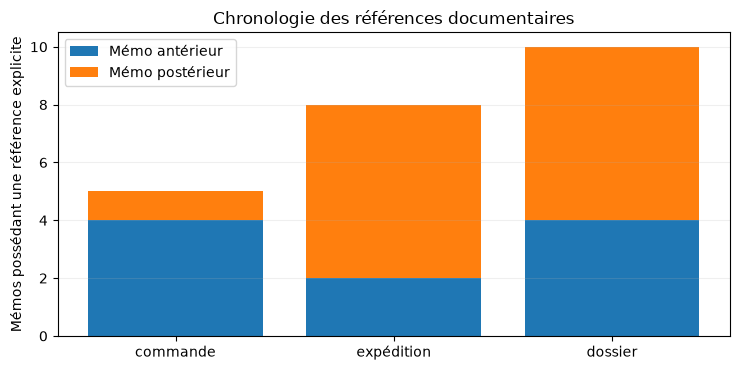

In [38]:
# Étape 8 / contrôle 2 — clés documentaires, jours calendaires et cohérence de statuts.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

memos_8 = pd.read_csv(
    root / "data/public_records/institutional_memos.csv", dtype=str, keep_default_na=False
)
evenements_reg_8 = pd.read_csv(
    root / "data/public_records/regulatory_case_events.csv", dtype=str, keep_default_na=False
)
evenements_acc_8 = pd.read_csv(
    root / "data/public_records/site_access_case_events.csv", dtype=str, keep_default_na=False
)
commandes_8 = pd.read_csv(
    root / "data/processed/logistics/purchase_order_lines.csv", dtype=str, keep_default_na=False
)
expeditions_8 = pd.read_csv(
    root / "data/processed/logistics/shipments.csv", dtype=str, keep_default_na=False
)

# Toutes les dates sont normalisées seulement en mémoire et comparées au niveau du JOUR.
def calendrier(series):
    return pd.to_datetime(series, format="mixed", errors="raise").dt.normalize()

memos_8["jour_memo"] = calendrier(memos_8["document_date"])
commandes_8["jour_commande"] = calendrier(commandes_8["order_date_normalized"])
expeditions_8["jour_depart"] = calendrier(expeditions_8["dispatch_time_normalized"])

# Traiter les événements par dossier et NON comme des documents indépendants.
def construire_dossiers(table, champ_dossier, champ_evenement, provenance):
    n_doublons_identiques = int(table.duplicated().sum())
    uniques = table.drop_duplicates().copy()  # UNIQUEMENT en mémoire
    uniques["instant_evenement"] = pd.to_datetime(
        uniques["event_time"], format="mixed", errors="raise"
    )
    uniques = uniques.sort_values(
        [champ_dossier, "instant_evenement", champ_evenement]
    ).copy()
    uniques["statut_precedent_observe"] = uniques.groupby(champ_dossier)["new_status"].shift(1)
    transitions = uniques.loc[uniques["statut_precedent_observe"].notna()].copy()
    transitions["statuts_enchaines"] = transitions["previous_status"].eq(
        transitions["statut_precedent_observe"]
    )
    premier = uniques.groupby(champ_dossier)["instant_evenement"].min()
    dernier = uniques.groupby(champ_dossier).tail(1).set_index(champ_dossier)
    dossiers = pd.DataFrame({
        "numero_dossier": premier.index,
        "premier_evenement": premier.dt.normalize().values,
        "dernier_evenement": dernier.loc[premier.index, "instant_evenement"].dt.normalize().values,
        "dernier_statut": dernier.loc[premier.index, "new_status"].values,
        "nombre_evenements_uniques": uniques.groupby(champ_dossier).size().reindex(premier.index).values,
        "provenance_dossier": provenance,
    })
    resume = {
        "source": provenance,
        "lignes_sources": len(table),
        "lignes_doublons_exacts": n_doublons_identiques,
        "evenements_uniques": len(uniques),
        "dossiers_distincts": len(dossiers),
        "transitions_comparables": len(transitions),
        "transitions_coherentes": int(transitions["statuts_enchaines"].sum()),
        "dossiers_statut_final_closed": int(dossiers["dernier_statut"].eq("closed").sum()),
    }
    return dossiers, uniques, resume

reg_dossiers_8, reg_uniques_8, controle_reg_8 = construire_dossiers(
    evenements_reg_8, "case_number", "regulatory_event_id", "REG / réglementaire"
)
acc_dossiers_8, acc_uniques_8, controle_acc_8 = construire_dossiers(
    evenements_acc_8, "access_case_number", "access_event_id", "ACC / accès site"
)
dossiers_8 = pd.concat([reg_dossiers_8, acc_dossiers_8], ignore_index=True)
print("Audit des historiques des dossiers (doublons exacts exclus uniquement en mémoire) :")
display(pd.DataFrame([controle_reg_8, controle_acc_8]))

correspondances_8 = [
    ("commande", "related_purchase_order", commandes_8[[
        "purchase_order_number", "jour_commande", "order_status"
    ]].rename(columns={"purchase_order_number": "reference"}), "jour_commande"),
    ("expédition", "related_shipment_number", expeditions_8[[
        "shipment_number", "jour_depart", "shipment_status_normalized"
    ]].rename(columns={"shipment_number": "reference"}), "jour_depart"),
    ("dossier", "related_case_number", dossiers_8.rename(
        columns={"numero_dossier": "reference"}
    ), "premier_evenement"),
]
resumes_memos_8 = []
liens_memos_8 = {}
for type_lien, champ_reference, table_reference, colonne_jour in correspondances_8:
    cites = memos_8.loc[memos_8[champ_reference].ne("")].copy()
    cites = cites.merge(
        table_reference, left_on=champ_reference, right_on="reference",
        how="left", validate="many_to_one", indicator=True,
    )
    cites["reference_trouvee"] = cites["_merge"].eq("both")
    cites["avant_reference"] = (
        cites["reference_trouvee"] & cites["jour_memo"].lt(cites[colonne_jour])
    )
    cites["meme_jour_reference"] = (
        cites["reference_trouvee"] & cites["jour_memo"].eq(cites[colonne_jour])
    )
    cites["apres_reference"] = (
        cites["reference_trouvee"] & cites["jour_memo"].gt(cites[colonne_jour])
    )
    liens_memos_8[type_lien] = cites
    resumes_memos_8.append({
        "type_reference": type_lien,
        "memos_avec_reference": len(cites),
        "references_exactes_trouvees": int(cites["reference_trouvee"].sum()),
        "memos_avant_date_reference": int(cites["avant_reference"].sum()),
        "memos_le_meme_jour": int(cites["meme_jour_reference"].sum()),
        "memos_apres_date_reference": int(cites["apres_reference"].sum()),
    })
print("Références contenues dans les 30 mémos — comparaison au jour calendaire :")
bilan_references_memos_8 = pd.DataFrame(resumes_memos_8)
display(bilan_references_memos_8)

print("Mémos qui citent une commande postérieure :")
display(liens_memos_8["commande"].loc[
    liens_memos_8["commande"]["avant_reference"],
    ["document_id", "document_date", "related_purchase_order", "jour_commande"]
])
print("Mémos qui citent une expédition postérieure :")
display(liens_memos_8["expédition"].loc[
    liens_memos_8["expédition"]["avant_reference"],
    ["document_id", "document_date", "related_shipment_number", "jour_depart"]
])
print("Mémos qui citent un dossier ouvert ultérieurement :")
display(liens_memos_8["dossier"].loc[
    liens_memos_8["dossier"]["avant_reference"],
    ["document_id", "document_date", "related_case_number",
     "provenance_dossier", "premier_evenement", "dernier_evenement", "dernier_statut"]
])

nb_liens_par_memo_8 = memos_8[[
    "related_purchase_order", "related_shipment_number", "related_case_number"
]].ne("").sum(axis=1)

# Visuel comparant les ANTÉRIORITÉS documentaires — aucun jugement de conformité.
fig, ax = plt.subplots(figsize=(7.5, 3.8))
indices = np.arange(len(bilan_references_memos_8))
ax.bar(indices, bilan_references_memos_8["memos_avant_date_reference"], label="Mémo antérieur")
ax.bar(
    indices, bilan_references_memos_8["memos_apres_date_reference"],
    bottom=bilan_references_memos_8["memos_avant_date_reference"],
    label="Mémo postérieur"
)
ax.set_xticks(indices, bilan_references_memos_8["type_reference"])
ax.set_ylabel("Mémos possédant une référence explicite")
ax.set_title("Chronologie des références documentaires")
ax.grid(axis="y", alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()


### Étape 8 — Liens entre mémos et dossiers

Sur **30 mémos**, **23** contiennent une référence explicite : **5 commandes**, **8 expéditions** et **10 dossiers** (`REG` ou `ACC`). Les 23 identifiants existent dans les fichiers associés.

Pourtant, certaines dates posent question : **4 mémos** sont antérieurs à la commande citée, **2** au départ de l'expédition et **4** à l'ouverture du dossier. Une note peut préparer une opération, mais elle ne peut pas prouver qu'une vérification a été réalisée plus tard.

Les fichiers contiennent **40 dossiers réglementaires** et **60 dossiers d'accès**. Après retrait **en mémoire** d'un doublon exact dans chaque historique, les **192 transitions réglementaires** et les **352 transitions d'accès** contrôlées sont cohérentes. Tous les dossiers finissent à `closed`, ce qui ne garantit pas que leur conclusion était favorable.

### Étape 8 — Décisions documentées : ne pas confondre `closed`, action, suivi et refus

**Objectif :** après le contrôle des clés et des transitions de statuts, déterminer **une conclusion descriptive par dossier** sur les **40 dossiers réglementaires `REG`** et les **60 dossiers d'accès `ACC`**, puis confronter **les dix mémos possédant `related_case_number`** à ces historiques. Nous utilisons uniquement les **statuts et les mentions `outcome` inscrits dans les événements**, pas une évaluation juridique ni un jugement sur les acteurs.

- **Dossiers `REG` :** le dernier statut est `closed` pour tous, mais l'historique peut contenir `action_required` (**demande d'action**), `monitoring` (**recommandation de suivi**) ou `referred` (**transmission pour examen**). L'absence de ces trois statuts signifie seulement **« aucune de ces suites inscrite dans les événements »**, et non « aucune irrégularité réelle ». Le texte de l'`outcome` distingue notamment *corrective action requested* et *temporary restriction issued*, sans transformer toutes les demandes en sanctions définitives. Le dernier `outcome` (« corrective action accepted », « action recorded », etc.) reste conservé séparément.
- **Dossiers `ACC` :** distinguer `authorized` des refus finaux `denied`. L'activité `authorization_denied` apparaît aussi dans **trois dossiers** dont le statut enregistré est `returned`, puis `resubmitted` et finalement `authorized` : **il ne faut pas compter ces trois retours comme des refus définitifs supplémentaires**. Un accès autorisé dans le corpus ne prouve pas l'exécution physique de travaux conformes en tous points.
- **Mémos :** joindre `related_case_number` à **une ligne par dossier** selon son préfixe. Comparer le **jour du mémo** à la date d'ouverture/fermeture du dossier : un mémo daté **avant l'ouverture** ne peut pas servir de confirmation rétrospective de sa conclusion ultérieure. Le type ou titre d'un mémo (`shipment_report`, `procurement_note`, etc.) n'est **pas une clé** vers une commande/expédition lorsqu'aucun identifiant correspondant n'y figure. Une référence `REG` peut indirectement pointer vers une expédition via `related_shipment_number` du dossier, mais cette **chaîne à deux sauts** n'est pas une preuve que le mémo décrit effectivement cette expédition.

Les lignes d'événements exactement dupliquées sont éliminées **uniquement en mémoire**. Les dossiers `ACC` citent des codes de site externes, **distincts des identifiants `FCL-...` des établissements ERP** : aucun rapprochement géographique ou physique n'est supposé sans table de correspondance. Tous les fichiers sont synthétiques au sein du même corpus.

Conclusion descriptive par dossier réglementaire (un dossier = une ligne) :

,etape_decision,dossiers
0,aucune de ces suites inscrite,25
1,action_required,7
2,monitoring,4
3,referred,4


Enregistrements d'événements action_required, avec libellé de l'action :
Conclusion descriptive par dossier d'accès (un dossier = une ligne) :


,etape_decision,dossiers
0,authorized,54
1,denied,6


Correspondance de la conclusion ENREGISTRÉE et des mémos qui citent exactement le dossier :

,document_id,document_date,document_type,related_case_number,famille,ouverture,cloture,position_chronologique,decision_observee,dernier_outcome,reference_expedition_du_dossier
2,MEM-510021,2023-04-10,procurement_note,ACC-2018-0024,ACC,2018-04-10,2018-04-27,après clôture,authorized,case closed,
0,MEM-510030,2024-03-02,internal_memorandum,ACC-2019-0005,ACC,2019-08-12,2019-09-15,après clôture,authorized,case closed,
6,MEM-510067,2021-06-26,inventory_explanation,ACC-2020-0008,ACC,2020-05-11,2020-06-14,après clôture,authorized,case closed,
8,MEM-510013,2020-07-07,security_instruction,ACC-2023-0028,ACC,2023-04-13,2023-04-30,avant ouverture,authorized,case closed,
4,MEM-510022,2022-05-18,shipment_report,ACC-2023-0047,ACC,2023-02-16,2023-02-28,avant ouverture,denied,case closed,
3,MEM-510061,2018-09-17,procurement_note,REG-2022-0022,REG,2022-10-13,2022-10-31,avant ouverture,aucune de ces suites inscrite,case closed without further action,SHP-2016-00012
9,MEM-510065,2023-12-14,meeting_record,REG-2022-0022,REG,2022-10-13,2022-10-31,après clôture,aucune de ces suites inscrite,case closed without further action,SHP-2016-00012
5,MEM-510047,2025-10-25,shipment_report,REG-2024-0009,REG,2024-05-31,2024-06-19,après clôture,referred,case closed after review,SHP-2024-00011
1,MEM-510080,2019-08-09,internal_memorandum,REG-2024-0036,REG,2024-06-13,2024-07-01,avant ouverture,aucune de ces suites inscrite,case closed without further action,
7,MEM-510090,2024-11-06,inventory_explanation,REG-2024-0036,REG,2024-06-13,2024-07-01,après clôture,aucune de ces suites inscrite,case closed without further action,


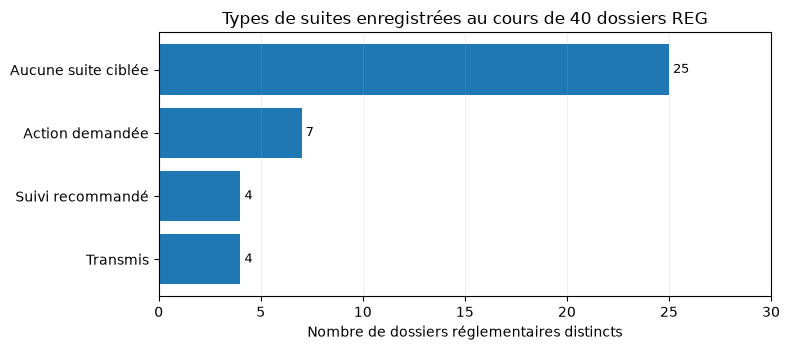

In [39]:
# Étape 8 / décisions documentées et confrontation prudente aux mémos de dossier.
import pandas as pd
import matplotlib.pyplot as plt

reg_decisions = pd.read_csv(
    root / "data/public_records/regulatory_case_events.csv", dtype=str, keep_default_na=False
).drop_duplicates().copy()
acc_decisions = pd.read_csv(
    root / "data/public_records/site_access_case_events.csv", dtype=str, keep_default_na=False
).drop_duplicates().copy()
memos_decisions = pd.read_csv(
    root / "data/public_records/institutional_memos.csv", dtype=str, keep_default_na=False
)

for table in [reg_decisions, acc_decisions]:
    table["instant"] = pd.to_datetime(table["event_time"], format="mixed", errors="raise")
reg_decisions = reg_decisions.sort_values(["case_number", "instant", "regulatory_event_id"])
acc_decisions = acc_decisions.sort_values(["access_case_number", "instant", "access_event_id"])

# Un dossier = une observation, quels que soient le nombre et l'ordre de ses événements.
def synthese_dossiers_evenements(table, casecol, family, idcol):
    resultats = []
    for numero, historique in table.groupby(casecol, sort=True):
        statuts = set(historique["new_status"])
        dernier = historique.iloc[-1]
        resultat = {
            "numero_dossier": numero,
            "famille": family,
            "categorie_source": historique["case_category"].iloc[0] if family == "REG" else "accès à un site",
            "ouverture": historique["instant"].iloc[0].normalize(),
            "cloture": dernier["instant"].normalize(),
            "dernier_statut": dernier["new_status"],
            "dernier_outcome": dernier["outcome"],
            "nombre_evenements_uniques": len(historique),
            "has_action_required": "action_required" in statuts,
            "has_monitoring": "monitoring" in statuts,
            "has_referred": "referred" in statuts,
            "has_authorized": "authorized" in statuts,
            "has_denied": "denied" in statuts,
            "has_returned": "returned" in statuts,
            "has_resubmitted": "resubmitted" in statuts,
        }
        if family == "REG":
            # Les trois types de suite sont exclusifs dans le corpus testé.
            if resultat["has_action_required"]:
                resultat["decision_observee"] = "action_required"
            elif resultat["has_monitoring"]:
                resultat["decision_observee"] = "monitoring"
            elif resultat["has_referred"]:
                resultat["decision_observee"] = "referred"
            else:
                resultat["decision_observee"] = "aucune de ces suites inscrite"
            refs = set(historique["related_shipment_number"]) - {""}
            resultat["reference_expedition_du_dossier"] = next(iter(refs), "")
        else:
            resultat["decision_observee"] = (
                "authorized" if resultat["has_authorized"] else "denied"
            )
            resultat["reference_expedition_du_dossier"] = ""  # aucune clé SHP dans les dossiers ACC
        resultats.append(resultat)
    return pd.DataFrame(resultats)

bilan_reg_decisions = synthese_dossiers_evenements(
    reg_decisions, "case_number", "REG", "regulatory_event_id"
)
bilan_acc_decisions = synthese_dossiers_evenements(
    acc_decisions, "access_case_number", "ACC", "access_event_id"
)
print("Conclusion descriptive par dossier réglementaire (un dossier = une ligne) :")
display(bilan_reg_decisions["decision_observee"].value_counts().rename_axis(
    "etape_decision"
).reset_index(name="dossiers"))
print("Enregistrements d'événements action_required, avec libellé de l'action :")

print("Conclusion descriptive par dossier d'accès (un dossier = une ligne) :")
display(bilan_acc_decisions["decision_observee"].value_counts().rename_axis(
    "etape_decision"
).reset_index(name="dossiers"))

# Rapprocher strictement les mémos par numéro de dossier, jamais par similarité de sujet.
corpus_dossiers_decisions = pd.concat(
    [bilan_reg_decisions, bilan_acc_decisions], ignore_index=True
)
memos_de_dossier = memos_decisions.loc[
    memos_decisions["related_case_number"].ne("")
].copy()
memos_de_dossier["jour_memo"] = pd.to_datetime(
    memos_de_dossier["document_date"], format="mixed", errors="raise"
).dt.normalize()
memos_de_dossier = memos_de_dossier.merge(
    corpus_dossiers_decisions,
    left_on="related_case_number", right_on="numero_dossier",
    how="left", validate="many_to_one", indicator=True,
)

memos_de_dossier["position_chronologique"] = "pendant la procédure"
memos_de_dossier.loc[
    memos_de_dossier["jour_memo"].lt(memos_de_dossier["ouverture"]),
    "position_chronologique"
] = "avant ouverture"
memos_de_dossier.loc[
    memos_de_dossier["jour_memo"].gt(memos_de_dossier["cloture"]),
    "position_chronologique"
] = "après clôture"

print("Correspondance de la conclusion ENREGISTRÉE et des mémos qui citent exactement le dossier :")
display(memos_de_dossier[[
    "document_id", "document_date", "document_type", "related_case_number",
    "famille", "ouverture", "cloture", "position_chronologique",
    "decision_observee", "dernier_outcome", "reference_expedition_du_dossier"
]].sort_values("related_case_number"))

# Visuel descriptif : une barre par type de suite ou décision, pas de score de conformité.
fig, ax = plt.subplots(figsize=(8, 3.6))
ordre_reg = ["aucune de ces suites inscrite", "action_required", "monitoring", "referred"]
valeurs_reg = bilan_reg_decisions["decision_observee"].value_counts().reindex(
    ordre_reg, fill_value=0
)
ax.barh(["Aucune suite ciblée", "Action demandée", "Suivi recommandé", "Transmis"],
        valeurs_reg.to_numpy())
for i, valeur in enumerate(valeurs_reg.to_numpy()):
    ax.text(valeur + 0.2, i, str(valeur), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, valeurs_reg.max() * 1.2)
ax.set_xlabel("Nombre de dossiers réglementaires distincts")
ax.set_title("Types de suites enregistrées au cours de 40 dossiers REG")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


### Méthode du CM4 — Premier graphe de processus (*Directly-Follows Graph*)

Les événements réglementaires sont organisés par **numéro de dossier et date**. Pour chaque dossier, on relie chaque activité à **l'activité suivante**. On obtient un **graphe de succession des activités**, comme présenté dans le cours sur le Process Mining. Les libellés sont mis en minuscules pour regrouper les variantes de casse, et les lignes dupliquées sont retirées en mémoire.

On affiche les transitions les plus fréquentes pour garder un graphe lisible. Il montre **l'ordre des événements enregistrés**, pas un processus idéal, ni une preuve que chaque action a été réalisée dans la réalité. Ce n'est pas encore un Heuristic Miner ni un test de conformité.

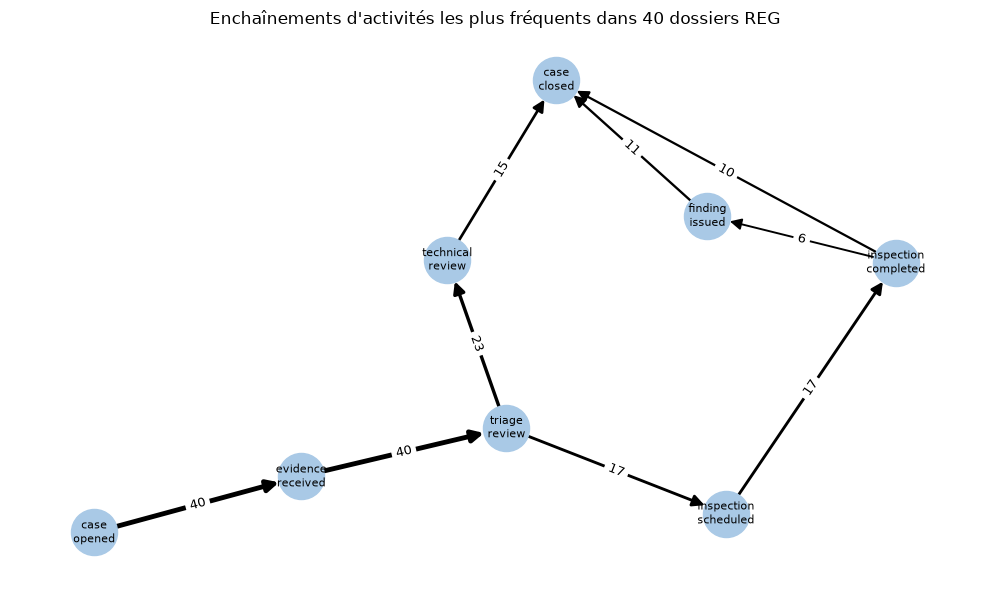

13 types de transitions observés, sur 192 transitions au total.


In [40]:
# Première fouille de processus : événements qui se suivent dans un même dossier.
evenements_processus = reg_decisions.sort_values(
    ["case_number", "instant", "regulatory_event_id"]
).copy()
evenements_processus["activite"] = evenements_processus["activity"].str.strip().str.lower()
evenements_processus["activite_suivante"] = (
    evenements_processus.groupby("case_number")["activite"].shift(-1)
)
transitions = (evenements_processus.dropna(subset=["activite_suivante"])
               .groupby(["activite", "activite_suivante"])
               .size().reset_index(name="frequence")
               .sort_values("frequence", ascending=False))

# Seuls les liens les plus fréquents sont affichés pour éviter un graphe illisible.
graphe_processus = nx.DiGraph()
for _, ligne in transitions.head(9).iterrows():
    graphe_processus.add_edge(ligne["activite"], ligne["activite_suivante"],
                             weight=int(ligne["frequence"]))
positions = nx.spring_layout(graphe_processus, seed=15, k=1.7)
fig, ax = plt.subplots(figsize=(10, 6))
nx.draw_networkx_nodes(graphe_processus, positions, node_size=1100, node_color="#a9c9e6", ax=ax)
nx.draw_networkx_labels(graphe_processus, positions,
                        labels={x: x.replace("_", "\n") for x in graphe_processus.nodes},
                        font_size=8, ax=ax)
nx.draw_networkx_edges(graphe_processus, positions, arrows=True,
                       node_size=1100, arrowsize=17, arrowstyle="-|>",
                       width=[1 + d["weight"] / 16 for _, _, d in graphe_processus.edges(data=True)],
                       ax=ax)
nx.draw_networkx_edge_labels(
    graphe_processus, positions,
    edge_labels={(u, v): d["weight"] for u, v, d in graphe_processus.edges(data=True)},
    font_size=9, ax=ax)
ax.set_title("Enchaînements d'activités les plus fréquents dans 40 dossiers REG")
ax.axis("off")
plt.tight_layout()
plt.show()

print(f"{len(transitions)} types de transitions observés, sur {len(evenements_processus) - evenements_processus['case_number'].nunique()} transitions au total.")

### Étape 8 — Ce que disent les conclusions des dossiers

Parmi les **40 dossiers réglementaires**, **25** ne présentent aucune des trois suites recherchées, **7** contiennent `action_required`, **4** `monitoring` et **4** `referred`. Dans les sept demandes d'action, on trouve **5 mesures correctives demandées** et **2 restrictions temporaires**.

Sur les **60 dossiers d'accès aux sites**, **54** ont une autorisation et **6** un refus. Trois autorisations ont été obtenues après un retour pour conditions supplémentaires et une nouvelle soumission.

Les **10 mémos qui citent un dossier** correspondent à **8 dossiers distincts**. **Quatre mémos** datent d'avant l'ouverture du dossier cité et **six** d'après sa clôture. Par exemple, `MEM-510022` cite un refus `ACC-2023-0047`, mais date de **2022**, avant l'ouverture du dossier en **2023**.

**Ce qu'on retient :** il faut regarder l'historique et la date, pas seulement le dernier statut `closed`. Et un mémo qui cite un dossier ne prouve pas la réalité d'une opération.

## Compléments — méthodes du cours appliquées à nos données

On a déjà fait le nettoyage, les contrôles de quantité, l'IQR, les graphes et le premier graphe de processus. Il restait quelques méthodes du CM2 et du CM3 à tester. On les applique ici **sur des observations qui ont du sens** : un établissement pour le clustering, une expédition pour les règles d'association. On garde aussi les résultats peu concluants.

### CM2 — Profils des établissements : PCA et clustering

Pour chaque établissement, on compte les commandes passées, les réceptions, les départs et les arrivées d'expéditions, les départs à température contrôlée et les relevés de stock. On standardise ces **six nombres** pour qu'une variable avec de grands effectifs ne domine pas les autres. On teste plusieurs nombres de groupes avec **K-Means**, puis **DBSCAN** avec différentes distances maximales. La **PCA** permet de voir les profils en deux dimensions.

Les groupes correspondent seulement à des **activités enregistrées**, pas à une catégorie de risque. La silhouette sert à comparer les partitions, pas à découvrir la « vraie » nature des établissements.

PCA : les deux premières dimensions expliquent 91.4 % de la variance.


,k,inertie,silhouette
0,2,84.4,0.665
1,3,40.6,0.645
2,4,25.5,0.621
3,5,18.4,0.560


Partition K-Means retenue pour l'affichage : 2 groupes


,etablissements,commandes_medianes,departs_medians,releves_stock_medians
groupe_kmeans,,,,
0,25,9.0,7.0,0.0
1,5,65.0,37.0,100.0


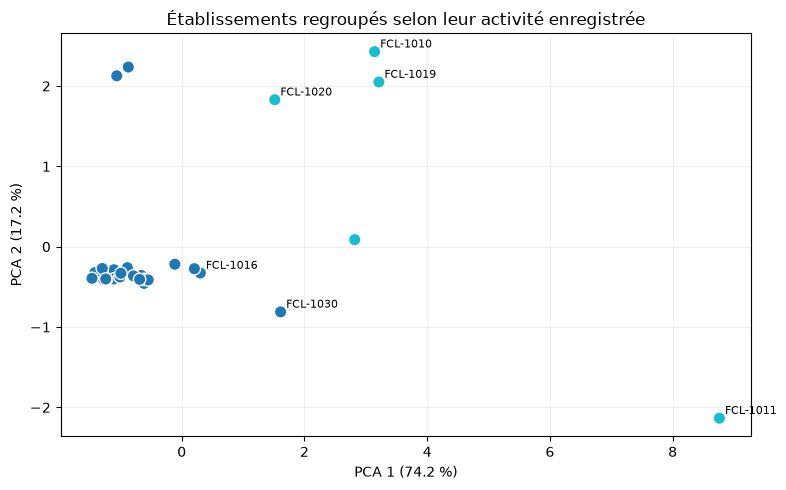

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

b = root / "data/processed/logistics"
fac_cm2 = pd.read_csv(b / "erp_facilities.csv")
po_cm2 = pd.read_csv(b / "purchase_order_lines.csv")
gr_cm2 = pd.read_csv(b / "goods_receipts.csv")
sh_cm2 = pd.read_csv(b / "shipments.csv")
st_cm2 = pd.read_csv(b / "inventory_month_end.csv")

sites_cm2 = fac_cm2["facility_code"].sort_values()
profils_cm2 = pd.DataFrame(index=sites_cm2)
for nom, donnees, cle in [
    ("commandes", po_cm2, "ordering_facility_code"),
    ("receptions", gr_cm2, "receiving_facility_code"),
    ("departs", sh_cm2, "origin_facility_code"),
    ("arrivees", sh_cm2, "destination_facility_code"),
    ("releves_stock", st_cm2, "facility_code"),
]:
    profils_cm2[nom] = donnees[cle].value_counts().reindex(sites_cm2, fill_value=0)
profils_cm2["departs_froid"] = sh_cm2.loc[
    sh_cm2["temperature_control_class_normalized"].isin(["2-8c", "frozen"]),
    "origin_facility_code"
].value_counts().reindex(sites_cm2, fill_value=0)

X_brut = profils_cm2.to_numpy(dtype=float)
X_cm2 = (X_brut - X_brut.mean(axis=0)) / np.where(X_brut.std(axis=0) > 0,
                                                    X_brut.std(axis=0), 1)
U_cm2, S_cm2, Vt_cm2 = np.linalg.svd(X_cm2, full_matrices=False)
pca_cm2 = U_cm2[:, :2] * S_cm2[:2]
variance_cm2 = 100 * (S_cm2 ** 2) / np.sum(S_cm2 ** 2)

# K-Means : plusieurs initialisations fixes pour comparer k=2...5.
def kmeans_simple(X, k, seed=24, essais=10):
    rng = np.random.default_rng(seed)
    meilleur = None
    for _ in range(essais):
        centres = X[rng.choice(len(X), size=k, replace=False)].copy()
        for iteration in range(100):
            distances = np.linalg.norm(X[:, None] - centres[None, :], axis=2)
            groupes = np.argmin(distances, axis=1)
            nouveaux = centres.copy()
            for g in range(k):
                if (groupes == g).any():
                    nouveaux[g] = X[groupes == g].mean(axis=0)
            if np.allclose(centres, nouveaux):
                break
            centres = nouveaux
        groupes = np.argmin(np.linalg.norm(X[:, None] - centres[None, :], axis=2), axis=1)
        inertie = float(np.sum((X - centres[groupes]) ** 2))
        if meilleur is None or inertie < meilleur[0]:
            meilleur = (inertie, groupes.copy())
    return meilleur

def silhouette_simple(X, groupes):
    distances = np.linalg.norm(X[:, None] - X[None, :], axis=2)
    valeurs = []
    for i in range(len(X)):
        meme = (groupes == groupes[i])
        if meme.sum() == 1:
            valeurs.append(0.0)
            continue
        a = distances[i, meme].sum() / (meme.sum() - 1)
        b = min(distances[i, groupes == g].mean() for g in np.unique(groupes) if g != groupes[i])
        valeurs.append((b - a) / max(a, b) if max(a, b) else 0)
    return float(np.mean(valeurs))

tests_kmeans = []
for k in range(2, 6):
    inertie, groupes = kmeans_simple(X_cm2, k)
    tests_kmeans.append((k, inertie, silhouette_simple(X_cm2, groupes), groupes))
k_choisi, inertie_choisie, silhouette_choisie, groupes_cm2 = max(
    tests_kmeans, key=lambda r: r[2]
)
profils_cm2["groupe_kmeans"] = groupes_cm2
print("PCA : les deux premières dimensions expliquent", round(variance_cm2[:2].sum(), 1), "% de la variance.")
display(pd.DataFrame([{"k": k, "inertie": round(ine, 1),
                       "silhouette": round(sil, 3)} for k, ine, sil, _ in tests_kmeans]))
print("Partition K-Means retenue pour l'affichage :",k_choisi,"groupes")
display(profils_cm2.groupby("groupe_kmeans").agg(
    etablissements=("commandes", "size"),
    commandes_medianes=("commandes", "median"),
    departs_medians=("departs", "median"),
    releves_stock_medians=("releves_stock", "median"),
))

fig, ax = plt.subplots(figsize=(8, 5))
points = ax.scatter(pca_cm2[:, 0], pca_cm2[:, 1], c=groupes_cm2,
                    cmap="tab10", s=80, edgecolors="white")
for idx in np.argsort(profils_cm2["departs"].to_numpy())[-6:]:
    ax.annotate(profils_cm2.index[idx], pca_cm2[idx], xytext=(4, 3),
                textcoords="offset points", fontsize=8)
ax.set_xlabel(f"PCA 1 ({variance_cm2[0]:.1f} %)")
ax.set_ylabel(f"PCA 2 ({variance_cm2[1]:.1f} %)")
ax.set_title("Établissements regroupés selon leur activité enregistrée")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Interprétation CM2.** Deux groupes obtiennent la meilleure silhouette parmi les quatre choix testés (**0,665** pour k=2). Les deux axes PCA expliquent **91,4 %** de la variance des six indicateurs. La séparation dépend beaucoup des volumes d'activité et de la disponibilité des relevés de stock : ce sont des profils descriptifs, pas des groupes « normaux/suspects ».

### CM2 — DBSCAN : une autre façon de regrouper les profils

Contrairement à K-Means, **DBSCAN** ne fixe pas le nombre de groupes. On essaye trois rayons autour des établissements dans l'espace des variables standardisées, avec au moins **3 observations proches** pour former un groupe. Un point isolé est du **bruit statistique**, pas une installation suspecte. Les résultats peuvent changer beaucoup selon le rayon choisi.

,eps,groupes,points_isoles
0,0.33,1,12
1,0.70,2,8
2,2.63,2,2


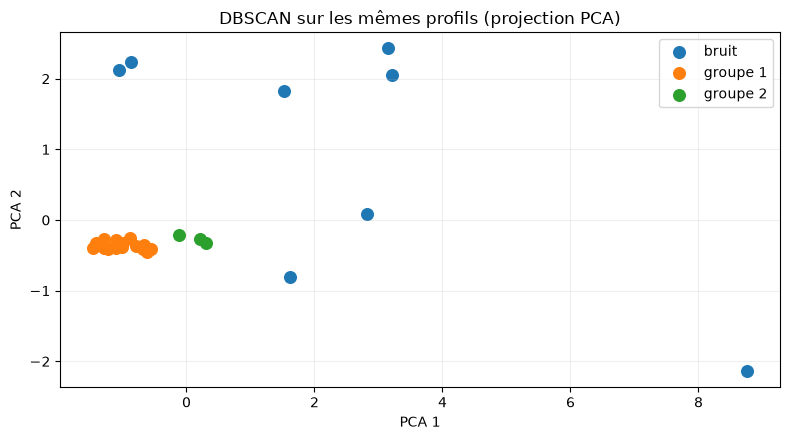

In [42]:
def dbscan_simple(X, eps, min_points=3):
    dist = np.linalg.norm(X[:, None] - X[None, :], axis=2)
    voisins = [set(np.flatnonzero(dist[i] <= eps)) for i in range(len(X))]
    labels = np.full(len(X), -1, dtype=int)
    traites = set()
    groupe = 0
    for i in range(len(X)):
        if i in traites:
            continue
        traites.add(i)
        if len(voisins[i]) < min_points:
            continue
        labels[i] = groupe
        a_explorer = list(voisins[i] - {i})
        while a_explorer:
            j = a_explorer.pop()
            if j not in traites:
                traites.add(j)
                if len(voisins[j]) >= min_points:
                    a_explorer.extend(voisins[j] - traites)
            if labels[j] == -1:
                labels[j] = groupe
        groupe += 1
    return labels

distances_cm2 = np.linalg.norm(X_cm2[:, None] - X_cm2[None, :], axis=2)
# Distance au deuxième voisin distinct, le point lui-même étant inclus dans min_points=3.
dist_3 = np.sort(distances_cm2, axis=1)[:, 2]
rayons = np.unique(np.round(np.quantile(dist_3, [0.5, 0.7, 0.9]), 2))
tests_dbscan = []
for eps in rayons:
    labels = dbscan_simple(X_cm2, eps, min_points=3)
    tests_dbscan.append({"eps": eps, "groupes": len(set(labels) - {-1}),
                         "points_isoles": int((labels == -1).sum())})
display(pd.DataFrame(tests_dbscan))
labels_dbscan = dbscan_simple(X_cm2, rayons[len(rayons) // 2])
fig, ax = plt.subplots(figsize=(8, 4.5))
for g in sorted(set(labels_dbscan)):
    selection = labels_dbscan == g
    ax.scatter(pca_cm2[selection, 0], pca_cm2[selection, 1], s=70,
               label="bruit" if g == -1 else f"groupe {g + 1}")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_title("DBSCAN sur les mêmes profils (projection PCA)")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Interprétation DBSCAN.** Avec les trois rayons testés, le nombre de sites isolés varie de **12 à 2**. La méthode est donc sensible au paramètre `eps`. Il vaut mieux montrer cette sensibilité que choisir un rayon en prétendant découvrir des catégories naturelles.

### CM3 — Détection locale d'atypiques avec LOF

On teste aussi **LOF** sur les 30 profils d'établissements. Le principe est de regarder si un site est dans une zone moins dense que ses cinq voisins les plus proches. Un score au-dessus de 1 indique un profil plus isolé localement ; ce n'est **pas une preuve d'anomalie de gestion**. Avec si peu de sites, le classement doit rester exploratoire.

,etablissement,score_LOF
26,FCL-1027,6.37
23,FCL-1024,5.01
29,FCL-1030,3.30
10,FCL-1011,2.48
6,FCL-1007,2.17
15,FCL-1016,2.00
28,FCL-1029,1.98
14,FCL-1015,1.80


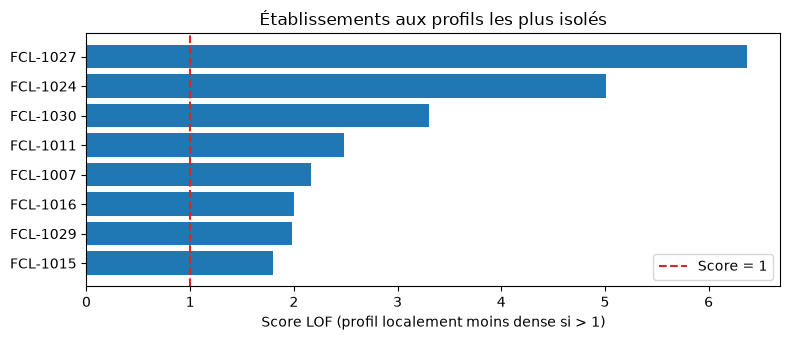

In [43]:
# LOF basé sur les 5 voisins les plus proches, sur les profils déjà standardisés.
k_lof = 5
D_lof = distances_cm2.copy()
np.fill_diagonal(D_lof, np.inf)
voisins_lof = np.argsort(D_lof, axis=1)[:, :k_lof]
distance_k = np.sort(D_lof, axis=1)[:, k_lof - 1]
reach = np.array([
    [max(D_lof[i, j], distance_k[j]) for j in voisins_lof[i]]
    for i in range(len(D_lof))
])
densite_locale = 1 / np.maximum(reach.mean(axis=1), 1e-12)
lof = np.array([densite_locale[voisins_lof[i]].mean() / densite_locale[i]
                for i in range(len(D_lof))])
resultats_lof = pd.DataFrame({"etablissement": profils_cm2.index,
                             "score_LOF": lof}).sort_values("score_LOF", ascending=False)
display(resultats_lof.head(8).round(2))
fig, ax = plt.subplots(figsize=(8, 3.5))
top_lof = resultats_lof.head(8).iloc[::-1]
ax.barh(top_lof["etablissement"], top_lof["score_LOF"])
ax.axvline(1, color="tab:red", linestyle="--", label="Score = 1")
ax.set_xlabel("Score LOF (profil localement moins dense si > 1)")
ax.set_title("Établissements aux profils les plus isolés")
ax.legend()
plt.tight_layout()
plt.show()

**Interprétation LOF.** Les profils les plus isolés sont `FCL-1027` (score **6,37**), `FCL-1024` (**5,01**) et `FCL-1030` (**3,30**). Cela signale seulement des combinaisons de volumes d'activité moins communes parmi **30 établissements**. Un score LOF ne prouve pas une anomalie de stock ou de transport.

### CM3 — Motifs fréquents et règles d'association (Apriori)

On considère **une expédition = une transaction** contenant sa catégorie de marchandise, sa classe de température, son statut, son autorisation, son motif déclaré, sa région de départ et celle d'arrivée. Chaque item est préfixé par son champ pour ne pas confondre des valeurs semblables. On teste **Apriori** sur les ensembles de 1 à 3 items, avec **8 % de support minimum**, puis les règles ayant au moins **60 % de confiance** et un **lift supérieur à 1,2**.

Attention : certaines règles sont presque une conséquence du codage des données, par exemple « échantillon biologique ⇒ température 2–8 °C ». Elles décrivent **des associations dans ce fichier**, pas des relations causales ou des risques. On ne prétend pas avoir des paniers contenant plusieurs produits : chaque ligne est une expédition.

Itemsets fréquents : 130 — règles retenues : 12
Sensibilité au support minimal : {0.05: 239, 0.08: 130, 0.12: 72}


,si,alors,support_%,confiance_%,lift
2,item=biological_sample,temp=2-8c,11.56,100.00,4.37
3,item=medical_consumables,temp=2-8c,11.33,100.00,4.37
10,item=biological_sample + statut=delivered,temp=2-8c,11.33,100.00,4.37
11,item=medical_consumables + statut=delivered,temp=2-8c,10.22,100.00,4.37
5,auth=ordinary + destination=Eastern Avelora Ag...,origine=Valenne Central District,12.00,65.85,1.50
1,destination=Eastern Avelora Agricultural Cluster,origine=Valenne Central District,19.33,63.97,1.46
9,destination=Eastern Avelora Agricultural Clust...,origine=Valenne Central District,13.56,62.89,1.44
0,item=monitoring_equipment,auth=ordinary,8.44,90.48,1.43
7,item=monitoring_equipment + temp=ambient,auth=ordinary,8.44,90.48,1.43
8,destination=Eastern Avelora Agricultural Clust...,origine=Valenne Central District,15.78,61.21,1.40


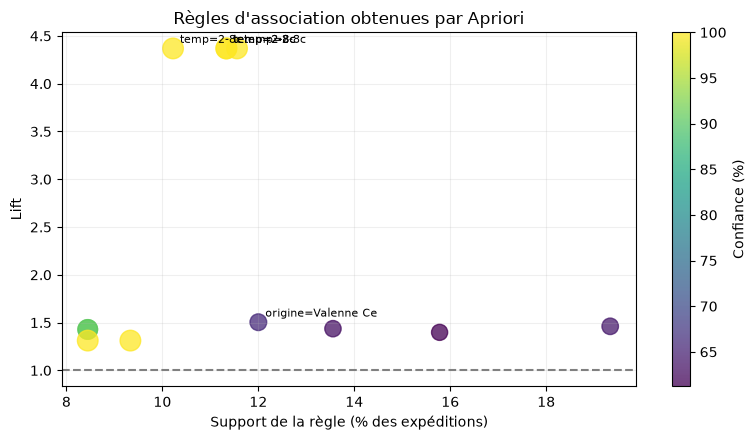

In [44]:
from itertools import combinations
from collections import Counter

s_asso = pd.read_csv(b / "shipments.csv")
f_asso = pd.read_csv(b / "erp_facilities.csv")
regions = f_asso.set_index("facility_code")["region"]
s_asso["region_depart"] = s_asso["origin_facility_code"].map(regions)
s_asso["region_arrivee"] = s_asso["destination_facility_code"].map(regions)
s_asso["motif_nettoye"] = (s_asso["declared_purpose"].str.lower()
                            .str.strip().str.replace(r"\s+", " ", regex=True))
champs_asso = {"item": "item_category", "temp": "temperature_control_class_normalized",
               "auth": "authorization_class", "statut": "shipment_status_normalized",
               "motif": "motif_nettoye", "origine": "region_depart",
               "destination": "region_arrivee"}
transactions = [
    {f"{prefix}={str(ligne[colonne])}" for prefix, colonne in champs_asso.items()}
    for _, ligne in s_asso.iterrows()
]

def apriori_simple(transactions, support_min=0.08, taille_max=3):
    n = len(transactions)
    seuil = int(np.ceil(n * support_min))
    freqs = {frozenset([item]): nb for item, nb in Counter(
        item for transaction in transactions for item in transaction).items() if nb >= seuil}
    courants = sorted(freqs)
    for taille in range(2, taille_max + 1):
        items = sorted(set().union(*(set(c) for c in courants))) if courants else []
        suivants = {}
        for candidat in combinations(items, taille):
            ens = frozenset(candidat)
            # Élagage Apriori : tous les sous-ensembles de taille k-1 doivent être fréquents.
            if not all(frozenset(sous) in freqs for sous in combinations(candidat, taille - 1)):
                continue
            if len({s.split("=", 1)[0] for s in candidat}) < taille:
                continue
            compte = sum(ens.issubset(transaction) for transaction in transactions)
            if compte >= seuil:
                suivants[ens] = compte
        freqs.update(suivants)
        courants = sorted(suivants)
    return freqs

freqs_asso = apriori_simple(transactions, support_min=0.08)
regles_asso = []
n_tr = len(transactions)
for itemset, nb in freqs_asso.items():
    if len(itemset) < 2:
        continue
    for consequent in itemset:
        gauche = itemset - {consequent}
        confiance = nb / freqs_asso[gauche]
        support_c = freqs_asso[frozenset([consequent])] / n_tr
        lift = confiance / support_c
        if confiance >= 0.60 and lift > 1.20:
            regles_asso.append({"si": " + ".join(sorted(gauche)), "alors": consequent,
                                "support_%": 100 * nb / n_tr,
                                "confiance_%": 100 * confiance, "lift": lift})
regles_asso = pd.DataFrame(regles_asso,
                             columns=["si", "alors", "support_%", "confiance_%", "lift"])
regles_asso = regles_asso.sort_values(["lift", "support_%"], ascending=False)
print("Itemsets fréquents :", len(freqs_asso), "— règles retenues :", len(regles_asso))
print("Sensibilité au support minimal :", {s: len(apriori_simple(transactions, s))
                                          for s in [0.05, 0.08, 0.12]})
display(regles_asso.head(10).round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
if not regles_asso.empty:
    top_regles = regles_asso.head(20)
    points = ax.scatter(top_regles["support_%"], top_regles["lift"],
                        s=top_regles["confiance_%"] * 2.2,
                        c=top_regles["confiance_%"], cmap="viridis", alpha=0.75)
    fig.colorbar(points, ax=ax, label="Confiance (%)")
    for _, ligne in top_regles.head(5).iterrows():
        ax.annotate(ligne["alors"][:18], (ligne["support_%"], ligne["lift"]),
                    xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.axhline(1, color="grey", linestyle="--")
ax.set_xlabel("Support de la règle (% des expéditions)")
ax.set_ylabel("Lift")
ax.set_title("Règles d'association obtenues par Apriori")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Interprétation Apriori.** Avec un support minimal de **8 %**, on trouve **130 itemsets fréquents** et **12 règles** satisfaisant les critères de confiance et de lift. La règle « échantillon biologique → classe 2–8 °C » atteint **100 % de confiance** et un **lift de 4,37**, mais elle reflète surtout la manière dont les expéditions sont renseignées. Les règles entre régions peuvent aussi refléter le plan d'échantillonnage : on ne déduit ni causalité ni irrégularité.

### CM4 — Louvain et centralités : comparer avec nos communautés précédentes

On avait utilisé l'algorithme glouton pour les communautés. Le cours présente aussi **Louvain** : on le teste sur le **même graphe non dirigé et pondéré des partenaires**, avec une graine fixe. On compare le nombre de communautés et la modularité Q. On calcule également la **force** d'un partenaire (somme des expéditions de ses relations), puis la **betweenness non pondérée** pour repérer les intermédiaires du réseau. Une forte centralité ne prouve pas un rôle illicite.

,méthode,groupes,modularité
0,Glouton,5,0.380
1,Louvain,6,0.377


,partenaire,force,betweenness
17,BP-30078,146,0.168
44,BP-30021,62,0.006
56,BP-30056,55,0.011
15,BP-30046,17,0.024
58,BP-30033,17,0.050
25,BP-30009,15,0.034
42,BP-30017,15,0.035
18,BP-30010,14,0.026


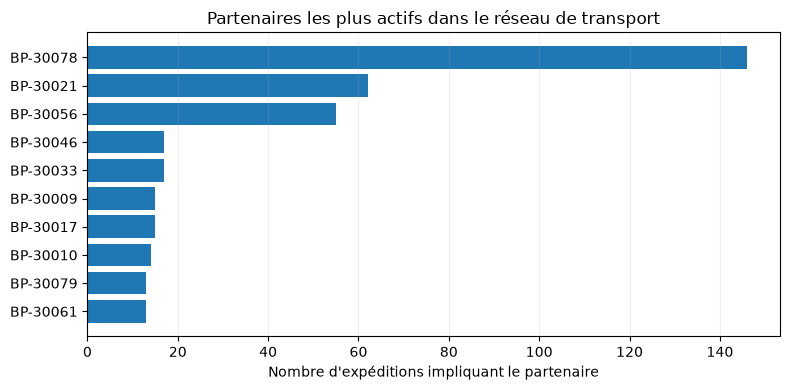

In [45]:
import networkx as nx

reseau_cm4 = nx.Graph()
for (a, b), freq in (sh_cm2.groupby(["sender_partner_code", "receiver_partner_code"])
                     .size().items()):
    if a == b:
        continue
    if reseau_cm4.has_edge(a, b):
        reseau_cm4[a][b]["weight"] += int(freq)
    else:
        reseau_cm4.add_edge(a, b, weight=int(freq))

comm_greedy = list(nx.community.greedy_modularity_communities(reseau_cm4, weight="weight"))
comm_louvain = nx.community.louvain_communities(reseau_cm4, weight="weight", seed=24)
comparaison_communautes = pd.DataFrame([
    {"méthode": "Glouton", "groupes": len(comm_greedy),
     "modularité": nx.community.modularity(reseau_cm4, comm_greedy, weight="weight")},
    {"méthode": "Louvain", "groupes": len(comm_louvain),
     "modularité": nx.community.modularity(reseau_cm4, comm_louvain, weight="weight")},
])
display(comparaison_communautes.round(3))
force_noeuds = dict(reseau_cm4.degree(weight="weight"))
betweenness_cm4 = nx.betweenness_centrality(reseau_cm4, weight=None)
centralites_cm4 = pd.DataFrame({"partenaire": list(reseau_cm4.nodes),
                                "force": [force_noeuds[v] for v in reseau_cm4.nodes],
                                "betweenness": [betweenness_cm4[v] for v in reseau_cm4.nodes]})
display(centralites_cm4.nlargest(8, "force").round(3))
principaux_noeuds = centralites_cm4.nlargest(10, "force").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(principaux_noeuds["partenaire"], principaux_noeuds["force"])
ax.set_xlabel("Nombre d'expéditions impliquant le partenaire")
ax.set_title("Partenaires les plus actifs dans le réseau de transport")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

**Interprétation Graph Mining.** Sur le même graphe pondéré, la méthode gloutonne donne **5 groupes (Q=0,380)** et Louvain **6 (Q=0,377)**. Les partitions sont différentes et leurs modularités proches : le résultat dépend de l'algorithme. `BP-30078` concentre **146 expéditions impliquant cet acteur** (envoi ou réception), mais la centralité seule ne dit pas pourquoi.

### CM4 — Process Mining : variantes et transitions importantes

On a déjà créé un graphe des événements qui se suivent dans les **40 dossiers réglementaires**. Ici, on regarde les **parcours complets les plus fréquents** et on calcule une **dépendance entre deux activités**, comme dans l'idée du *Heuristic Miner* du cours. On n'ajoute pas de transitions entre dossiers différents. Les noms d'activités sont mis en minuscules pour réunir les variantes de saisie.

Cette petite version sert à simplifier la lecture d'un journal d'événements. Elle **ne remplace pas** un outil complet de Process Mining ni un test de conformité à une procédure officielle.

Parcours distincts : 6 sur 40 dossiers.


,parcours,dossiers
0,case_opened → evidence_received → triage_revie...,15
1,case_opened → evidence_received → triage_revie...,10
2,case_opened → evidence_received → triage_revie...,6
3,case_opened → evidence_received → triage_revie...,5
4,case_opened → evidence_received → triage_revie...,3
5,case_opened → evidence_received → triage_revie...,1


Transitions retenues : au moins 5 occurrences et dépendance > 0,6


,transition,occurrences,dependance
0,case_opened → evidence_received,40,0.976
1,evidence_received → triage_review,40,0.976
2,triage_review → technical_review,23,0.958
4,triage_review → inspection_scheduled,17,0.944
5,inspection_scheduled → inspection_completed,17,0.944
3,technical_review → case_closed,15,0.938
8,finding_issued → case_closed,11,0.917
6,inspection_completed → case_closed,10,0.909
9,inspection_completed → finding_issued,6,0.857
7,technical_review → finding_issued,5,0.833


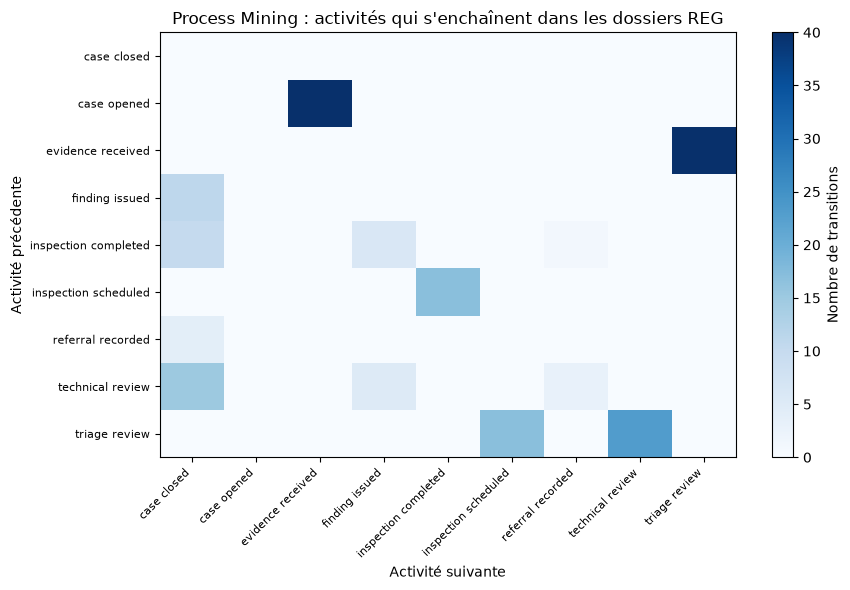

In [46]:
from collections import Counter

log_process = pd.read_csv(root / "data/public_records/regulatory_case_events.csv")
log_process = log_process.drop_duplicates().copy()
log_process["instant"] = pd.to_datetime(log_process["event_time"], format="mixed")
log_process["activite"] = log_process["activity"].str.strip().str.lower()
log_process = log_process.sort_values(["case_number", "instant", "regulatory_event_id"])
parcours = [tuple(t["activite"]) for _, t in log_process.groupby("case_number")]
frequences_parcours = Counter(parcours)
principaux_parcours = pd.DataFrame([
    {"parcours": " → ".join(c), "dossiers": n}
    for c, n in frequences_parcours.most_common(6)
])
print("Parcours distincts :", len(frequences_parcours), "sur", len(parcours), "dossiers.")
display(principaux_parcours)

log_process["suivante"] = log_process.groupby("case_number")["activite"].shift(-1)
transitions_process = Counter(zip(log_process.loc[log_process["suivante"].notna(), "activite"],
                                  log_process.loc[log_process["suivante"].notna(), "suivante"]))
dependances = []
for (a, b), f in transitions_process.items():
    inverse = transitions_process.get((b, a), 0)
    if a != b:
        dependances.append({"transition": f"{a} → {b}", "occurrences": f,
                            "dependance": (f - inverse) / (f + inverse + 1)})
table_dependances = pd.DataFrame(dependances).sort_values(
    ["dependance", "occurrences"], ascending=False)
print("Transitions retenues : au moins 5 occurrences et dépendance > 0,6")
display(table_dependances.query("occurrences >= 5 and dependance > 0.6").head(10).round(3))

# Matrice des activités successives (couples ordonnés).
activites = sorted(set(log_process["activite"]))
matrice_process = pd.DataFrame(0, index=activites, columns=activites)
for (a, b), compte in transitions_process.items():
    matrice_process.loc[a, b] = compte
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(matrice_process, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(activites)), [a.replace("_", " ") for a in activites],
              rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(activites)), [a.replace("_", " ") for a in activites], fontsize=8)
fig.colorbar(im, ax=ax, label="Nombre de transitions")
ax.set_xlabel("Activité suivante")
ax.set_ylabel("Activité précédente")
ax.set_title("Process Mining : activités qui s'enchaînent dans les dossiers REG")
plt.tight_layout()
plt.show()

**Interprétation Process Mining.** Les 40 dossiers réglementaires suivent **6 variantes de parcours**. Les étapes `case_opened → evidence_received` et `evidence_received → triage_review` apparaissent dans **les 40 dossiers**. Une activité fréquemment suivie d'une autre ne prouve pas que cette procédure était obligatoire ni respectée dans le monde réel.

### CM5 — Évolution temporelle des commandes et des expéditions

On regroupe les dates **par mois**, en comptant les lignes enregistrées. Il y a des mois sans opération dans les fichiers : on les représente par **0 événement enregistré**, ce qui n'est pas forcément zéro activité réelle. On calcule **Pearson et Spearman** entre les deux séries mensuelles, puis l'**autocorrélation** des commandes pour plusieurs décalages. Le cours recommande de chercher une tendance et une saisonnalité, mais la répartition artificielle des dates doit rendre prudent.

Corrélation des comptages mensuels : Pearson = 0.968 — Spearman = 0.31
Pearson sans les dix mois les plus chargés : 0.123 (analyse de sensibilité, pas un nouveau jeu de données).


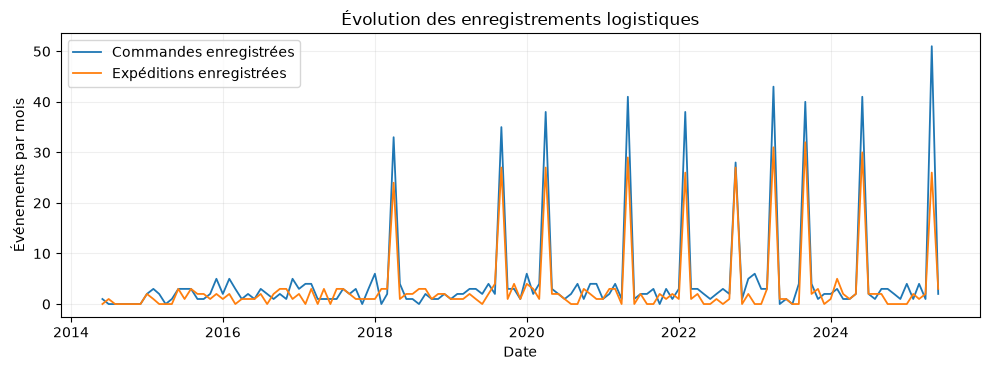

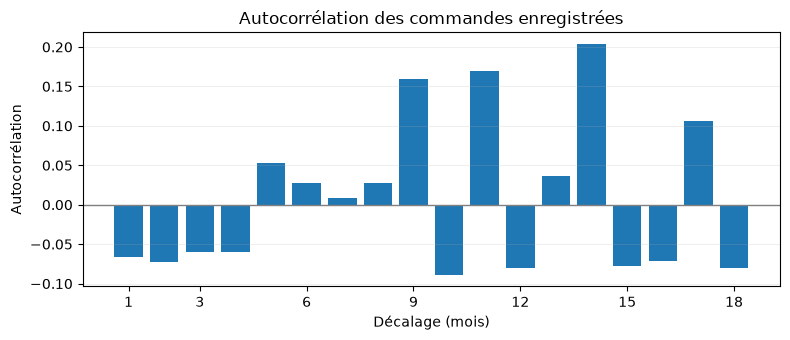

Autocorrélation à 12 mois : -0.08 — aucune saisonnalité ne peut être déduite sans vérifier la couverture temporelle.


In [47]:
orders_t = pd.read_csv(root / "data/processed/logistics/purchase_order_lines.csv")
ship_t = pd.read_csv(root / "data/processed/logistics/shipments.csv")
date_po = pd.to_datetime(orders_t["order_date_normalized"])
date_sh = pd.to_datetime(ship_t["dispatch_time_normalized"])
mois = pd.period_range(min(date_po.min(), date_sh.min()).to_period("M"),
                        max(date_po.max(), date_sh.max()).to_period("M"), freq="M")
serie_commandes = date_po.dt.to_period("M").value_counts().reindex(mois, fill_value=0).sort_index()
serie_expeditions = date_sh.dt.to_period("M").value_counts().reindex(mois, fill_value=0).sort_index()
pearson_t = serie_commandes.corr(serie_expeditions)
spearman_t = serie_commandes.rank().corr(serie_expeditions.rank())
print("Corrélation des comptages mensuels : Pearson =",round(pearson_t, 3),
      "— Spearman =", round(spearman_t, 3))
# Vérifier si les dix mois avec le plus de commandes dominent les corrélations.
comparaison_mois = pd.DataFrame({"commandes": serie_commandes,
                                 "expeditions": serie_expeditions})
sans_dix_pics = comparaison_mois.sort_values("commandes", ascending=False).iloc[10:]
print("Pearson sans les dix mois les plus chargés :",
      round(sans_dix_pics["commandes"].corr(sans_dix_pics["expeditions"]), 3),
      "(analyse de sensibilité, pas un nouveau jeu de données).")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(mois.to_timestamp(), serie_commandes, label="Commandes enregistrées", linewidth=1.3)
ax.plot(mois.to_timestamp(), serie_expeditions, label="Expéditions enregistrées", linewidth=1.3)
ax.set_ylabel("Événements par mois")
ax.set_xlabel("Date")
ax.set_title("Évolution des enregistrements logistiques")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Autocorrélation de la série mensuelle des commandes ; chaque décalage est mesuré en mois.
lags_t = np.arange(1, 19)
autocorr_t = np.array([serie_commandes.autocorr(lag=int(lag)) for lag in lags_t])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(lags_t, autocorr_t)
ax.axhline(0, color="grey", linewidth=1)
ax.set_xticks([1, 3, 6, 9, 12, 15, 18])
ax.set_xlabel("Décalage (mois)")
ax.set_ylabel("Autocorrélation")
ax.set_title("Autocorrélation des commandes enregistrées")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
print("Autocorrélation à 12 mois :", round(float(autocorr_t[11]), 3),
      "— aucune saisonnalité ne peut être déduite sans vérifier la couverture temporelle.")

**Interprétation temporelle.** Pearson est élevé (**0,968**) mais Spearman nettement plus modéré (**0,310**). Sans les **dix mois les plus chargés en commandes**, Pearson tombe à environ **0,123** : les pics communs dominent le résultat. L'autocorrélation au décalage de 12 mois est **−0,080**, ce qui ne suffit pas à établir une saisonnalité annuelle.

### CM5 — Données spatiales : établissements et distances à vol d'oiseau

Les **30 établissements** possèdent des coordonnées et une région. On peut les représenter et calculer la **distance orthodromique (Haversine)** entre départ et arrivée de chaque expédition. Il s'agit d'une distance théorique sur une sphère, **pas du trajet réellement suivi**. On peut regarder son lien avec les durées observées, mais il manque les routes, les modes de transport et les étapes intermédiaires pour expliquer les délais.

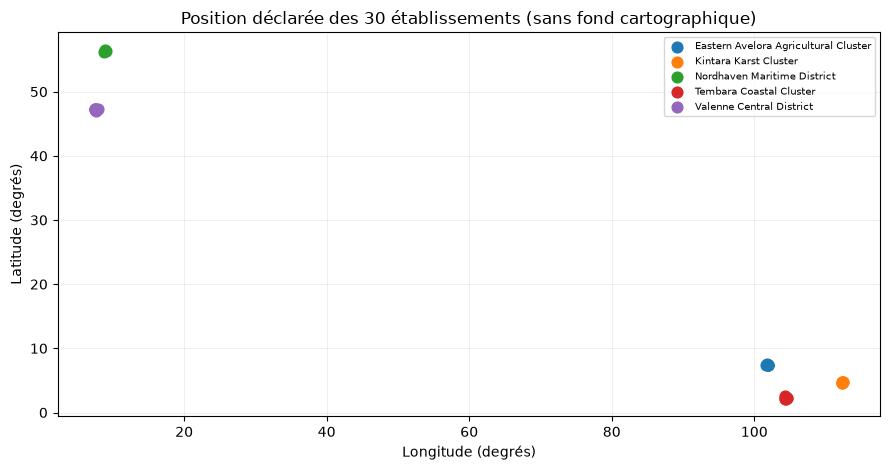

Expéditions avec durée calculable : 433
Distance directe / durée : Pearson = 0.018 — Spearman = 0.014


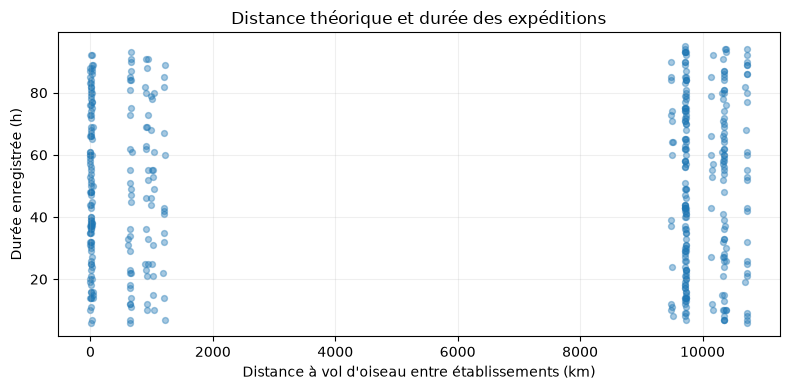

In [48]:
fac_geo = pd.read_csv(root / "data/processed/logistics/erp_facilities.csv")
fac_geo["latitude"] = pd.to_numeric(fac_geo["latitude"])
fac_geo["longitude"] = pd.to_numeric(fac_geo["longitude"])
fig, ax = plt.subplots(figsize=(9, 4.8))
for region, valeurs in fac_geo.groupby("region"):
    ax.scatter(valeurs["longitude"], valeurs["latitude"], label=region, s=60)
ax.set_xlabel("Longitude (degrés)")
ax.set_ylabel("Latitude (degrés)")
ax.set_title("Position déclarée des 30 établissements (sans fond cartographique)")
ax.legend(fontsize=7, loc="best")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

s_geo = pd.read_csv(root / "data/processed/logistics/shipments.csv")
coord = fac_geo.set_index("facility_code")[["latitude", "longitude"]]
for cote, cle in [("depart", "origin_facility_code"), ("arrivee", "destination_facility_code")]:
    s_geo[cote + "_lat"] = s_geo[cle].map(coord["latitude"])
    s_geo[cote + "_lon"] = s_geo[cle].map(coord["longitude"])

# Haversine : distance la plus courte sur la sphère, en kilomètres.
lat1, lat2 = np.radians(s_geo["depart_lat"]), np.radians(s_geo["arrivee_lat"])
dlat = lat2 - lat1
dlon = np.radians(s_geo["arrivee_lon"] - s_geo["depart_lon"])
a_hav = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
s_geo["distance_directe_km"] = 6371 * 2 * np.arcsin(np.sqrt(np.clip(a_hav, 0, 1)))
s_geo["duree_heures"] = (
    pd.to_datetime(s_geo["arrival_time_normalized"], errors="coerce")
    - pd.to_datetime(s_geo["dispatch_time_normalized"])
).dt.total_seconds() / 3600
arrivees_geo = s_geo.dropna(subset=["distance_directe_km", "duree_heures"])
print("Expéditions avec durée calculable :",len(arrivees_geo))
print("Distance directe / durée : Pearson =",round(arrivees_geo["distance_directe_km"].corr(arrivees_geo["duree_heures"]), 3),
      "— Spearman =",round(arrivees_geo["distance_directe_km"].rank().corr(arrivees_geo["duree_heures"].rank()), 3))
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(arrivees_geo["distance_directe_km"], arrivees_geo["duree_heures"],
           s=18, alpha=0.4)
ax.set_xlabel("Distance à vol d'oiseau entre établissements (km)")
ax.set_ylabel("Durée enregistrée (h)")
ax.set_title("Distance théorique et durée des expéditions")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Interprétation spatiale.** Les établissements se répartissent en **cinq régions déclarées**. Pour les **433 expéditions avec arrivée**, la corrélation entre la distance directe et la durée est très faible (Pearson **0,018** ; Spearman **0,014**). Sans distances routières, correspondances de transport et informations de trajet, on ne peut pas calculer des temps attendus fiables.

### CM6 — Fouille de texte : mots caractéristiques avec TF-IDF

Les fichiers contiennent **30 mémos internes** et **27 documents signalés publics**. On peut comparer leur vocabulaire avec **TF-IDF**, comme dans le cours : un mot est plus intéressant s'il apparaît souvent dans certains documents mais pas dans tous. On retire des mots courants de liaison, sans utiliser de modèle de langage.

Les mémos ont des niveaux de diffusion internes ou restreints : on ne reproduit **pas leur texte intégral** dans les graphiques. Les termes mis en avant sont des indices de vocabulaire, **pas des preuves des événements racontés**. On ne fait pas de LDA sur ce petit corpus : le nombre de thèmes serait difficile à justifier.

Corpus analysé : 30 mémos et 27 documents publics


,terme,TF_IDF_moyen_memos,TF_IDF_moyen_public
0,supplier,0.116,0.000
1,ordinary,0.153,0.046
2,owner,0.104,0.000
3,shipment,0.101,0.002
4,procurement,0.098,0.000
5,posting,0.097,0.000
6,adjustment,0.097,0.000
7,inventory,0.096,0.000
8,timing,0.092,0.002
9,substitution,0.087,0.000


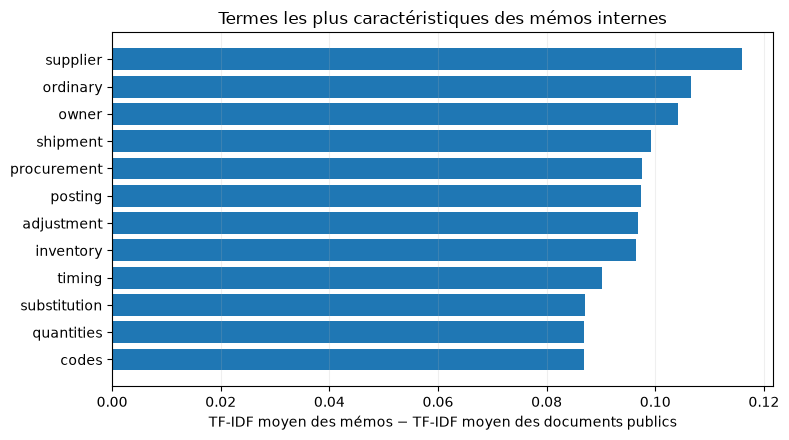

In [49]:
import re
from collections import Counter

memos_texte = pd.read_csv(root / "data/public_records/institutional_memos.csv")
public_texte = pd.read_csv(root / "data/public_records/public_and_investigative_documents.csv")
public_texte = public_texte.loc[public_texte["public_or_restricted"].eq("public")].copy()
textes = list(memos_texte["text"].fillna("")) + list(public_texte["text"].fillna(""))
groupes_texte = np.array(["memos"] * len(memos_texte) + ["public"] * len(public_texte))
stopwords = set("the and for with from this that those these have has had are was were its into about their there they them which each should could would been being on of to in by as or at is it be a an we you our also all one not may such than any can do did but then when while during after before under above between over and without through will only per report record data based upon however additional each same into within including".split())

def decouper_texte(texte):
    return [mot for mot in re.findall(r"[a-z]{3,}", str(texte).lower())
            if mot not in stopwords]

comptages_texte = [Counter(decouper_texte(t)) for t in textes]
frequence_document = Counter(mot for c in comptages_texte for mot in c)
vocabulaire_texte = sorted(mot for mot, nombre in frequence_document.items() if nombre >= 3)
N_texte = len(textes)
# TF normalisé + IDF lissé ; normalisation euclidienne des vecteurs de documents.
idf = {mot: np.log((N_texte + 1) / (frequence_document[mot] + 1)) + 1
       for mot in vocabulaire_texte}
M_texte = np.array([[c.get(mot, 0) * idf[mot] for mot in vocabulaire_texte]
                    for c in comptages_texte], dtype=float)
M_texte = M_texte / np.maximum(np.linalg.norm(M_texte, axis=1, keepdims=True), 1e-12)
scores_memos = M_texte[groupes_texte == "memos"].mean(axis=0)
scores_publics = M_texte[groupes_texte == "public"].mean(axis=0)
difference_tfidf = scores_memos - scores_publics
vocab_top = np.argsort(difference_tfidf)[-12:][::-1]
resultats_texte = pd.DataFrame({
    "terme": [vocabulaire_texte[j] for j in vocab_top],
    "TF_IDF_moyen_memos": scores_memos[vocab_top],
    "TF_IDF_moyen_public": scores_publics[vocab_top],
}).round(3)
print("Corpus analysé :",len(memos_texte),"mémos et",len(public_texte),"documents publics")
display(resultats_texte)
fig, ax = plt.subplots(figsize=(8, 4.5))
ordre = list(reversed(vocab_top))
ax.barh([vocabulaire_texte[j] for j in ordre], difference_tfidf[ordre])
ax.set_xlabel("TF-IDF moyen des mémos − TF-IDF moyen des documents publics")
ax.set_title("Termes les plus caractéristiques des mémos internes")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

**Interprétation textuelle.** Les **30 mémos** et **27 documents publics** n'ont pas le même vocabulaire. Les termes « supplier », « shipment », « procurement », « adjustment » ou « inventory » sont plus caractéristiques des mémos selon le TF-IDF moyen. Ce n'est **pas** une validation de leur contenu ni une classification fiable de leurs sujets. Les textes internes ne sont pas reproduits.

### Couverture des CM et limites des méthodes

| Séance | Méthodes appliquées ici | Limites ou méthodes non retenues |
|---|---|---|
| **CM1 — Nettoyage et statistiques** | Doublons, normalisation, données manquantes, statistiques descriptives, Pearson/Spearman, figures | Corrélation ≠ causalité ; certaines variables et unités ne sont pas comparables |
| **CM2 — Regroupement** | Standardisation, PCA, K-Means (plusieurs k), DBSCAN (plusieurs rayons), silhouette | Pas de t-SNE : la PCA explique déjà une grande part de la variance de nos six indicateurs et nous n'avons que 30 établissements ; pas besoin d'un second algorithme de projection complexe |
| **CM3 — Motifs et anomalies** | IQR, LOF, Apriori, support, confiance, lift, comparaison des seuils | On ne refait pas FP-Growth ou Eclat : même objectif de recherche d'itemsets sur 450 transactions ; pas de vérité terrain pour évaluer les alertes |
| **CM4 — Graphes et processus** | Graphes dirigés/pondérés, centralités, communautés gloutonnes et Louvain, DFG, variantes, score de dépendance | Le graphe d'activités est exploratoire : pas de procédure officielle ni de journal opérationnel complet pour mesurer la conformité ; Infomap/Girvan-Newman non nécessaires pour ce premier réseau |
| **CM5 — Spatial et temporel** | Cartographie par coordonnées, Haversine, chronologie mensuelle, Pearson/Spearman, autocorrélation | Distances à vol d'oiseau, pas d'itinéraires ; stocks mensuels trop irréguliers pour une décomposition fiable ; pas de prévisions SARIMA/STL justifiées |
| **CM6 — Texte** | Prétraitement de mots, fréquences, TF-IDF sur mémos et documents publics | Petit corpus, pas de thématiques validées pour choisir un modèle LDA/LSA ; textes internes non reproduits |

**À retenir :** on a maintenant **testé les grandes familles de méthodes du cours qui peuvent s'appliquer à notre corpus**. On n'a pas cherché à lancer tous les algorithmes cités dans les CM : certains sont des alternatives à une méthode déjà testée, d'autres nécessitent des données ou une vérité terrain qu'on ne possède pas. Les paramètres exploratoires (k, distance DBSCAN, support) sont donnés pour permettre de refaire les calculs.

**Supports consultés :** diapositives 2026 de l'UE, CM1 à CM6, accessibles depuis [la page du cours de Data Mining](https://a-t-richard.github.io/teaching/data-mining/). Méthodes retenues : CM1 statistiques/corrélations (diapositives 13–20), CM2 PCA/K-Means/DBSCAN (14–21), CM3 Apriori/IQR/LOF (6–17), CM4 graphes/communautés/processus (12–26), CM5 séries et spatial (4–19), CM6 TF-IDF (4–14). Les méthodes non utilisées ont été justifiées dans le tableau, et non présentées comme déjà testées.


### Figures à reprendre dans le rapport collectif

Notre notebook reste le **carnet complet des tests**, mais le rapport principal n'a pas besoin de tous les graphiques. Je garderais **huit figures**, avec une seule observation claire sous chacune :

1. **Commandes / réceptions** : répartition des 650 commandes, puis histogramme des 65 réceptions partielles.
2. **Stocks** : heatmap des stocks théoriques négatifs par site et catégorie.
3. **Clustering (CM2)** : projection PCA avec les groupes K-Means, en disant comment les six indicateurs ont été normalisés.
4. **Règles d'association (CM3)** : support et lift des règles Apriori, en précisant que certaines associations découlent du codage des données.
5. **Graph Mining (CM4)** : top des flux entre partenaires et comparaison Louvain / glouton.
6. **Process Mining (CM4)** : matrice des activités qui se suivent dans les dossiers réglementaires.
7. **Temporel (CM5)** : courbe mensuelle des commandes/expéditions, avec l'avertissement sur les pics dominants.
8. **Chaîne du froid** : capacités de stockage déclarées aux deux extrémités des expéditions sensibles.

On peut garder la carte des établissements et la figure TF-IDF **en complément**, si le groupe veut couvrir explicitement les CM5 et CM6 dans son rendu. Chaque figure doit être accompagnée de **deux ou trois phrases : ce qu'on a calculé, ce qu'on voit, et ce qu'on ne peut pas en conclure**. Le rapport collectif et ses fichiers restent sous la responsabilité du groupe ; ils n'ont pas été modifiés ici.

## Synthèse de notre partie logistique

Notre objectif était de vérifier ce qu'on peut réellement suivre dans les données : **commandes, réceptions, stocks, expéditions et documents associés**. On a commencé par préparer les données, puis contrôlé les quantités, les liens entre fichiers et les statuts. On a aussi utilisé des graphes pour mieux voir les relations entre acteurs.

Pour lire les résultats, on fait la différence entre : **un écart constaté dans les données**, **un résultat qui dépend de notre formule**, **une valeur statistiquement inhabituelle** et **une situation qu'on ne peut pas vérifier avec les fichiers fournis**. Ce ne sont pas les mêmes niveaux de preuve.

Dans le rendu, on mettra surtout en avant les **stocks**, les **réceptions**, quelques **références documentaires**, la **chaîne du froid déclarée** et le **Graph Mining**. Le corpus est fictif : notre analyse ne porte pas sur des entreprises ou des événements réels.

Synthèse des résultats par domaine et niveau de preuve :


,Thème,Résultat contrôlé,Lecture
0,Commandes / réceptions,65/610 réceptions inférieures (et 40/650 comma...,A — différence des quantités enregistrées
1,Stocks,497/500 résidus non nuls ; 39/500 stocks théor...,B — équation de conservation simplifiée
2,Expéditions,17/450 'in_transit' sans arrivée,"A — absence de date enregistrée, pas durée réelle"
3,Froid,22/107 classes listées aux deux établissements,A pour le référentiel ; D pour la température ...
4,Graphe des partenaires,104/450 expéditions sur les 3 arcs principaux,C — concentration relationnelle exploratoire
5,Registre des partenaires,24/80 immatriculations retrouvées ; 55 command...,A pour le lien ; D pour la légalité historique
6,Procédures réglementaires,7/40 dossiers avec demande d'action enregistrée,A — mentions administratives du corpus
7,Accès aux sites,6/60 dossiers avec refus 'denied' enregistré,"A — décision consignée, non preuve physique"
8,Mémos,23/30 mémos avec référence explicite,"A — référence documentaire, pas corroboration ..."


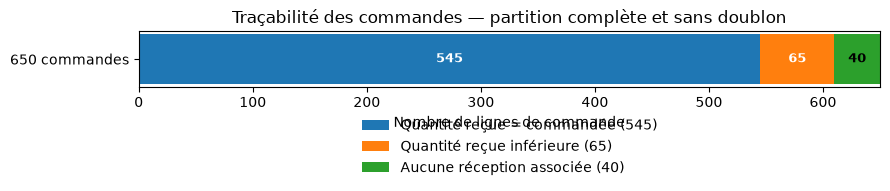

In [50]:
# Tableau de synthèse / chiffres contrôlés à partir des copies traitées — sans écriture de données.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

B = root / "data/processed/logistics"
commandes_bilan = pd.read_csv(B / "purchase_order_lines.csv", dtype=str, keep_default_na=False)
receptions_bilan = pd.read_csv(B / "goods_receipts.csv", dtype=str, keep_default_na=False)
stocks_bilan = pd.read_csv(B / "inventory_month_end.csv", dtype=str, keep_default_na=False)
ajustements_bilan = pd.read_csv(B / "inventory_adjustments.csv", dtype=str, keep_default_na=False)
expeditions_bilan = pd.read_csv(B / "shipments.csv", dtype=str, keep_default_na=False)
partenaires_bilan = pd.read_csv(B / "erp_business_partners.csv", dtype=str, keep_default_na=False)
etablissements_bilan = pd.read_csv(B / "erp_facilities.csv", dtype=str, keep_default_na=False)
memos_bilan = pd.read_csv(root / "data/public_records/institutional_memos.csv", dtype=str, keep_default_na=False)
reglements_bilan = pd.read_csv(root / "data/public_records/regulatory_case_events.csv", dtype=str, keep_default_na=False).drop_duplicates()
acces_bilan = pd.read_csv(root / "data/public_records/site_access_case_events.csv", dtype=str, keep_default_na=False).drop_duplicates()
entites_bilan = pd.read_csv(root / "data/public_records/registered_entities.csv", dtype=str, keep_default_na=False)

# Clé partagée commande-réception : seules les quantités de MEME unité sont comparées.
q = commandes_bilan.merge(
    receptions_bilan[["purchase_order_number", "purchase_order_line", "received_quantity_numeric", "received_unit"]],
    on=["purchase_order_number", "purchase_order_line"], how="left", validate="one_to_one"
)
avec_reception = q["received_quantity_numeric"].notna() & q["received_quantity_numeric"].ne("")
quantite_commandee = pd.to_numeric(q.loc[avec_reception, "ordered_quantity_numeric"], errors="raise")
quantite_recue = pd.to_numeric(q.loc[avec_reception, "received_quantity_numeric"], errors="raise")
n_identiques = int(np.isclose(quantite_recue, quantite_commandee).sum())
n_inferieures = int((quantite_recue < quantite_commandee - 1e-9).sum())
n_sans_reception = int((~avec_reception).sum())

# Stocks : écart strictement PAR RAPPORT À L'ÉQUATION SIMPLIFIÉE, non perte de marchandise.
colonnes_stock = ["opening_stock_numeric", "received_quantity_numeric", "outgoing_quantity_numeric",
                  "documented_internal_use_numeric", "documented_waste_numeric", "closing_stock_numeric"]
for col in colonnes_stock:
    stocks_bilan[col] = pd.to_numeric(stocks_bilan[col], errors="raise")
stock_theorique = (stocks_bilan["opening_stock_numeric"] + stocks_bilan["received_quantity_numeric"]
                  - stocks_bilan["outgoing_quantity_numeric"]
                  - stocks_bilan["documented_internal_use_numeric"] - stocks_bilan["documented_waste_numeric"])
stock_residu = stocks_bilan["closing_stock_numeric"] - stock_theorique
n_stocks_en_ecart = int((~np.isclose(stock_residu, 0, atol=1e-9)).sum())
n_stock_theorique_neg = int(stock_theorique.lt(0).sum())

# Froid : classe de transport explicitement mentionnée dans les capacités de stockage ERP.
cold = expeditions_bilan.loc[
    expeditions_bilan["temperature_control_class_normalized"].isin(["2-8c", "frozen"])
].copy()
for cote, identifiant in [("origine", "origin_facility_code"), ("destination", "destination_facility_code")]:
    valeurs = etablissements_bilan[["facility_code", "storage_capabilities"]].rename(
        columns={"facility_code": identifiant, "storage_capabilities": cote + "_capacites"}
    )
    cold = cold.merge(valeurs, on=identifiant, how="left", validate="many_to_one")
    cold[cote + "_listee"] = cold.apply(
        lambda ligne: ligne["temperature_control_class_normalized"] in {
            x.strip().lower() for x in ligne[cote + "_capacites"].split(";") if x.strip()
        }, axis=1,
    )
n_froid_deux_cotes = int((cold["origine_listee"] & cold["destination_listee"]).sum())

# Fréquences des arcs dir. entre partenaires : nombre de lignes, pas de valeur/quantité.
poids_partenaires = expeditions_bilan.groupby(
    ["sender_partner_code", "receiver_partner_code"]
).size().sort_values(ascending=False)

# Registres : présence exacte du numéro, pas statut légitime à une date historique.
registre_erp = partenaires_bilan.merge(
    entites_bilan[["registration_number", "current_status"]],
    left_on="external_registration_number", right_on="registration_number",
    how="left", validate="many_to_one", indicator=True
)
immatriculations_trouvees = int(registre_erp["_merge"].eq("both").sum())
partenaires_dissous = set(registre_erp.loc[
    registre_erp["current_status"].eq("dissolved"), "partner_code"
])
commandes_dissous = int(commandes_bilan["supplier_partner_code"].isin(partenaires_dissous).sum())

# Les dossiers sont les unités d'observation, pas les lignes événementielles.
n_reg_action = reglements_bilan.loc[
    reglements_bilan["new_status"].eq("action_required"), "case_number"
].nunique()
n_access_denied = acces_bilan.loc[
    acces_bilan["new_status"].eq("denied"), "access_case_number"
].nunique()
n_memos_references = int(memos_bilan[[
    "related_purchase_order", "related_shipment_number", "related_case_number"
]].ne("").any(axis=1).sum())

synthese_resultats = pd.DataFrame([
    {"Thème": "Commandes / réceptions", "Résultat contrôlé": f"{n_inferieures}/610 réceptions inférieures (et {n_sans_reception}/650 commandes sans réception)", "Lecture": "A — différence des quantités enregistrées"},
    {"Thème": "Stocks", "Résultat contrôlé": f"{n_stocks_en_ecart}/500 résidus non nuls ; {n_stock_theorique_neg}/500 stocks théoriques négatifs", "Lecture": "B — équation de conservation simplifiée"},
    {"Thème": "Expéditions", "Résultat contrôlé": f"{int(expeditions_bilan['shipment_status_normalized'].eq('in_transit').sum())}/450 'in_transit' sans arrivée", "Lecture": "A — absence de date enregistrée, pas durée réelle"},
    {"Thème": "Froid", "Résultat contrôlé": f"{n_froid_deux_cotes}/{len(cold)} classes listées aux deux établissements", "Lecture": "A pour le référentiel ; D pour la température réelle"},
    {"Thème": "Graphe des partenaires", "Résultat contrôlé": f"{int(poids_partenaires.head(3).sum())}/450 expéditions sur les 3 arcs principaux", "Lecture": "C — concentration relationnelle exploratoire"},
    {"Thème": "Registre des partenaires", "Résultat contrôlé": f"{immatriculations_trouvees}/80 immatriculations retrouvées ; {commandes_dissous} commandes avec 6 acteurs actuellement 'dissolved'", "Lecture": "A pour le lien ; D pour la légalité historique"},
    {"Thème": "Procédures réglementaires", "Résultat contrôlé": f"{n_reg_action}/40 dossiers avec demande d'action enregistrée", "Lecture": "A — mentions administratives du corpus"},
    {"Thème": "Accès aux sites", "Résultat contrôlé": f"{n_access_denied}/60 dossiers avec refus 'denied' enregistré", "Lecture": "A — décision consignée, non preuve physique"},
    {"Thème": "Mémos", "Résultat contrôlé": f"{n_memos_references}/30 mémos avec référence explicite", "Lecture": "A — référence documentaire, pas corroboration externe"},
])
print("Synthèse des résultats par domaine et niveau de preuve :")
display(synthese_resultats)

# La seule figure finale réutilise UNE population et des groupes disjoints : 650 commandes.
fig, ax = plt.subplots(figsize=(9, 2.5))
categories = ["Quantité reçue = commandée", "Quantité reçue inférieure", "Aucune réception associée"]
effectifs = [n_identiques, n_inferieures, n_sans_reception]
left = 0
for categorie, nombre in zip(categories, effectifs):
    ax.barh("650 commandes", nombre, left=left, height=0.5, label=f"{categorie} ({nombre})")
    ax.text(left + nombre / 2, 0, str(nombre), ha="center", va="center", fontsize=9,
            fontweight="bold", color="white" if nombre > 60 else "black")
    left += nombre
ax.set_xlim(0, 650)
ax.set_xlabel("Nombre de lignes de commande")
ax.set_title("Traçabilité des commandes — partition complète et sans doublon")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=1, frameon=False)
plt.tight_layout()
plt.show()


### Les résultats à garder pour le rendu

On peut organiser notre partie autour de **cinq résultats** :

1. **Stocks :** notre formule ne retrouve exactement que **3 stocks finaux sur 500** ; **39 stocks théoriques** sont négatifs. C'est un écart **par rapport à la formule choisie**, qui peut être incomplète.
2. **Commandes et réceptions :** sur **650 commandes**, **610** ont une réception ; **65 réceptions** comportent une quantité inférieure à la commande (écart relatif médian **13 %**). Le graphique récapitulatif permet de voir la répartition.
3. **Traçabilité documentaire :** `ADJ-2018-00014` cite `SHP-2023-00029`, mais plusieurs informations ne correspondent pas. C'est notre meilleur exemple de lien à vérifier avant de l'utiliser.
4. **Chaîne du froid :** **107 expéditions** déclarent une température contrôlée ; pour **22**, la classe figure dans les capacités de stockage des deux établissements. Cela montre un **manque de correspondance documentaire**, pas une température mal respectée.
5. **Graph Mining et dossiers :** les trois principaux flux partenaires comptent **104 des 450 expéditions**. Les communautés dépendent de la méthode. Les **40 dossiers réglementaires** ne se résument pas à leur statut `closed` : **7** comportent une demande d'action.

Les autres contrôles (prix atypiques, dates d'arrivée manquantes, autorisations, doublons) sont utiles en complément, mais on n'a pas besoin de tous les présenter dans le rapport principal.

### Conclusion proposée pour le rapport

On a étudié les fichiers logistiques en commençant par nettoyer les données, puis en vérifiant les commandes, les réceptions, les stocks et les expéditions. **65 réceptions sur 610** présentent une quantité inférieure à la commande associée. Pour les stocks, **497 relevés sur 500** ne correspondent pas à notre équation de conservation simplifiée.

Les graphes montrent que certains partenaires et établissements reviennent souvent dans les échanges. Pour les expéditions à température contrôlée, les capacités de stockage déclarées ne couvrent pas explicitement tous les trajets. Enfin, le rapprochement avec les mémos et les dossiers fait ressortir quelques références et dates à vérifier.

**Notre analyse montre surtout des différences entre les fichiers et des limites de traçabilité.** Elle ne permet pas de conclure à une fraude, à une perte physique ou à une rupture de la chaîne du froid. Il manque notamment une clé directe entre réception et expédition, certaines règles de gestion et des mesures de température.

Cette partie peut servir de base au rendu collectif. Il reste à **choisir les figures**, **simplifier le code** et **harmoniser notre présentation avec celle du groupe**.